# Loan word classification experiments - Colab edition

**Runtime → Change runtime type → GPU (T4).**

1. Run the setup cells (top to bottom). You will be asked to upload the dataset **.zip**, then the **.json** files.
2. Run any evaluation cell. When it finishes, a zip with that evaluation's results folder downloads automatically.
3. Unzip it into your local `Final_results` folder - the tree matches, so it merges.

In [1]:
#@title Config { display-mode: "form" }
FEATURE_SET = "all"  #@param ["all", "wo_dnnlogits_cosims"]
RESULTS_DIRNAME = "Final_results"  #@param {type:"string"}

In [2]:
import os, io, sys, json, shutil, zipfile, random, pprint
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import sklearn as sk
from sklearn.linear_model import LogisticRegression
from sklearn import svm
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV, StratifiedShuffleSplit, train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import precision_recall_fscore_support as score
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, classification_report, confusion_matrix

import torch
from torch import nn
from torch import optim

try:
    from google.colab import files
    IN_COLAB = True
except ImportError:          # lets you test the notebook outside Colab
    IN_COLAB = False

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using {device} device")
if IN_COLAB and device == "cpu":
    print("WARNING: no GPU. Runtime -> Change runtime type -> GPU if you want the NN to train on it.")

Using cuda device


## 1. Upload the dataset

In [3]:
import zipfile, shutil
WORK_DIR = "/content/loanword_data" if IN_COLAB else os.path.abspath("./loanword_data")

print("Select your dataset .zip:")
uploaded = files.upload()
for fname in list(uploaded):
    if fname.lower().endswith(".zip"):
        print("Unzipping", fname)
        with zipfile.ZipFile(fname) as z:
            z.extractall(WORK_DIR)
        os.remove(fname)
del uploaded

DATA_DIR = None
for dp, dns, fns in os.walk(WORK_DIR):
    if os.path.basename(dp) == "production_train_test":
        DATA_DIR = dp
        break
assert DATA_DIR, "No 'production_train_test' folder found in the zip"
print("DATA_DIR:", DATA_DIR)

Select your dataset .zip:


Saving production_train_test.zip to production_train_test.zip
Unzipping production_train_test.zip
DATA_DIR: /content/loanword_data/production_train_test


Now upload the json file(s): `language-pairs.json` (and `language-pairs-holdout.json` if you run the holdout evaluation). You can select both at once.

In [22]:
uploaded = files.upload()
del uploaded
PAIRS_JSON = "language-pairs.json"
HOLDOUT_JSON = "language-pairs-holdout.json"
assert os.path.exists(PAIRS_JSON), "language-pairs.json was not uploaded"

Saving language-pairs.json to language-pairs (1).json


## 2. Feature set and results helpers

In [5]:
FEATURE_SETS = {
    "all": dict(
        folder="",
        features=["Fast Levenshtein Distance Div Maxlen",
                  "Dolgo Prime Distance Div Maxlen",
                  "Feature Edit Distance Div Maxlen",
                  "Hamming Feature Distance Div Maxlen",
                  "Weighted Feature Distance Div Maxlen",
                  "Partial Hamming Feature Distance Div Maxlen",
                  "plain Levenshtein",
                  "DNN_logits",
                  "MBERT_cos_sim",
                  "XLM_cos_sim"]),
    "wo_dnnlogits_cosims": dict(
        folder="features_wo_dnnlogits_cosims",
        features=["Fast Levenshtein Distance Div Maxlen",
                  "Dolgo Prime Distance Div Maxlen",
                  "Feature Edit Distance Div Maxlen",
                  "Hamming Feature Distance Div Maxlen",
                  "Weighted Feature Distance Div Maxlen",
                  "Partial Hamming Feature Distance Div Maxlen",
                  "plain Levenshtein"]),
    # add your own, e.g.:
    # "lev_dnn_cosims": dict(folder="features_lev_dnn_cosims",
    #                        features=["plain Levenshtein", "DNN_logits", "MBERT_cos_sim", "XLM_cos_sim"]),
}
base_features = FEATURE_SETS[FEATURE_SET]["features"]
FEATURE_FOLDER = FEATURE_SETS[FEATURE_SET]["folder"]
print("Feature set:", FEATURE_SET, "->", FEATURE_FOLDER or "(no feature sub-folder)")

labels = ["label_bin"]

# ---------------- results tree: everything is written under RESULTS_ROOT ----------------
OUT_BASE = "/content" if IN_COLAB else os.path.abspath("./colab_out")
RESULTS_ROOT = os.path.join(OUT_BASE, RESULTS_DIRNAME)
ZIP_DIR = os.path.join(OUT_BASE, "result_zips")
os.makedirs(RESULTS_ROOT, exist_ok=True)
os.makedirs(ZIP_DIR, exist_ok=True)

def _join(*parts):
    return os.path.join(*[p for p in parts if p])

def result_dir(split, model):
    """<root>/<split>/[<feature folder>/]<Model>_results   (split: all_data | real_dist | balanced)"""
    return _join(RESULTS_ROOT, split, FEATURE_FOLDER, f"{model}_results")

def holdout_dir(split):
    """<root>/holdout/<split>/[<feature folder>]"""
    return _join(RESULTS_ROOT, "holdout", split, FEATURE_FOLDER)

def pruned_dir():
    """<root>/pruned_nn[/<feature folder>/NN_results]"""
    return _join(RESULTS_ROOT, "pruned_nn", FEATURE_FOLDER, "NN_results" if FEATURE_FOLDER else "")

def package_and_download(out_dir):
    """Zip ONLY out_dir (tree kept relative to RESULTS_ROOT) and download it."""
    rel = os.path.relpath(out_dir, RESULTS_ROOT)
    zip_path = os.path.join(ZIP_DIR, rel.replace(os.sep, "__") + ".zip")
    with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
        for dp, _, fns in os.walk(out_dir):
            for fn in fns:
                full = os.path.join(dp, fn)
                z.write(full, arcname=os.path.join(RESULTS_DIRNAME, os.path.relpath(full, RESULTS_ROOT)))
    print(f"\nZip ready: {zip_path}  ({os.path.getsize(zip_path)/1024:.0f} KB)")
    with zipfile.ZipFile(zip_path) as z:
        for n in z.namelist():
            print("   ", n)
    if IN_COLAB:
        files.download(zip_path)
    return zip_path

_EVAL_FILES = ["final_results.csv",
               "all_lang_falsepos.csv", "all_lang_falseneg.csv",
               "all_lang_pair_eval_falsepos.csv", "all_lang_pair_eval_falseneg.csv",
               "indiv_pair_eval_falsepos.csv", "indiv_pair_eval_falseneg.csv"]

def save_eval_results(out_dir, *results, weights_name=None):
    """Write the 7 standard csvs (+ weights csv for LR/SVM), then zip + download this folder only."""
    os.makedirs(out_dir, exist_ok=True)
    for fname, df in zip(_EVAL_FILES, results[:7]):
        df.to_csv(os.path.join(out_dir, fname))
    if weights_name is not None:
        results[7].to_csv(os.path.join(out_dir, weights_name))
    return package_and_download(out_dir)

def save_holdout_results(out_dir, final_result, fp, fn):
    os.makedirs(out_dir, exist_ok=True)
    final_result.to_csv(os.path.join(out_dir, "holdout_final_results.csv"))
    fp.to_csv(os.path.join(out_dir, "holdout_falsepos.csv"))
    fn.to_csv(os.path.join(out_dir, "holdout_falseneg.csv"))
    return package_and_download(out_dir)

Feature set: all -> (no feature sub-folder)


## 3. Load the language-pair datasets

In [6]:
with open(PAIRS_JSON, "r") as f:
    pairs = json.load(f)
print(list(pairs))

train_alldata, test_alldata = {}, {}
train_realdist, test_realdist = {}, {}
train_balanced, test_balanced = {}, {}

for pair in pairs:
    print(pair)
    L1 = pairs[pair]["target"]["name"]
    L2 = pairs[pair]["source"]["name"]
    prefix = f"{DATA_DIR}/{L1}-{L2}"

    train_alldata[f"{L1}-{L2}"] = pd.read_csv(f"{prefix}/alldata/{L1}-{L2}-train_production_alldata.csv")
    test_alldata[f"{L1}-{L2}"] = pd.read_csv(f"{prefix}/alldata/{L1}-{L2}-test_production_alldata.csv")

    train_realdist[f"{L1}-{L2}"] = pd.read_csv(f"{prefix}/realdist/{L1}-{L2}-train_production_realdist.csv")
    test_realdist[f"{L1}-{L2}"] = pd.read_csv(f"{prefix}/realdist/{L1}-{L2}-test_production_realdist.csv")

    train_balanced[f"{L1}-{L2}"] = pd.read_csv(f"{prefix}/balanced/{L1}-{L2}-train_production_balanced.csv")
    test_balanced[f"{L1}-{L2}"] = pd.read_csv(f"{prefix}/balanced/{L1}-{L2}-test_production_balanced.csv")

['Hindi-Persian', 'English-French', 'Finnish-Swedish', 'Kazakh-Russian', 'Azerbaijani-Arabic', 'Chinese-English', 'German-French', 'English-German', 'Romanian-Hungarian', 'Polish-French', 'Indonesian-Dutch', 'Romanian-French']
Hindi-Persian
English-French
Finnish-Swedish
Kazakh-Russian
Azerbaijani-Arabic
Chinese-English
German-French
English-German
Romanian-Hungarian
Polish-French
Indonesian-Dutch
Romanian-French


In [7]:
# ---- script one-hot encodings -> final `features` list ----
unicode_list = ["Latin", "Greek", "Cyrillic", "Arabic", "Devanagari", "Bengali", "Gurmukhi", "Tamil", "Telugu",
                "Malayalam", "Myanmar", "Chinese"]
# one-hot per script, aligned with the column names used below.
# (The previous np.unique-based construction produced vectors in sorted order while the
# column names used the original order, and the first-letter column scheme collides for
# Greek/Gurmukhi, Cyrillic/Chinese, Tamil/Telugu, Malayalam/Myanmar -> duplicate columns.)
unicode_map = {w: [int(u == w) for u in unicode_list] for w in unicode_list}

def add_unicode_onehots(df):
    loan = pd.DataFrame(df["loan_unicode"].map(unicode_map).tolist(),
                        columns=[f"loan_unicode_{w}" for w in unicode_list], index=df.index)
    orig = pd.DataFrame(df["original_unicode"].map(unicode_map).tolist(),
                        columns=[f"original_unicode_{w}" for w in unicode_list], index=df.index)
    return pd.concat([df, loan, orig], axis=1)

for split_dict in (train_alldata, test_alldata, train_realdist, test_realdist, train_balanced, test_balanced):
    for k in split_dict:
        split_dict[k] = add_unicode_onehots(split_dict[k])

features = list(base_features)
# full script names (first-letter scheme collides: Greek/Gurmukhi, Cyrillic/Chinese, ...)
features.extend([f"loan_unicode_{w}" for w in unicode_list])
features.extend([f"original_unicode_{w}" for w in unicode_list])
print(len(features), "features in total")

34 features in total


# Evaluation functions

In [8]:
def classification_report_csv(report, language_pair, all_lang=False, train_evaluate_pair =True):
    #if language_pair ==True:

        #language_pair = pair

    report_data = []
    lines = report.split('\n')
    #print("lines",len(lines))
    #print(lines)
    for i, line in enumerate(lines[2:-3]):

        if i ==0 or i==1:
            #print("i", i)


           #print("actual lines",line)
            row = {}
            #row_data = line.split('      ')
            row_data = line.split(' ')
            row_data = list(filter(None, row_data))
            #print(row_data)
            #print("rowdata",row_data[4] )
        row['all_language_evaluate'] = all_lang
        row['train_evaluate_pair'] = train_evaluate_pair
        row['language_pair'] = language_pair
        row['class'] = row_data[0]
        row['precision'] = float(row_data[1])
        row['recall'] = float(row_data[2])
        row['f1_score'] = float(row_data[3])
        row['support'] = float(row_data[4])

        if i==3:
            #print("actual lines", line)
            #print("i", i)
            row_data = line.split(' ')
            row_data = list(filter(None, row_data))
            row['acc'] = float(row_data[1])

        report_data.append(row)
    print("final report", report_data[0:2])
    dataframe = pd.DataFrame.from_dict(report_data[0:2])
    return dataframe
    #dataframe.to_csv((f'{pair}-class_report.csv'), index=False)
    #class_report.to_csv((f'{pair}-class_report.csv'), index=False)



# Logistic Regression classifier

In [9]:
def lr_evaluate(full_train_set, full_test_set, pairs_list):
    all_result = []
    all_lang_fp_list= []
    all_lang_fn_list=[]
    evaluate_lang_fp_list = []
    evaluate_lang_fn_list = []
    train_evaluate_lang_fp_list = []
    train_evaluate_lang_fn_list = []
    weights_list = []

    pair ='All languages' #pair None for all languages evaluation




    display_fields = ['loan_word',
              'original_word',
              'loan_word_epitran',
              'original_word_epitran',
              'loan_english',
              'original_english'] + features

    train_set = pd.concat([full_train_set[pair][display_fields + ["label"] + labels] for pair in pairs])
    x_train = train_set[features].values
    x_means = np.mean(x_train, axis=0)
    x_stds = np.std(x_train, axis=0)
    x_stds[x_stds == 0] = 1
    y_train = train_set[labels].values.ravel()

    test_set = pd.concat([full_test_set[pair][display_fields + ["label"] + labels] for pair in pairs])
    x_test = test_set[features].values
    y_test = test_set[labels].values.ravel()

    # standardize input features
    x_train = (x_train - x_means)/x_stds

    print("Training on all langs\n")
    LR = LogisticRegression(random_state=1, solver='lbfgs', max_iter=500).fit(x_train, y_train)

    # display regressor weights
    df = pd.DataFrame(LR.coef_, columns=features).style.set_caption('Weights')
    df_weights = pd.DataFrame(LR.coef_, columns=features)

    df_weights.insert(0, 'language_pair', pair)

    weights_list.append(df_weights)

    display(df)
    print()

    print("Evaluating on all langs")
    x_test = (x_test - x_means)/x_stds
    y_pred = LR.predict(x_test)

    print("f1-score : ", f1_score(y_test, y_pred ))
    print("precision : ",precision_score(y_test, y_pred))
    print("recall : ",recall_score(y_test, y_pred ))
    print("accuracy : ",accuracy_score(y_test, y_pred))
    print(classification_report(y_test, y_pred, output_dict=True))
    #class_report = classification_report(y_test, y_pred)
    #a = classification_report_csv(class_report,pair , all_lang=True)
    print(confusion_matrix(y_test, y_pred))
    class_report = classification_report(y_test, y_pred)
    a = classification_report_csv(class_report,pair,all_lang=True, train_evaluate_pair =False)
    all_result.append(a)

    #all_result.append(a)
    #class_report = classification_report(y_test, y_pred, output_dict=True)

    print()

    # display false positives and false negatives
    unq = np.array([x + 2*y for x, y in zip(y_pred, y_test)])
    tp = np.array(np.where(unq == 3)).tolist()[0]
    fp = np.array(np.where(unq == 1)).tolist()[0]
    tn = np.array(np.where(unq == 0)).tolist()[0]
    fn = np.array(np.where(unq == 2)).tolist()[0]

    #display(test_set.reset_index(drop=True).iloc[fp,:][display_fields + ["label"]].style.set_caption('False positives'))
    #display(test_set.reset_index(drop=True).iloc[fn,:][display_fields + ["label"]].style.set_caption('False negatives'))
    all_lang_fp = test_set.reset_index(drop=True).iloc[fp,:][display_fields + ["label"]]
    all_lang_fn = test_set.reset_index(drop=True).iloc[fn,:][display_fields + ["label"]]
    all_lang_fp.insert(0, 'language_pair', pair)
    all_lang_fn.insert(0, 'language_pair', pair)
    all_lang_fp_list.append(all_lang_fp)
    all_lang_fn_list.append(all_lang_fn)
    for pair in pairs_list:
        print(f'Evaluating on {pair}')

        test_set = full_test_set[pair][display_fields + ["label"] + labels]
        x_test = test_set[features].values
        y_test = test_set[labels].values.ravel()

        x_test = (x_test - x_means)/x_stds
        y_pred = LR.predict(x_test)

        print("f1-score : ", f1_score(y_test, y_pred ))
        print("precision : ",precision_score(y_test, y_pred))
        print("recall : ",recall_score(y_test, y_pred ))
        print("accuracy : ",accuracy_score(y_test, y_pred))
        print(classification_report(y_test, y_pred))
        class_report = classification_report(y_test, y_pred)
        a = classification_report_csv(class_report,pair,all_lang=False, train_evaluate_pair =False)
        all_result.append(a)

        #class_report = pd.DataFrame(class_report).transpose()
        #class_report.to_csv('lr_alllang_report.csv', index=False)

        print(confusion_matrix(y_test, y_pred))
        print()

        # display false positives and false negatives
        unq = np.array([x + 2*y for x, y in zip(y_pred, y_test)])
        tp = np.array(np.where(unq == 3)).tolist()[0]
        fp = np.array(np.where(unq == 1)).tolist()[0]
        tn = np.array(np.where(unq == 0)).tolist()[0]
        fn = np.array(np.where(unq == 2)).tolist()[0]

        #display(test_set.reset_index(drop=True).iloc[fp,:][display_fields + ["label"]].style.set_caption('False positives'))
        #display(test_set.reset_index(drop=True).iloc[fn,:][display_fields + ["label"]].style.set_caption('False negatives'))
        evaluate_lang_fp = test_set.reset_index(drop=True).iloc[fp,:][display_fields + ["label"]]
        evaluate_lang_fn = test_set.reset_index(drop=True).iloc[fn,:][display_fields + ["label"]]
        evaluate_lang_fp.insert(0, 'language_pair', pair)
        evaluate_lang_fn.insert(0, 'language_pair', pair)
        evaluate_lang_fp_list.append(evaluate_lang_fp)
        evaluate_lang_fn_list.append(evaluate_lang_fn)

    for pair in pairs_list:
        print(f'Training and evaluating on {pair}')

        train_set = full_train_set[pair][display_fields + ["label"] + labels]
        x_train = train_set[features].values
        x_means = np.mean(x_train, axis=0)
        x_stds = np.std(x_train, axis=0)
        x_stds[x_stds == 0] = 1
        y_train = train_set[labels].values.ravel()

        test_set = full_test_set[pair][display_fields + ["label"] + labels]
        x_test = test_set[features].values
        y_test = test_set[labels].values.ravel()

        x_train = (x_train - x_means)/x_stds

        LR = LogisticRegression(random_state=1, solver='lbfgs', max_iter=500).fit(x_train, y_train)

        # display regressor weights
        df = pd.DataFrame(LR.coef_, columns=features).style.set_caption('Weights')
        df_weights = pd.DataFrame(LR.coef_, columns=features)
        df_weights.insert(0, 'language_pair', pair)
        weights_list.append(df_weights)
        display(df)

        x_test = (x_test - x_means)/x_stds
        y_pred = LR.predict(x_test)

        print("f1-score : ", f1_score(y_test, y_pred ))
        print("precision : ",precision_score(y_test, y_pred))
        print("recall : ",recall_score(y_test, y_pred ))
        print("accuracy : ",accuracy_score(y_test, y_pred))
        #print(classification_report(y_test, y_pred))
        print(classification_report(y_test, y_pred, output_dict=True))
        #class_report = classification_report(y_test, y_pred, output_dict=True)
        #class_report = pd.DataFrame(class_report).transpose()
        #class_report.to_csv((f'{pair}-class_report.csv'), index=False)
        print(confusion_matrix(y_test, y_pred))
        class_report = classification_report(y_test, y_pred)
        a = classification_report_csv(class_report,pair,all_lang=False,train_evaluate_pair =True)
        all_result.append(a)
        print()

        # display false positives and false negatives
        unq = np.array([x + 2*y for x, y in zip(y_pred, y_test)])
        tp = np.array(np.where(unq == 3)).tolist()[0]
        fp = np.array(np.where(unq == 1)).tolist()[0]
        tn = np.array(np.where(unq == 0)).tolist()[0]
        fn = np.array(np.where(unq == 2)).tolist()[0]

        #display(test_set.reset_index(drop=True).iloc[fp,:][display_fields + ["label"]].style.set_caption('False positives'))
        #display(test_set.reset_index(drop=True).iloc[fn,:][display_fields + ["label"]].style.set_caption('False negatives'))
        train_evaluate_lang_fp = test_set.reset_index(drop=True).iloc[fp,:][display_fields + ["label"]]
        train_evaluate_lang_fn = test_set.reset_index(drop=True).iloc[fn,:][display_fields + ["label"]]
        train_evaluate_lang_fp.insert(0, 'language_pair', pair)
        train_evaluate_lang_fn.insert(0, 'language_pair', pair)
        train_evaluate_lang_fp_list.append(train_evaluate_lang_fp)
        train_evaluate_lang_fn_list.append(train_evaluate_lang_fn)
    final_result = pd.concat(all_result, ignore_index=True)
    all_lang_fp_list = pd.concat(all_lang_fp_list, ignore_index=True)
    all_lang_fn_list = pd.concat(all_lang_fn_list, ignore_index=True)
    evaluate_lang_fp_list = pd.concat(evaluate_lang_fp_list, ignore_index=True)
    evaluate_lang_fn_list = pd.concat(evaluate_lang_fn_list, ignore_index=True)
    train_evaluate_lang_fp_list = pd.concat(train_evaluate_lang_fp_list, ignore_index=True)
    train_evaluate_lang_fn_list = pd.concat(train_evaluate_lang_fn_list, ignore_index=True)
    weights = pd.concat(weights_list, ignore_index=True)

    return final_result, all_lang_fp_list, all_lang_fn_list, evaluate_lang_fp_list, evaluate_lang_fn_list, train_evaluate_lang_fp_list, train_evaluate_lang_fn_list, weights

### LR - all_data

In [10]:
print("Evaluating LR on all_data splits\n")
results = lr_evaluate(train_alldata, test_alldata, pairs)
save_eval_results(result_dir("all_data", "LR"), *results, weights_name="LR_weights.csv")

Evaluating LR on all_data splits

Training on all langs



,Fast Levenshtein Distance Div Maxlen,Dolgo Prime Distance Div Maxlen,Feature Edit Distance Div Maxlen,Hamming Feature Distance Div Maxlen,Weighted Feature Distance Div Maxlen,Partial Hamming Feature Distance Div Maxlen,plain Levenshtein,DNN_logits,MBERT_cos_sim,XLM_cos_sim,loan_unicode_Latin,loan_unicode_Greek,loan_unicode_Cyrillic,loan_unicode_Arabic,loan_unicode_Devanagari,loan_unicode_Bengali,loan_unicode_Gurmukhi,loan_unicode_Tamil,loan_unicode_Telugu,loan_unicode_Malayalam,loan_unicode_Myanmar,loan_unicode_Chinese,original_unicode_Latin,original_unicode_Greek,original_unicode_Cyrillic,original_unicode_Arabic,original_unicode_Devanagari,original_unicode_Bengali,original_unicode_Gurmukhi,original_unicode_Tamil,original_unicode_Telugu,original_unicode_Malayalam,original_unicode_Myanmar,original_unicode_Chinese
0,-0.265451,-0.275886,0.211711,0.256531,-0.227633,0.218469,-1.134285,6.327082,0.194331,0.451374,0.000000,0.000000,0.416323,-0.131674,-0.136968,0.000000,0.000000,-0.049154,0.000000,0.000000,0.000000,0.000000,0.324364,0.000000,0.000000,-0.131674,0.000000,0.000000,0.000000,-0.178130,0.000000,0.000000,0.000000,0.000000



Evaluating on all langs
f1-score :  0.7494981039482489
precision :  0.8011444921316166
recall :  0.7041072925398156
accuracy :  0.9429572814547671
{'0': {'precision': 0.9598635588402501, 'recall': 0.9758973469741633, 'f1-score': 0.9678140494683443, 'support': 17301.0}, '1': {'precision': 0.8011444921316166, 'recall': 0.7041072925398156, 'f1-score': 0.7494981039482489, 'support': 2386.0}, 'accuracy': 0.9429572814547671, 'macro avg': {'precision': 0.8805040254859333, 'recall': 0.8400023197569895, 'f1-score': 0.8586560767082966, 'support': 19687.0}, 'weighted avg': {'precision': 0.9406273271560524, 'recall': 0.9429572814547671, 'f1-score': 0.941354871025161, 'support': 19687.0}}
[[16884   417]
 [  706  1680]]
final report [{'all_language_evaluate': True, 'train_evaluate_pair': False, 'language_pair': 'All languages', 'class': '0', 'precision': 0.96, 'recall': 0.98, 'f1_score': 0.97, 'support': 17301.0}, {'all_language_evaluate': True, 'train_evaluate_pair': False, 'language_pair': 'All l

,Fast Levenshtein Distance Div Maxlen,Dolgo Prime Distance Div Maxlen,Feature Edit Distance Div Maxlen,Hamming Feature Distance Div Maxlen,Weighted Feature Distance Div Maxlen,Partial Hamming Feature Distance Div Maxlen,plain Levenshtein,DNN_logits,MBERT_cos_sim,XLM_cos_sim,loan_unicode_Latin,loan_unicode_Greek,loan_unicode_Cyrillic,loan_unicode_Arabic,loan_unicode_Devanagari,loan_unicode_Bengali,loan_unicode_Gurmukhi,loan_unicode_Tamil,loan_unicode_Telugu,loan_unicode_Malayalam,loan_unicode_Myanmar,loan_unicode_Chinese,original_unicode_Latin,original_unicode_Greek,original_unicode_Cyrillic,original_unicode_Arabic,original_unicode_Devanagari,original_unicode_Bengali,original_unicode_Gurmukhi,original_unicode_Tamil,original_unicode_Telugu,original_unicode_Malayalam,original_unicode_Myanmar,original_unicode_Chinese
0,-0.875377,-0.460766,-0.039646,-0.087317,-0.308093,0.015841,0.670182,7.559706,-0.004267,0.143536,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


f1-score :  0.7796610169491526
precision :  0.8214285714285714
recall :  0.7419354838709677
accuracy :  0.9577579203899269
{'0': {'precision': 0.9714030384271671, 'recall': 0.98193315266486, 'f1-score': 0.9766397124887691, 'support': 1107.0}, '1': {'precision': 0.8214285714285714, 'recall': 0.7419354838709677, 'f1-score': 0.7796610169491526, 'support': 124.0}, 'accuracy': 0.9577579203899269, 'macro avg': {'precision': 0.8964158049278692, 'recall': 0.8619343182679139, 'f1-score': 0.8781503647189608, 'support': 1231.0}, 'weighted avg': {'precision': 0.9562959434573655, 'recall': 0.9577579203899269, 'f1-score': 0.9567978292662569, 'support': 1231.0}}
[[1087   20]
 [  32   92]]
final report [{'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'Hindi-Persian', 'class': '0', 'precision': 0.97, 'recall': 0.98, 'f1_score': 0.98, 'support': 1107.0}, {'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'Hindi-Persian', 'class': '1', 'precision

,Fast Levenshtein Distance Div Maxlen,Dolgo Prime Distance Div Maxlen,Feature Edit Distance Div Maxlen,Hamming Feature Distance Div Maxlen,Weighted Feature Distance Div Maxlen,Partial Hamming Feature Distance Div Maxlen,plain Levenshtein,DNN_logits,MBERT_cos_sim,XLM_cos_sim,loan_unicode_Latin,loan_unicode_Greek,loan_unicode_Cyrillic,loan_unicode_Arabic,loan_unicode_Devanagari,loan_unicode_Bengali,loan_unicode_Gurmukhi,loan_unicode_Tamil,loan_unicode_Telugu,loan_unicode_Malayalam,loan_unicode_Myanmar,loan_unicode_Chinese,original_unicode_Latin,original_unicode_Greek,original_unicode_Cyrillic,original_unicode_Arabic,original_unicode_Devanagari,original_unicode_Bengali,original_unicode_Gurmukhi,original_unicode_Tamil,original_unicode_Telugu,original_unicode_Malayalam,original_unicode_Myanmar,original_unicode_Chinese
0,0.078524,-0.114900,0.217343,0.341054,-0.064672,0.141808,-2.294192,4.299046,0.399330,0.963461,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


... (20 outputs left out)

f1-score :  0.7531806615776081
precision :  0.7628865979381443
recall :  0.7437185929648241
accuracy :  0.9417067307692307
{'0': {'precision': 0.9653061224489796, 'recall': 0.9686006825938567, 'f1-score': 0.9669505962521294, 'support': 1465.0}, '1': {'precision': 0.7628865979381443, 'recall': 0.7437185929648241, 'f1-score': 0.7531806615776081, 'support': 199.0}, 'accuracy': 0.9417067307692307, 'macro avg': {'precision': 0.864096360193562, 'recall': 0.8561596377793403, 'f1-score': 0.8600656289148687, 'support': 1664.0}, 'weighted avg': {'precision': 0.9410984990249074, 'recall': 0.9417067307692307, 'f1-score': 0.9413855619971836, 'support': 1664.0}}
[[1419   46]
 [  51  148]]
final report [{'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'Romanian-French', 'class': '0', 'precision': 0.97, 'recall': 0.97, 'f1_score': 0.97, 'support': 1465.0}, {'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'Romanian-French', 'class': '1', 'prec

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

'/content/result_zips/all_data__LR_results.zip'

### LR - real_dist

In [11]:
print("Evaluating LR on real_dist splits\n")
results = lr_evaluate(train_realdist, test_realdist, pairs)
save_eval_results(result_dir("real_dist", "LR"), *results, weights_name="LR_weights.csv")

Evaluating LR on real_dist splits

Training on all langs



,Fast Levenshtein Distance Div Maxlen,Dolgo Prime Distance Div Maxlen,Feature Edit Distance Div Maxlen,Hamming Feature Distance Div Maxlen,Weighted Feature Distance Div Maxlen,Partial Hamming Feature Distance Div Maxlen,plain Levenshtein,DNN_logits,MBERT_cos_sim,XLM_cos_sim,loan_unicode_Latin,loan_unicode_Greek,loan_unicode_Cyrillic,loan_unicode_Arabic,loan_unicode_Devanagari,loan_unicode_Bengali,loan_unicode_Gurmukhi,loan_unicode_Tamil,loan_unicode_Telugu,loan_unicode_Malayalam,loan_unicode_Myanmar,loan_unicode_Chinese,original_unicode_Latin,original_unicode_Greek,original_unicode_Cyrillic,original_unicode_Arabic,original_unicode_Devanagari,original_unicode_Bengali,original_unicode_Gurmukhi,original_unicode_Tamil,original_unicode_Telugu,original_unicode_Malayalam,original_unicode_Myanmar,original_unicode_Chinese
0,-0.395563,-0.453258,0.195090,0.300574,-0.277502,0.218748,-1.576310,5.971985,0.014334,0.011362,0.000000,0.000000,0.319304,-0.169496,-0.021914,0.000000,0.000000,-0.054848,0.000000,0.000000,0.000000,0.000000,0.361016,0.000000,0.000000,-0.169496,0.000000,0.000000,0.000000,-0.151726,0.000000,0.000000,0.000000,0.000000



Evaluating on all langs
f1-score :  0.8466175485599464
precision :  0.9058767319636885
recall :  0.7946353730092205
accuracy :  0.9570329601601101
{'0': {'precision': 0.9647380541162924, 'recall': 0.9855179004631331, 'f1-score': 0.9750172733553948, 'support': 13603.0}, '1': {'precision': 0.9058767319636885, 'recall': 0.7946353730092205, 'f1-score': 0.8466175485599464, 'support': 2386.0}, 'accuracy': 0.9570329601601101, 'macro avg': {'precision': 0.9353073930399904, 'recall': 0.8900766367361768, 'f1-score': 0.9108174109576705, 'support': 15989.0}, 'weighted avg': {'precision': 0.9559543206335158, 'recall': 0.9570329601601101, 'f1-score': 0.9558564913576502, 'support': 15989.0}}
[[13406   197]
 [  490  1896]]
final report [{'all_language_evaluate': True, 'train_evaluate_pair': False, 'language_pair': 'All languages', 'class': '0', 'precision': 0.96, 'recall': 0.99, 'f1_score': 0.98, 'support': 13603.0}, {'all_language_evaluate': True, 'train_evaluate_pair': False, 'language_pair': 'All 

,Fast Levenshtein Distance Div Maxlen,Dolgo Prime Distance Div Maxlen,Feature Edit Distance Div Maxlen,Hamming Feature Distance Div Maxlen,Weighted Feature Distance Div Maxlen,Partial Hamming Feature Distance Div Maxlen,plain Levenshtein,DNN_logits,MBERT_cos_sim,XLM_cos_sim,loan_unicode_Latin,loan_unicode_Greek,loan_unicode_Cyrillic,loan_unicode_Arabic,loan_unicode_Devanagari,loan_unicode_Bengali,loan_unicode_Gurmukhi,loan_unicode_Tamil,loan_unicode_Telugu,loan_unicode_Malayalam,loan_unicode_Myanmar,loan_unicode_Chinese,original_unicode_Latin,original_unicode_Greek,original_unicode_Cyrillic,original_unicode_Arabic,original_unicode_Devanagari,original_unicode_Bengali,original_unicode_Gurmukhi,original_unicode_Tamil,original_unicode_Telugu,original_unicode_Malayalam,original_unicode_Myanmar,original_unicode_Chinese
0,-1.310122,-0.579075,-0.014931,-0.154751,-0.266867,0.093342,0.556716,6.273126,0.116811,0.004174,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


f1-score :  0.921161825726141
precision :  0.9487179487179487
recall :  0.8951612903225806
accuracy :  0.9541062801932367
{'0': {'precision': 0.9562289562289562, 'recall': 0.9793103448275862, 'f1-score': 0.9676320272572402, 'support': 290.0}, '1': {'precision': 0.9487179487179487, 'recall': 0.8951612903225806, 'f1-score': 0.921161825726141, 'support': 124.0}, 'accuracy': 0.9541062801932367, 'macro avg': {'precision': 0.9524734524734524, 'recall': 0.9372358175750835, 'f1-score': 0.9443969264916906, 'support': 414.0}, 'weighted avg': {'precision': 0.9539792824816978, 'recall': 0.9541062801932367, 'f1-score': 0.9537134161706308, 'support': 414.0}}
[[284   6]
 [ 13 111]]
final report [{'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'Hindi-Persian', 'class': '0', 'precision': 0.96, 'recall': 0.98, 'f1_score': 0.97, 'support': 290.0}, {'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'Hindi-Persian', 'class': '1', 'precision': 0.95,

,Fast Levenshtein Distance Div Maxlen,Dolgo Prime Distance Div Maxlen,Feature Edit Distance Div Maxlen,Hamming Feature Distance Div Maxlen,Weighted Feature Distance Div Maxlen,Partial Hamming Feature Distance Div Maxlen,plain Levenshtein,DNN_logits,MBERT_cos_sim,XLM_cos_sim,loan_unicode_Latin,loan_unicode_Greek,loan_unicode_Cyrillic,loan_unicode_Arabic,loan_unicode_Devanagari,loan_unicode_Bengali,loan_unicode_Gurmukhi,loan_unicode_Tamil,loan_unicode_Telugu,loan_unicode_Malayalam,loan_unicode_Myanmar,loan_unicode_Chinese,original_unicode_Latin,original_unicode_Greek,original_unicode_Cyrillic,original_unicode_Arabic,original_unicode_Devanagari,original_unicode_Bengali,original_unicode_Gurmukhi,original_unicode_Tamil,original_unicode_Telugu,original_unicode_Malayalam,original_unicode_Myanmar,original_unicode_Chinese
0,-0.236213,-0.012730,-0.162959,1.793624,-0.468207,-0.810397,-3.048621,4.068246,-0.089792,0.065019,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


... (20 outputs left out)

f1-score :  0.9090909090909091
precision :  0.9408602150537635
recall :  0.8793969849246231
accuracy :  0.947289156626506
{'0': {'precision': 0.9497907949790795, 'recall': 0.9763440860215054, 'f1-score': 0.9628844114528102, 'support': 465.0}, '1': {'precision': 0.9408602150537635, 'recall': 0.8793969849246231, 'f1-score': 0.9090909090909091, 'support': 199.0}, 'accuracy': 0.947289156626506, 'macro avg': {'precision': 0.9453255050164215, 'recall': 0.9278705354730643, 'f1-score': 0.9359876602718596, 'support': 664.0}, 'weighted avg': {'precision': 0.947114310935197, 'recall': 0.947289156626506, 'f1-score': 0.946762563606397, 'support': 664.0}}
[[454  11]
 [ 24 175]]
final report [{'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'Romanian-French', 'class': '0', 'precision': 0.95, 'recall': 0.98, 'f1_score': 0.96, 'support': 465.0}, {'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'Romanian-French', 'class': '1', 'precision': 0.94

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

'/content/result_zips/real_dist__LR_results.zip'

### LR - balanced

In [12]:
print("Evaluating LR on balanced splits\n")
results = lr_evaluate(train_balanced, test_balanced, pairs)
save_eval_results(result_dir("balanced", "LR"), *results, weights_name="LR_weights.csv")

Evaluating LR on balanced splits

Training on all langs



,Fast Levenshtein Distance Div Maxlen,Dolgo Prime Distance Div Maxlen,Feature Edit Distance Div Maxlen,Hamming Feature Distance Div Maxlen,Weighted Feature Distance Div Maxlen,Partial Hamming Feature Distance Div Maxlen,plain Levenshtein,DNN_logits,MBERT_cos_sim,XLM_cos_sim,loan_unicode_Latin,loan_unicode_Greek,loan_unicode_Cyrillic,loan_unicode_Arabic,loan_unicode_Devanagari,loan_unicode_Bengali,loan_unicode_Gurmukhi,loan_unicode_Tamil,loan_unicode_Telugu,loan_unicode_Malayalam,loan_unicode_Myanmar,loan_unicode_Chinese,original_unicode_Latin,original_unicode_Greek,original_unicode_Cyrillic,original_unicode_Arabic,original_unicode_Devanagari,original_unicode_Bengali,original_unicode_Gurmukhi,original_unicode_Tamil,original_unicode_Telugu,original_unicode_Malayalam,original_unicode_Myanmar,original_unicode_Chinese
0,-0.983661,-0.868950,0.188320,0.363508,-0.089397,0.188946,-1.524717,4.309828,-0.000928,0.065363,0.000000,0.000000,0.367511,-0.123833,-0.140915,0.000000,0.000000,-0.021564,0.000000,0.000000,0.000000,0.000000,0.380686,0.000000,0.000000,-0.123833,0.000000,0.000000,0.000000,-0.213113,0.000000,0.000000,0.000000,0.000000



Evaluating on all langs
f1-score :  0.9734769995855781
precision :  0.9674629324546952
recall :  0.9795663052543786
accuracy :  0.9732609149780655
{'0': {'precision': 0.9792284866468842, 'recall': 0.9669317706153202, 'f1-score': 0.9730412805391744, 'support': 2389.0}, '1': {'precision': 0.9674629324546952, 'recall': 0.9795663052543786, 'f1-score': 0.9734769995855781, 'support': 2398.0}, 'accuracy': 0.9732609149780655, 'macro avg': {'precision': 0.9733457095507897, 'recall': 0.9732490379348494, 'f1-score': 0.9732591400623762, 'support': 4787.0}, 'weighted avg': {'precision': 0.9733346493891301, 'recall': 0.9732609149780655, 'f1-score': 0.9732595496583044, 'support': 4787.0}}
[[2310   79]
 [  49 2349]]
final report [{'all_language_evaluate': True, 'train_evaluate_pair': False, 'language_pair': 'All languages', 'class': '0', 'precision': 0.98, 'recall': 0.97, 'f1_score': 0.97, 'support': 2389.0}, {'all_language_evaluate': True, 'train_evaluate_pair': False, 'language_pair': 'All language

,Fast Levenshtein Distance Div Maxlen,Dolgo Prime Distance Div Maxlen,Feature Edit Distance Div Maxlen,Hamming Feature Distance Div Maxlen,Weighted Feature Distance Div Maxlen,Partial Hamming Feature Distance Div Maxlen,plain Levenshtein,DNN_logits,MBERT_cos_sim,XLM_cos_sim,loan_unicode_Latin,loan_unicode_Greek,loan_unicode_Cyrillic,loan_unicode_Arabic,loan_unicode_Devanagari,loan_unicode_Bengali,loan_unicode_Gurmukhi,loan_unicode_Tamil,loan_unicode_Telugu,loan_unicode_Malayalam,loan_unicode_Myanmar,loan_unicode_Chinese,original_unicode_Latin,original_unicode_Greek,original_unicode_Cyrillic,original_unicode_Arabic,original_unicode_Devanagari,original_unicode_Bengali,original_unicode_Gurmukhi,original_unicode_Tamil,original_unicode_Telugu,original_unicode_Malayalam,original_unicode_Myanmar,original_unicode_Chinese
0,-2.057717,-0.978583,0.212226,-0.305437,-0.148586,0.273588,0.557876,4.779857,-0.041134,0.365082,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


f1-score :  0.984251968503937
precision :  0.9689922480620154
recall :  1.0
accuracy :  0.9839357429718876
{'0': {'precision': 1.0, 'recall': 0.967741935483871, 'f1-score': 0.9836065573770492, 'support': 124.0}, '1': {'precision': 0.9689922480620154, 'recall': 1.0, 'f1-score': 0.984251968503937, 'support': 125.0}, 'accuracy': 0.9839357429718876, 'macro avg': {'precision': 0.9844961240310077, 'recall': 0.9838709677419355, 'f1-score': 0.9839292629404931, 'support': 249.0}, 'weighted avg': {'precision': 0.9844338594688833, 'recall': 0.9839357429718876, 'f1-score': 0.9839305589467721, 'support': 249.0}}
[[120   4]
 [  0 125]]
final report [{'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'Hindi-Persian', 'class': '0', 'precision': 1.0, 'recall': 0.97, 'f1_score': 0.98, 'support': 124.0}, {'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'Hindi-Persian', 'class': '1', 'precision': 0.97, 'recall': 1.0, 'f1_score': 0.98, 'support': 12

,Fast Levenshtein Distance Div Maxlen,Dolgo Prime Distance Div Maxlen,Feature Edit Distance Div Maxlen,Hamming Feature Distance Div Maxlen,Weighted Feature Distance Div Maxlen,Partial Hamming Feature Distance Div Maxlen,plain Levenshtein,DNN_logits,MBERT_cos_sim,XLM_cos_sim,loan_unicode_Latin,loan_unicode_Greek,loan_unicode_Cyrillic,loan_unicode_Arabic,loan_unicode_Devanagari,loan_unicode_Bengali,loan_unicode_Gurmukhi,loan_unicode_Tamil,loan_unicode_Telugu,loan_unicode_Malayalam,loan_unicode_Myanmar,loan_unicode_Chinese,original_unicode_Latin,original_unicode_Greek,original_unicode_Cyrillic,original_unicode_Arabic,original_unicode_Devanagari,original_unicode_Bengali,original_unicode_Gurmukhi,original_unicode_Tamil,original_unicode_Telugu,original_unicode_Malayalam,original_unicode_Myanmar,original_unicode_Chinese
0,-0.565962,-0.223353,0.055330,1.275313,-0.341500,-0.406075,-2.961728,3.316349,0.193786,-0.142670,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


... (20 outputs left out)

f1-score :  0.9753694581280788
precision :  0.9611650485436893
recall :  0.99
accuracy :  0.974937343358396
{'0': {'precision': 0.9896373056994818, 'recall': 0.9597989949748744, 'f1-score': 0.9744897959183674, 'support': 199.0}, '1': {'precision': 0.9611650485436893, 'recall': 0.99, 'f1-score': 0.9753694581280788, 'support': 200.0}, 'accuracy': 0.974937343358396, 'macro avg': {'precision': 0.9754011771215856, 'recall': 0.9748994974874372, 'f1-score': 0.974929627023223, 'support': 399.0}, 'weighted avg': {'precision': 0.9753654976013403, 'recall': 0.974937343358396, 'f1-score': 0.9749307293568192, 'support': 399.0}}
[[191   8]
 [  2 198]]
final report [{'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'Romanian-French', 'class': '0', 'precision': 0.99, 'recall': 0.96, 'f1_score': 0.97, 'support': 199.0}, {'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'Romanian-French', 'class': '1', 'precision': 0.96, 'recall': 0.99, 'f1_score

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

'/content/result_zips/balanced__LR_results.zip'

# Neural Network classifier

In [13]:
class NeuralNetwork(nn.Module):
    def __init__(self, n_features):
        super(NeuralNetwork, self).__init__()
        self.linear_relu_stack = nn.Sequential(
            nn.Linear(n_features, 512),
            nn.ReLU(),
            nn.Dropout(0.1),
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Dropout(0.1),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.1),
            nn.Linear(128, 1),

        )

    def forward(self, x):
        logits_new = self.linear_relu_stack(x)
        logits  = logits_new

        return torch.sigmoid(logits), logits_new

    def fit(self, X_train, Y_train, X_val, Y_val, criterion, optimizer, n_epochs=5000):
        train_losses = []
        val_losses = []
        train_accur = []
        val_accur = []

        for epoch in range(n_epochs):
            y_pred, logits = self(X_train.float())

            train_loss = criterion(y_pred, Y_train.float())

            if epoch % (n_epochs // 50) == 0:
                train_acc,_ = self.calculate_accuracy(Y_train, y_pred)

                y_val_pred = self(X_val.float())[0]

                val_loss = criterion(y_val_pred, Y_val.float())

                val_acc, total_corr = self.calculate_accuracy(Y_val, y_val_pred)

                print(f'''epoch {epoch}
                    Train set - loss: {self.round_tensor(train_loss)}, accuracy: {self.round_tensor(train_acc)}
                    Val set - loss: {self.round_tensor(val_loss)}, accuracy: {self.round_tensor(val_acc)}''')

                train_losses.append(train_loss.detach().cpu().numpy())
                val_losses.append(val_loss.detach().cpu().numpy())

                val_accur.append(val_acc.detach().cpu().numpy())
                train_accur.append(train_acc.detach().cpu().numpy())

            optimizer.zero_grad()

            train_loss.backward()

            optimizer.step()

        return train_losses,val_losses,train_accur,val_accur

    def calculate_accuracy(self, y_true, y_pred):
        predicted = y_pred.ge(.5)
        return ((y_true == predicted).sum().float() / len(y_true), (y_true == predicted).sum())

    def round_tensor(self, t, decimal_places=3):
        return round(t.item(), decimal_places)

    def plot_losses(self, train_losses, val_losses, train_accur, val_accur):
        epochs = range(1, len(train_accur) + 1)

        plt.plot(epochs, train_accur, 'bo', label='Training acc')
        plt.plot(epochs, val_accur, 'b', label='Vaidation acc')
        plt.title('Training and validation accuracy')
        plt.legend()

        plt.figure()

        plt.plot(epochs, train_losses, 'bo', label='Training loss')
        plt.plot(epochs, val_losses, 'b', label='Validation loss')
        plt.title('Training and validation loss')
        plt.legend()

        plt.show()

In [14]:
def nn_evaluate(full_train_set, full_test_set, pairs_list):
    all_result_nn = []
    all_result = []
    all_lang_fp_list= []
    all_lang_fn_list=[]
    evaluate_lang_fp_list = []
    evaluate_lang_fn_list = []
    train_evaluate_lang_fp_list = []
    train_evaluate_lang_fn_list = []

    pair =None #pair None for all languages evaluation
    display_fields = ['loan_word',
              'original_word',
              'loan_word_epitran',
              'original_word_epitran',
              'loan_english',
              'original_english'] + features

    train_set = pd.concat([full_train_set[pair][display_fields + ["label"] + labels] for pair in pairs])
    x_train = train_set[features].values
    x_means = np.mean(x_train, axis=0)
    x_stds = np.std(x_train, axis=0)
    x_stds[x_stds == 0] = 1
    y_train = train_set[labels].values.ravel()

    test_set = pd.concat([full_test_set[pair][display_fields + ["label"] + labels] for pair in pairs])
    x_test = test_set[features].values
    y_test = test_set[labels].values.ravel()

    # standardize input features
    x_train = (x_train - x_means)/x_stds

    torch.manual_seed(7)
    random.seed(7)
    np.random.seed(7)

    model = NeuralNetwork(x_train.shape[1]).to(device)
    print(model)

    criterion = nn.BCELoss().to(device)
    optimizer = optim.Adam(model.parameters(), lr=0.00001)
    #optimizer = optim.SGD(model.parameters(),lr=0.00001, momentum=0.0,  weight_decay=0.0, nesterov=False)

    x_train, x_val, y_train, y_val = train_test_split(x_train, y_train, test_size=0.2, random_state=1, stratify=y_train)

    x_train = torch.tensor(x_train).to(device)
    x_val = torch.tensor(x_val).to(device)
    y_train = torch.tensor(y_train).reshape(-1,1).to(device)
    y_val = torch.tensor(y_val).reshape(-1,1).to(device)

    print("Training on all langs\n")
    train_losses, val_losses, train_accur, val_accur = \
        model.fit(x_train, y_train, x_val, y_val, criterion, optimizer, n_epochs=5000)
    model.plot_losses(train_losses,val_losses,train_accur,val_accur)

    model.eval()

    x_test = (x_test - x_means)/x_stds
    x_test = torch.tensor(x_test).to(device)

    with torch.no_grad():
        y_pred = model(torch.tensor(x_test).float())[0] > .5
        y_pred = y_pred.detach().cpu().numpy()

        print("f1-score : ", f1_score(y_test, y_pred))
        print("precision : ",precision_score(y_test, y_pred))
        print("recall : ",recall_score(y_test, y_pred))
        print("accuracy : ",accuracy_score(y_test, y_pred))
        print(classification_report(y_test, y_pred))
        print(confusion_matrix(y_test, y_pred))
        class_report = classification_report(y_test, y_pred)
        a = classification_report_csv(class_report,pair,all_lang=True, train_evaluate_pair =False)
        all_result_nn.append(a)
        print()

        # display false positives and false negatives
        unq = np.array([x + 2*y for x, y in zip(y_pred, y_test)])
        tp = np.array(np.where(unq == 3)).tolist()[0]
        fp = np.array(np.where(unq == 1)).tolist()[0]
        tn = np.array(np.where(unq == 0)).tolist()[0]
        fn = np.array(np.where(unq == 2)).tolist()[0]

        #display(test_set.reset_index(drop=True).iloc[fp,:][display_fields + ["label"]].style.set_caption('False positives'))
        #display(test_set.reset_index(drop=True).iloc[fn,:][display_fields + ["label"]].style.set_caption('False negatives'))
        all_lang_fp = test_set.reset_index(drop=True).iloc[fp,:][display_fields + ["label"]]
        all_lang_fn = test_set.reset_index(drop=True).iloc[fn,:][display_fields + ["label"]]

        all_lang_fp.insert(0, 'language_pair', pair)
        all_lang_fn.insert(0, 'language_pair', pair)
        all_lang_fp_list.append(all_lang_fp)
        all_lang_fn_list.append(all_lang_fn)
        for pair in pairs_list:
            print(f'Evaluating on {pair}')

            test_set = full_test_set[pair][display_fields + ["label"] + labels]
            x_test = test_set[features].values
            y_test = test_set[labels].values.ravel()

            x_test = (x_test - x_means)/x_stds
            x_test = torch.tensor(x_test).to(device)
            y_pred = model(torch.tensor(x_test).float())[0] > .5
            y_pred = y_pred.detach().cpu().numpy()

            print("f1-score : ", f1_score(y_test, y_pred ))
            print("precision : ",precision_score(y_test, y_pred))
            print("recall : ",recall_score(y_test, y_pred ))
            print("accuracy : ",accuracy_score(y_test, y_pred))
            print(classification_report(y_test, y_pred))
            print(confusion_matrix(y_test, y_pred))
            class_report = classification_report(y_test, y_pred)
            a = classification_report_csv(class_report,pair,all_lang=False, train_evaluate_pair =False)
            all_result_nn.append(a)
            print()

            # display false positives and false negatives
            unq = np.array([x + 2*y for x, y in zip(y_pred, y_test)])
            tp = np.array(np.where(unq == 3)).tolist()[0]
            fp = np.array(np.where(unq == 1)).tolist()[0]
            tn = np.array(np.where(unq == 0)).tolist()[0]
            fn = np.array(np.where(unq == 2)).tolist()[0]

            #display(test_set.reset_index(drop=True).iloc[fp,:][display_fields + ["label"]].style.set_caption('False positives'))
            #display(test_set.reset_index(drop=True).iloc[fn,:][display_fields + ["label"]].style.set_caption('False negatives'))
            evaluate_lang_fp = test_set.reset_index(drop=True).iloc[fp,:][display_fields + ["label"]]
            evaluate_lang_fn = test_set.reset_index(drop=True).iloc[fn,:][display_fields + ["label"]]
            evaluate_lang_fp.insert(0, 'language_pair', pair)
            evaluate_lang_fn.insert(0, 'language_pair', pair)
            evaluate_lang_fp_list.append(evaluate_lang_fp)
            evaluate_lang_fn_list.append(evaluate_lang_fn)
    for pair in pairs_list:
        print(f'Training and evaluating on {pair}')

        train_set = full_train_set[pair][display_fields + ["label"] + labels]
        x_train = train_set[features].values
        x_means = np.mean(x_train, axis=0)
        x_stds = np.std(x_train, axis=0)
        x_stds[x_stds == 0] = 1
        y_train = train_set[labels].values.ravel()

        test_set = full_test_set[pair][display_fields + ["label"] + labels]
        x_test = test_set[features].values
        y_test = test_set[labels].values.ravel()

        # standardize input features
        x_train = (x_train - x_means)/x_stds

        model = NeuralNetwork(x_train.shape[1]).to(device)

        criterion = nn.BCELoss().to(device)
        optimizer = optim.Adam(model.parameters(), lr=0.00001)

        x_train, x_val, y_train, y_val = train_test_split(x_train, y_train, test_size=0.2, random_state=1, stratify=y_train)

        x_train = torch.tensor(x_train).to(device)
        x_val = torch.tensor(x_val).to(device)
        y_train = torch.tensor(y_train).reshape(-1,1).to(device)
        y_val = torch.tensor(y_val).reshape(-1,1).to(device)

        train_losses, val_losses, train_accur, val_accur = \
            model.fit(x_train, y_train, x_val, y_val, criterion, optimizer, n_epochs=5000)
        model.plot_losses(train_losses,val_losses,train_accur,val_accur)

        model.eval()

        x_test = (x_test - x_means)/x_stds
        x_test = torch.tensor(x_test).to(device)

        with torch.no_grad():
            y_pred = model(torch.tensor(x_test).float())[0] > .5
            y_pred = y_pred.detach().cpu().numpy()

            print("f1-score : ", f1_score(y_test, y_pred ))
            print("precision : ",precision_score(y_test, y_pred))
            print("recall : ",recall_score(y_test, y_pred ))
            print("accuracy : ",accuracy_score(y_test, y_pred))
            print(classification_report(y_test, y_pred))
            print(confusion_matrix(y_test, y_pred))
            class_report = classification_report(y_test, y_pred)
            a = classification_report_csv(class_report,pair,all_lang=False,train_evaluate_pair =True)
            all_result_nn.append(a)
            print()

            # display false positives and false negatives
            unq = np.array([x + 2*y for x, y in zip(y_pred, y_test)])
            tp = np.array(np.where(unq == 3)).tolist()[0]
            fp = np.array(np.where(unq == 1)).tolist()[0]
            tn = np.array(np.where(unq == 0)).tolist()[0]
            fn = np.array(np.where(unq == 2)).tolist()[0]

            #display(test_set.reset_index(drop=True).iloc[fp,:][display_fields + ["label"]].style.set_caption('False positives'))
            #display(test_set.reset_index(drop=True).iloc[fn,:][display_fields + ["label"]].style.set_caption('False negatives'))
            train_evaluate_lang_fp = test_set.reset_index(drop=True).iloc[fp,:][display_fields + ["label"]]
            train_evaluate_lang_fn = test_set.reset_index(drop=True).iloc[fn,:][display_fields + ["label"]]
            train_evaluate_lang_fp.insert(0, 'language_pair', pair)
            train_evaluate_lang_fn.insert(0, 'language_pair', pair)
            train_evaluate_lang_fp_list.append(train_evaluate_lang_fp)
            train_evaluate_lang_fn_list.append(train_evaluate_lang_fn)

    final_result = pd.concat(all_result_nn, ignore_index=True)
    all_lang_fp_list = pd.concat(all_lang_fp_list, ignore_index=True)
    all_lang_fn_list = pd.concat(all_lang_fn_list, ignore_index=True)
    evaluate_lang_fp_list = pd.concat(evaluate_lang_fp_list, ignore_index=True)
    evaluate_lang_fn_list = pd.concat(evaluate_lang_fn_list, ignore_index=True)
    train_evaluate_lang_fp_list = pd.concat(train_evaluate_lang_fp_list, ignore_index=True)
    train_evaluate_lang_fn_list = pd.concat(train_evaluate_lang_fn_list, ignore_index=True)

    return final_result, all_lang_fp_list, all_lang_fn_list, evaluate_lang_fp_list, evaluate_lang_fn_list, train_evaluate_lang_fp_list, train_evaluate_lang_fn_list

### NN - all_data

Evaluating NN on all_data splits

NeuralNetwork(
  (linear_relu_stack): Sequential(
    (0): Linear(in_features=34, out_features=512, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.1, inplace=False)
    (3): Linear(in_features=512, out_features=256, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.1, inplace=False)
    (6): Linear(in_features=256, out_features=128, bias=True)
    (7): ReLU()
    (8): Dropout(p=0.1, inplace=False)
    (9): Linear(in_features=128, out_features=1, bias=True)
  )
)
Training on all langs

epoch 0
                    Train set - loss: 0.683, accuracy: 0.817 
                    Val set - loss: 0.683, accuracy: 0.817
epoch 100
                    Train set - loss: 0.625, accuracy: 0.879 
                    Val set - loss: 0.625, accuracy: 0.879
epoch 200
                    Train set - loss: 0.534, accuracy: 0.879 
                    Val set - loss: 0.534, accuracy: 0.879
epoch 300
                    Train set - loss: 0.43, accuracy: 0.879 
               

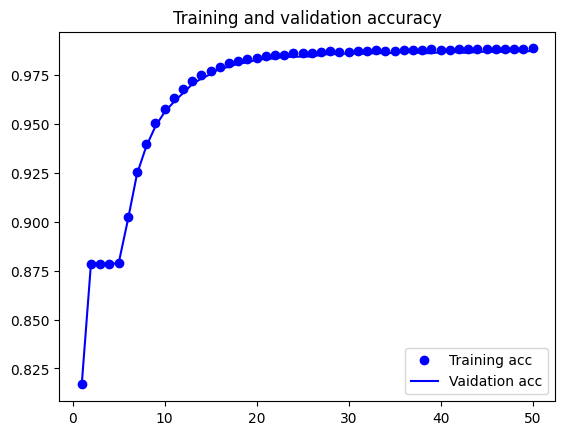

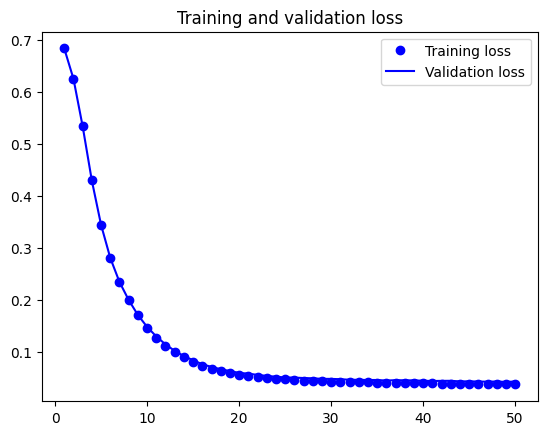

/tmp/ipykernel_423/2181039425.py:62: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_pred = model(torch.tensor(x_test).float())[0] > .5
/tmp/ipykernel_423/2181039425.py:101: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_pred = model(torch.tensor(x_test).float())[0] > .5
/tmp/ipykernel_423/2181039425.py:101: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_pred = model(torch.tensor(x_test).float())[0] > .5
/tmp/ipykernel_423/2181039425.py:101: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clo

f1-score :  0.7843570481661511
precision :  0.8294392523364486
recall :  0.7439228834870075
accuracy :  0.9504241377558795
              precision    recall  f1-score   support

           0       0.97      0.98      0.97     17301
           1       0.83      0.74      0.78      2386

    accuracy                           0.95     19687
   macro avg       0.90      0.86      0.88     19687
weighted avg       0.95      0.95      0.95     19687

[[16936   365]
 [  611  1775]]
final report [{'all_language_evaluate': True, 'train_evaluate_pair': False, 'language_pair': None, 'class': '0', 'precision': 0.97, 'recall': 0.98, 'f1_score': 0.97, 'support': 17301.0}, {'all_language_evaluate': True, 'train_evaluate_pair': False, 'language_pair': None, 'class': '1', 'precision': 0.83, 'recall': 0.74, 'f1_score': 0.78, 'support': 2386.0, 'acc': 0.95}]

Evaluating on Hindi-Persian
f1-score :  0.7574468085106383
precision :  0.8018018018018018
recall :  0.717741935483871
accuracy :  0.9536961819658

/tmp/ipykernel_423/2181039425.py:101: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_pred = model(torch.tensor(x_test).float())[0] > .5
/tmp/ipykernel_423/2181039425.py:101: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_pred = model(torch.tensor(x_test).float())[0] > .5
/tmp/ipykernel_423/2181039425.py:101: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_pred = model(torch.tensor(x_test).float())[0] > .5
/tmp/ipykernel_423/2181039425.py:101: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().cl

f1-score :  0.8295454545454546
precision :  0.8488372093023255
recall :  0.8111111111111111
accuracy :  0.9607843137254902
              precision    recall  f1-score   support

           0       0.97      0.98      0.98      1350
           1       0.85      0.81      0.83       180

    accuracy                           0.96      1530
   macro avg       0.91      0.90      0.90      1530
weighted avg       0.96      0.96      0.96      1530

[[1324   26]
 [  34  146]]
final report [{'all_language_evaluate': False, 'train_evaluate_pair': False, 'language_pair': 'Kazakh-Russian', 'class': '0', 'precision': 0.97, 'recall': 0.98, 'f1_score': 0.98, 'support': 1350.0}, {'all_language_evaluate': False, 'train_evaluate_pair': False, 'language_pair': 'Kazakh-Russian', 'class': '1', 'precision': 0.85, 'recall': 0.81, 'f1_score': 0.83, 'support': 180.0, 'acc': 0.96}]

Evaluating on Azerbaijani-Arabic
f1-score :  0.6540284360189573
precision :  0.69
recall :  0.6216216216216216
accuracy :  0.9

/tmp/ipykernel_423/2181039425.py:101: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_pred = model(torch.tensor(x_test).float())[0] > .5
/tmp/ipykernel_423/2181039425.py:101: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_pred = model(torch.tensor(x_test).float())[0] > .5


epoch 100
                    Train set - loss: 0.632, accuracy: 0.899 
                    Val set - loss: 0.633, accuracy: 0.899
epoch 200
                    Train set - loss: 0.543, accuracy: 0.899 
                    Val set - loss: 0.545, accuracy: 0.899
epoch 300
                    Train set - loss: 0.438, accuracy: 0.899 
                    Val set - loss: 0.442, accuracy: 0.899
epoch 400
                    Train set - loss: 0.349, accuracy: 0.899 
                    Val set - loss: 0.358, accuracy: 0.899
epoch 500
                    Train set - loss: 0.281, accuracy: 0.899 
                    Val set - loss: 0.295, accuracy: 0.899
epoch 600
                    Train set - loss: 0.23, accuracy: 0.909 
                    Val set - loss: 0.249, accuracy: 0.904
epoch 700
                    Train set - loss: 0.191, accuracy: 0.944 
                    Val set - loss: 0.214, accuracy: 0.927
epoch 800
                    Train set - loss: 0.16, accuracy: 0.959 
             

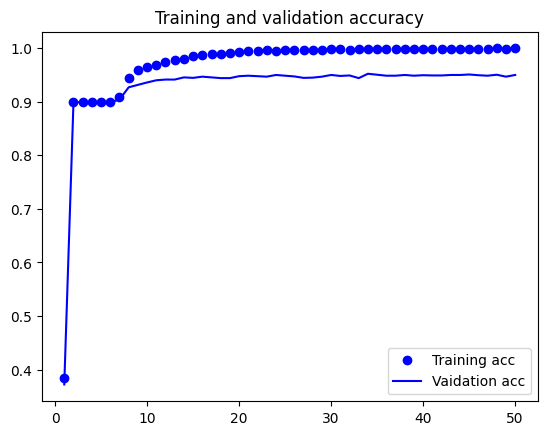

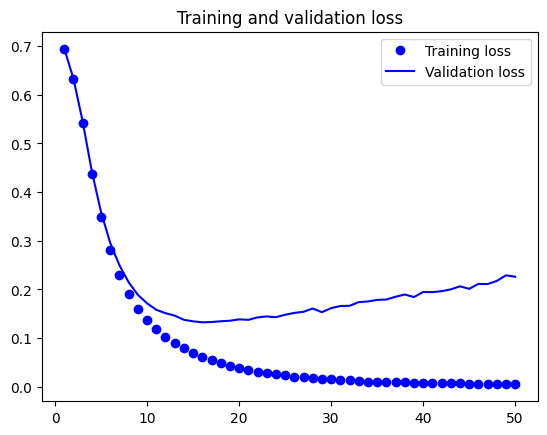

/tmp/ipykernel_423/2181039425.py:169: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_pred = model(torch.tensor(x_test).float())[0] > .5


f1-score :  0.7336244541484717
precision :  0.8
recall :  0.6774193548387096
accuracy :  0.950446791226645
              precision    recall  f1-score   support

           0       0.96      0.98      0.97      1107
           1       0.80      0.68      0.73       124

    accuracy                           0.95      1231
   macro avg       0.88      0.83      0.85      1231
weighted avg       0.95      0.95      0.95      1231

[[1086   21]
 [  40   84]]
final report [{'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'Hindi-Persian', 'class': '0', 'precision': 0.96, 'recall': 0.98, 'f1_score': 0.97, 'support': 1107.0}, {'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'Hindi-Persian', 'class': '1', 'precision': 0.8, 'recall': 0.68, 'f1_score': 0.73, 'support': 124.0, 'acc': 0.95}]

Training and evaluating on English-French
epoch 0
                    Train set - loss: 0.679, accuracy: 0.803 
                    Val set - loss:

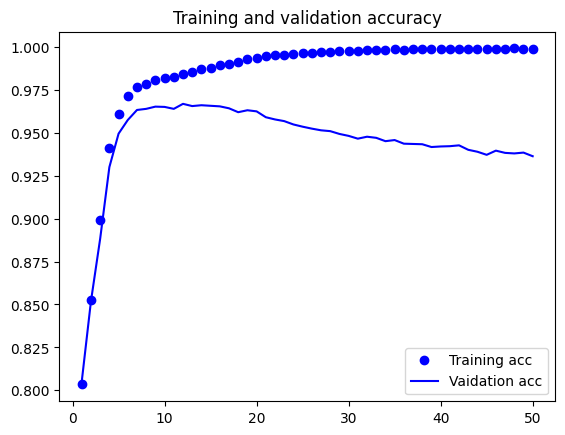

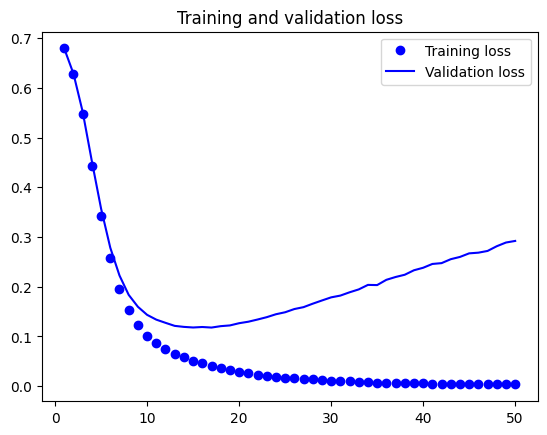

/tmp/ipykernel_423/2181039425.py:169: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_pred = model(torch.tensor(x_test).float())[0] > .5


f1-score :  0.8012295081967213
precision :  0.8336886993603412
recall :  0.7712031558185405
accuracy :  0.9432250512145156
              precision    recall  f1-score   support

           0       0.96      0.97      0.97      2910
           1       0.83      0.77      0.80       507

    accuracy                           0.94      3417
   macro avg       0.90      0.87      0.88      3417
weighted avg       0.94      0.94      0.94      3417

[[2832   78]
 [ 116  391]]
final report [{'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'English-French', 'class': '0', 'precision': 0.96, 'recall': 0.97, 'f1_score': 0.97, 'support': 2910.0}, {'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'English-French', 'class': '1', 'precision': 0.83, 'recall': 0.77, 'f1_score': 0.8, 'support': 507.0, 'acc': 0.94}]

Training and evaluating on Finnish-Swedish
epoch 0
                    Train set - loss: 0.679, accuracy: 0.887 
                

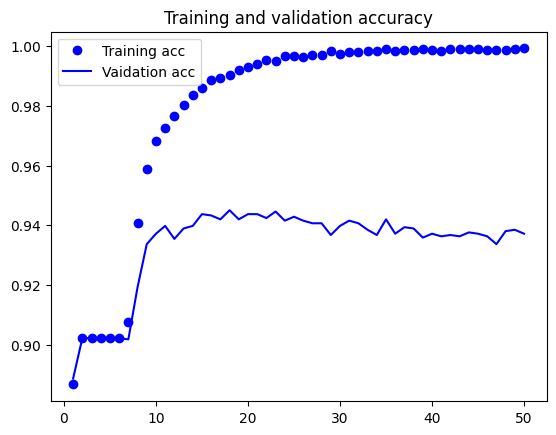

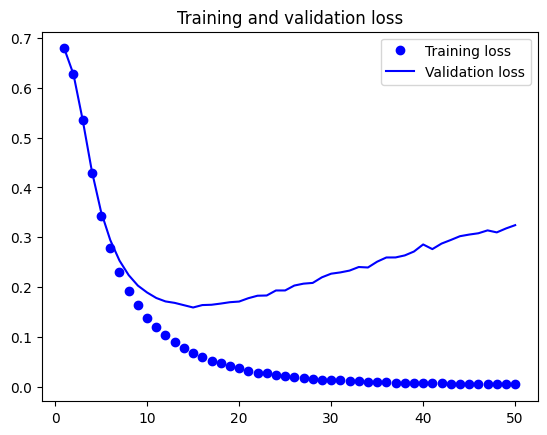

/tmp/ipykernel_423/2181039425.py:169: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_pred = model(torch.tensor(x_test).float())[0] > .5


f1-score :  0.5570776255707762
precision :  0.6421052631578947
recall :  0.49193548387096775
accuracy :  0.923682140047207
              precision    recall  f1-score   support

           0       0.95      0.97      0.96      1147
           1       0.64      0.49      0.56       124

    accuracy                           0.92      1271
   macro avg       0.79      0.73      0.76      1271
weighted avg       0.92      0.92      0.92      1271

[[1113   34]
 [  63   61]]
final report [{'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'Finnish-Swedish', 'class': '0', 'precision': 0.95, 'recall': 0.97, 'f1_score': 0.96, 'support': 1147.0}, {'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'Finnish-Swedish', 'class': '1', 'precision': 0.64, 'recall': 0.49, 'f1_score': 0.56, 'support': 124.0, 'acc': 0.92}]

Training and evaluating on Kazakh-Russian
epoch 0
                    Train set - loss: 0.702, accuracy: 0.175 
              

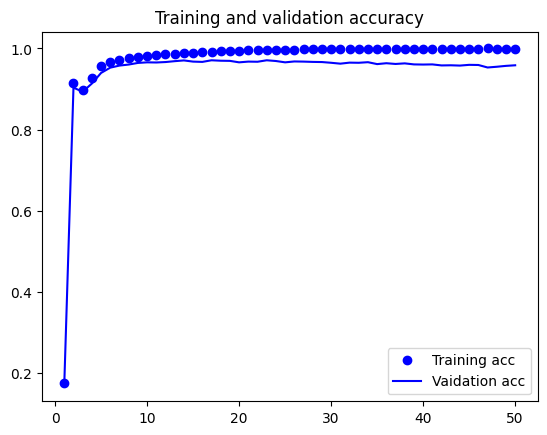

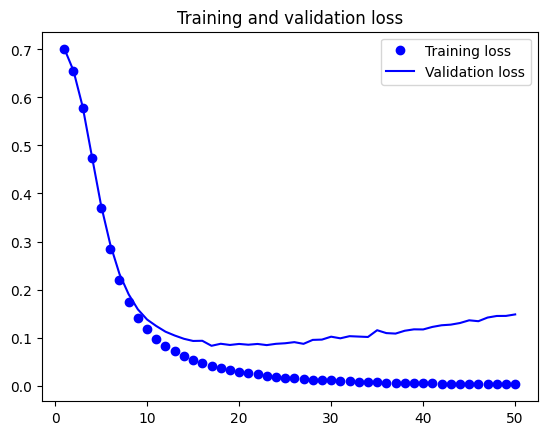

/tmp/ipykernel_423/2181039425.py:169: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_pred = model(torch.tensor(x_test).float())[0] > .5


f1-score :  0.782608695652174
precision :  0.8181818181818182
recall :  0.75
accuracy :  0.9509803921568627
              precision    recall  f1-score   support

           0       0.97      0.98      0.97      1350
           1       0.82      0.75      0.78       180

    accuracy                           0.95      1530
   macro avg       0.89      0.86      0.88      1530
weighted avg       0.95      0.95      0.95      1530

[[1320   30]
 [  45  135]]
final report [{'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'Kazakh-Russian', 'class': '0', 'precision': 0.97, 'recall': 0.98, 'f1_score': 0.97, 'support': 1350.0}, {'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'Kazakh-Russian', 'class': '1', 'precision': 0.82, 'recall': 0.75, 'f1_score': 0.78, 'support': 180.0, 'acc': 0.95}]

Training and evaluating on Azerbaijani-Arabic
epoch 0
                    Train set - loss: 0.745, accuracy: 0.093 
                    Val set

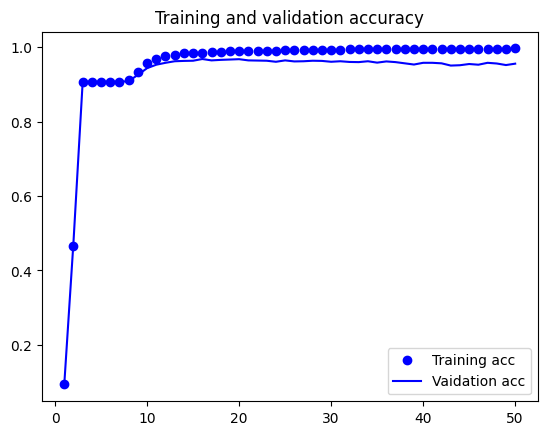

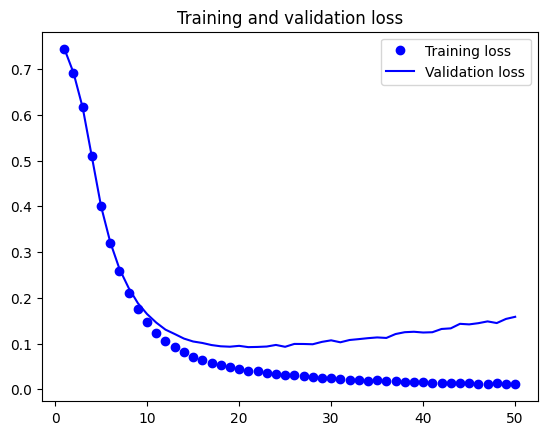

/tmp/ipykernel_423/2181039425.py:169: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_pred = model(torch.tensor(x_test).float())[0] > .5


f1-score :  0.7339449541284404
precision :  0.7476635514018691
recall :  0.7207207207207207
accuracy :  0.9514237855946399
              precision    recall  f1-score   support

           0       0.97      0.98      0.97      1083
           1       0.75      0.72      0.73       111

    accuracy                           0.95      1194
   macro avg       0.86      0.85      0.85      1194
weighted avg       0.95      0.95      0.95      1194

[[1056   27]
 [  31   80]]
final report [{'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'Azerbaijani-Arabic', 'class': '0', 'precision': 0.97, 'recall': 0.98, 'f1_score': 0.97, 'support': 1083.0}, {'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'Azerbaijani-Arabic', 'class': '1', 'precision': 0.75, 'recall': 0.72, 'f1_score': 0.73, 'support': 111.0, 'acc': 0.95}]

Training and evaluating on Chinese-English
epoch 0
                    Train set - loss: 0.693, accuracy: 0.486 
       

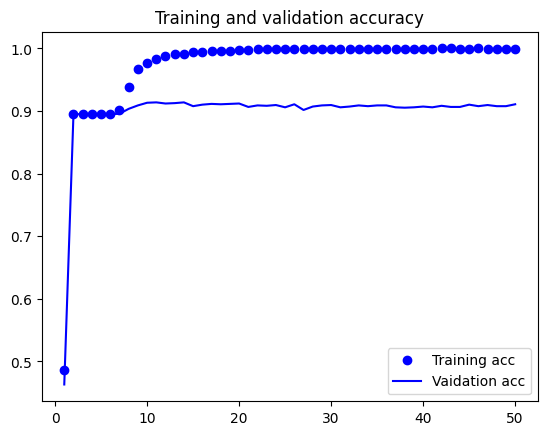

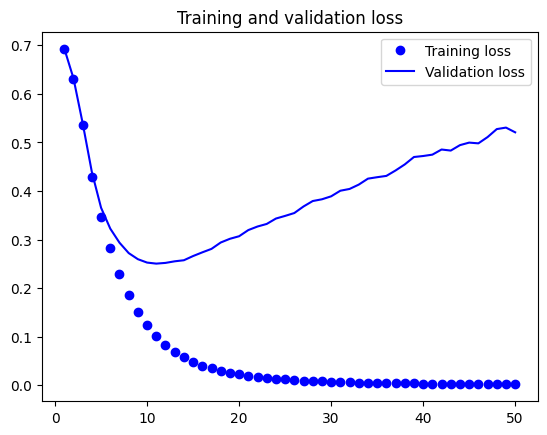

/tmp/ipykernel_423/2181039425.py:169: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_pred = model(torch.tensor(x_test).float())[0] > .5


f1-score :  0.5595238095238095
precision :  0.6438356164383562
recall :  0.49473684210526314
accuracy :  0.9187705817782656
              precision    recall  f1-score   support

           0       0.94      0.97      0.96       816
           1       0.64      0.49      0.56        95

    accuracy                           0.92       911
   macro avg       0.79      0.73      0.76       911
weighted avg       0.91      0.92      0.91       911

[[790  26]
 [ 48  47]]
final report [{'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'Chinese-English', 'class': '0', 'precision': 0.94, 'recall': 0.97, 'f1_score': 0.96, 'support': 816.0}, {'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'Chinese-English', 'class': '1', 'precision': 0.64, 'recall': 0.49, 'f1_score': 0.56, 'support': 95.0, 'acc': 0.92}]

Training and evaluating on German-French
epoch 0
                    Train set - loss: 0.696, accuracy: 0.342 
                    

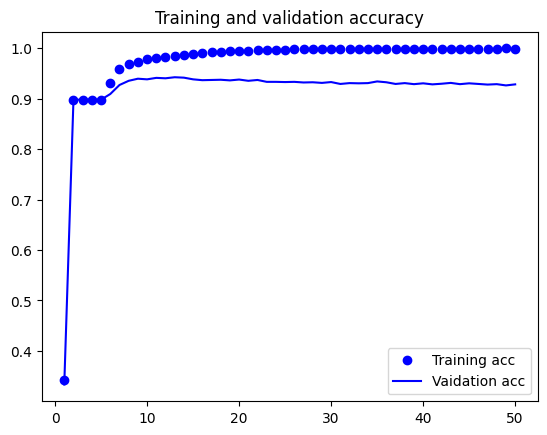

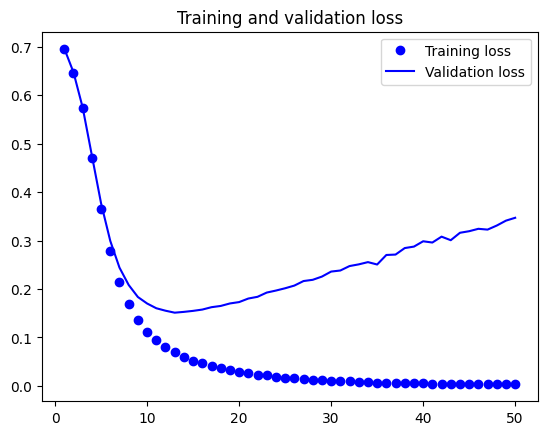

/tmp/ipykernel_423/2181039425.py:169: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_pred = model(torch.tensor(x_test).float())[0] > .5


f1-score :  0.6502057613168725
precision :  0.7383177570093458
recall :  0.5808823529411765
accuracy :  0.9363295880149812
              precision    recall  f1-score   support

           0       0.95      0.98      0.96      1199
           1       0.74      0.58      0.65       136

    accuracy                           0.94      1335
   macro avg       0.85      0.78      0.81      1335
weighted avg       0.93      0.94      0.93      1335

[[1171   28]
 [  57   79]]
final report [{'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'German-French', 'class': '0', 'precision': 0.95, 'recall': 0.98, 'f1_score': 0.96, 'support': 1199.0}, {'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'German-French', 'class': '1', 'precision': 0.74, 'recall': 0.58, 'f1_score': 0.65, 'support': 136.0, 'acc': 0.94}]

Training and evaluating on English-German
epoch 0
                    Train set - loss: 0.677, accuracy: 0.864 
                  

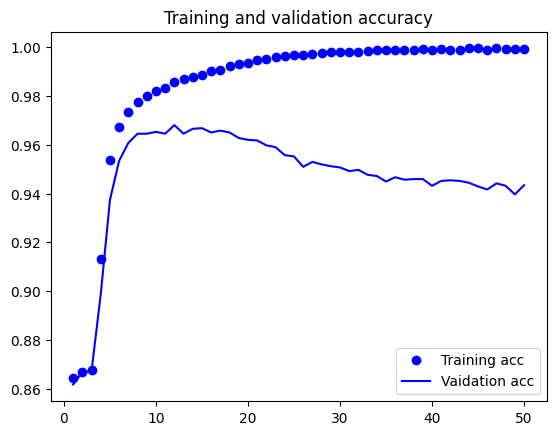

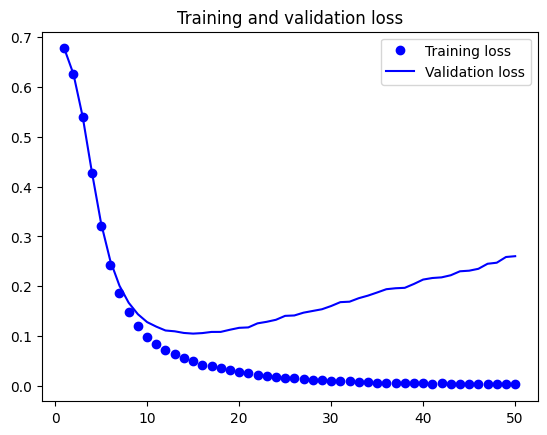

/tmp/ipykernel_423/2181039425.py:169: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_pred = model(torch.tensor(x_test).float())[0] > .5


f1-score :  0.744954128440367
precision :  0.8087649402390438
recall :  0.6904761904761905
accuracy :  0.9370185772541912
              precision    recall  f1-score   support

           0       0.95      0.97      0.96      1913
           1       0.81      0.69      0.74       294

    accuracy                           0.94      2207
   macro avg       0.88      0.83      0.85      2207
weighted avg       0.93      0.94      0.93      2207

[[1865   48]
 [  91  203]]
final report [{'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'English-German', 'class': '0', 'precision': 0.95, 'recall': 0.97, 'f1_score': 0.96, 'support': 1913.0}, {'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'English-German', 'class': '1', 'precision': 0.81, 'recall': 0.69, 'f1_score': 0.74, 'support': 294.0, 'acc': 0.94}]

Training and evaluating on Romanian-Hungarian
epoch 0
                    Train set - loss: 0.668, accuracy: 0.891 
             

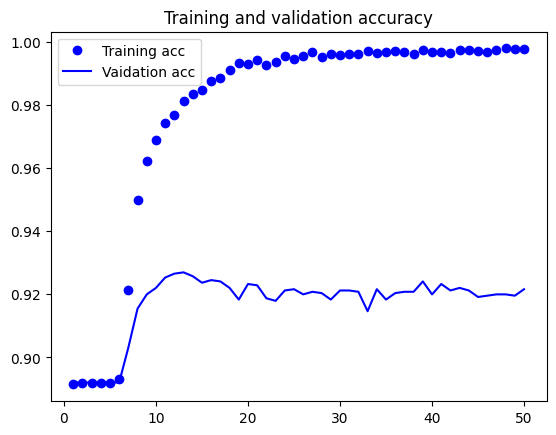

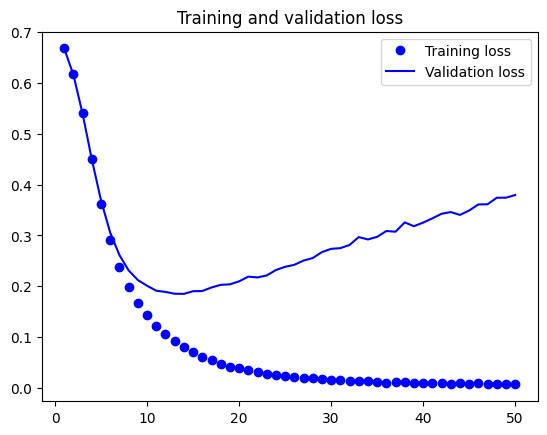

/tmp/ipykernel_423/2181039425.py:169: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_pred = model(torch.tensor(x_test).float())[0] > .5


f1-score :  0.5859375
precision :  0.6756756756756757
recall :  0.5172413793103449
accuracy :  0.9214814814814815
              precision    recall  f1-score   support

           0       0.94      0.97      0.96      1205
           1       0.68      0.52      0.59       145

    accuracy                           0.92      1350
   macro avg       0.81      0.74      0.77      1350
weighted avg       0.91      0.92      0.92      1350

[[1169   36]
 [  70   75]]
final report [{'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'Romanian-Hungarian', 'class': '0', 'precision': 0.94, 'recall': 0.97, 'f1_score': 0.96, 'support': 1205.0}, {'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'Romanian-Hungarian', 'class': '1', 'precision': 0.68, 'recall': 0.52, 'f1_score': 0.59, 'support': 145.0, 'acc': 0.92}]

Training and evaluating on Polish-French
epoch 0
                    Train set - loss: 0.679, accuracy: 0.857 
                  

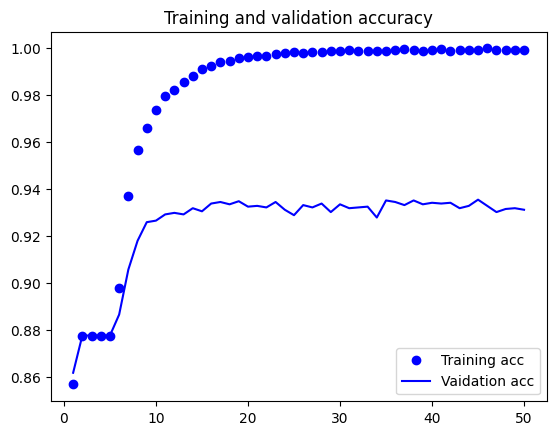

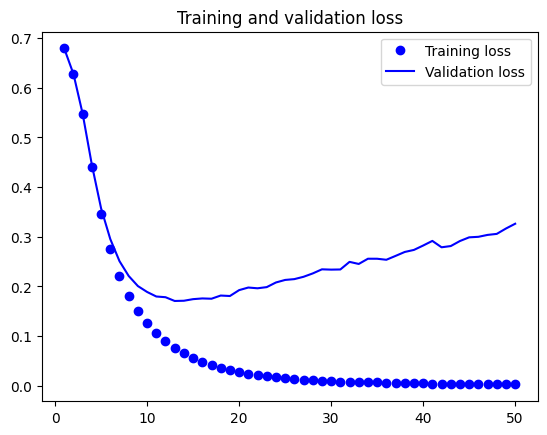

/tmp/ipykernel_423/2181039425.py:169: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_pred = model(torch.tensor(x_test).float())[0] > .5


f1-score :  0.6842105263157895
precision :  0.7428571428571429
recall :  0.6341463414634146
accuracy :  0.9283582089552239
              precision    recall  f1-score   support

           0       0.95      0.97      0.96      1470
           1       0.74      0.63      0.68       205

    accuracy                           0.93      1675
   macro avg       0.85      0.80      0.82      1675
weighted avg       0.92      0.93      0.93      1675

[[1425   45]
 [  75  130]]
final report [{'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'Polish-French', 'class': '0', 'precision': 0.95, 'recall': 0.97, 'f1_score': 0.96, 'support': 1470.0}, {'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'Polish-French', 'class': '1', 'precision': 0.74, 'recall': 0.63, 'f1_score': 0.68, 'support': 205.0, 'acc': 0.93}]

Training and evaluating on Indonesian-Dutch
epoch 0
                    Train set - loss: 0.695, accuracy: 0.412 
                

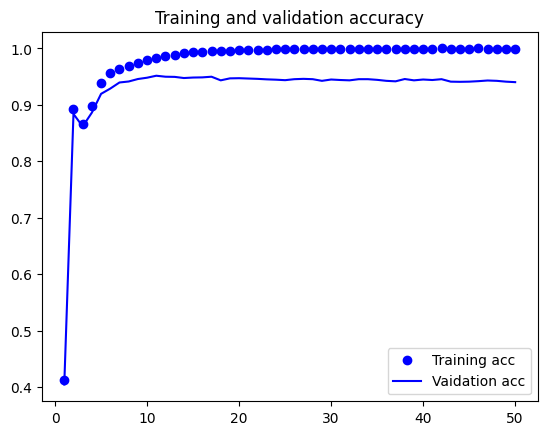

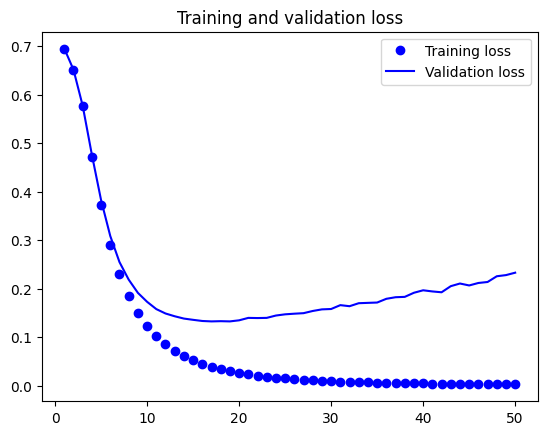

/tmp/ipykernel_423/2181039425.py:169: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_pred = model(torch.tensor(x_test).float())[0] > .5


f1-score :  0.7984790874524715
precision :  0.8076923076923077
recall :  0.7894736842105263
accuracy :  0.9442691903259727
              precision    recall  f1-score   support

           0       0.97      0.97      0.97      1636
           1       0.81      0.79      0.80       266

    accuracy                           0.94      1902
   macro avg       0.89      0.88      0.88      1902
weighted avg       0.94      0.94      0.94      1902

[[1586   50]
 [  56  210]]
final report [{'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'Indonesian-Dutch', 'class': '0', 'precision': 0.97, 'recall': 0.97, 'f1_score': 0.97, 'support': 1636.0}, {'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'Indonesian-Dutch', 'class': '1', 'precision': 0.81, 'recall': 0.79, 'f1_score': 0.8, 'support': 266.0, 'acc': 0.94}]

Training and evaluating on Romanian-French
epoch 0
                    Train set - loss: 0.681, accuracy: 0.863 
            

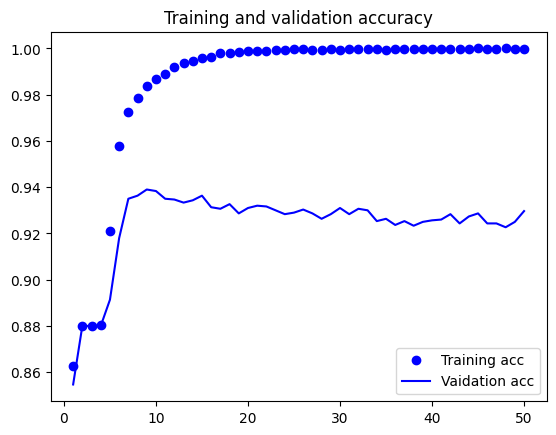

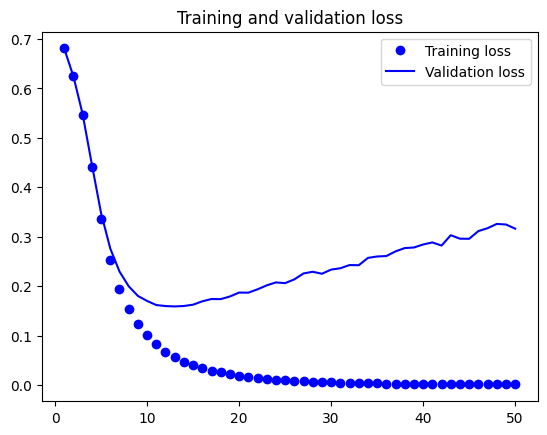

f1-score :  0.6575342465753424
precision :  0.7228915662650602
recall :  0.6030150753768844
accuracy :  0.9248798076923077
              precision    recall  f1-score   support

           0       0.95      0.97      0.96      1465
           1       0.72      0.60      0.66       199

    accuracy                           0.92      1664
   macro avg       0.84      0.79      0.81      1664
weighted avg       0.92      0.92      0.92      1664

[[1419   46]
 [  79  120]]
final report [{'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'Romanian-French', 'class': '0', 'precision': 0.95, 'recall': 0.97, 'f1_score': 0.96, 'support': 1465.0}, {'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'Romanian-French', 'class': '1', 'precision': 0.72, 'recall': 0.6, 'f1_score': 0.66, 'support': 199.0, 'acc': 0.92}]


Zip ready: /content/result_zips/all_data__NN_results.zip  (220 KB)
    Final_results/all_data/NN_results/all_lang_falseneg.csv

/tmp/ipykernel_423/2181039425.py:169: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_pred = model(torch.tensor(x_test).float())[0] > .5


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

'/content/result_zips/all_data__NN_results.zip'

In [15]:
print("Evaluating NN on all_data splits\n")
results = nn_evaluate(train_alldata, test_alldata, pairs)
save_eval_results(result_dir("all_data", "NN"), *results)

### NN - real_dist

Evaluating NN on real_dist splits

NeuralNetwork(
  (linear_relu_stack): Sequential(
    (0): Linear(in_features=34, out_features=512, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.1, inplace=False)
    (3): Linear(in_features=512, out_features=256, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.1, inplace=False)
    (6): Linear(in_features=256, out_features=128, bias=True)
    (7): ReLU()
    (8): Dropout(p=0.1, inplace=False)
    (9): Linear(in_features=128, out_features=1, bias=True)
  )
)
Training on all langs

epoch 0
                    Train set - loss: 0.689, accuracy: 0.705 
                    Val set - loss: 0.689, accuracy: 0.705
epoch 100
                    Train set - loss: 0.642, accuracy: 0.792 
                    Val set - loss: 0.642, accuracy: 0.792
epoch 200
                    Train set - loss: 0.564, accuracy: 0.804 
                    Val set - loss: 0.563, accuracy: 0.805
epoch 300
                    Train set - loss: 0.457, accuracy: 0.88 
              

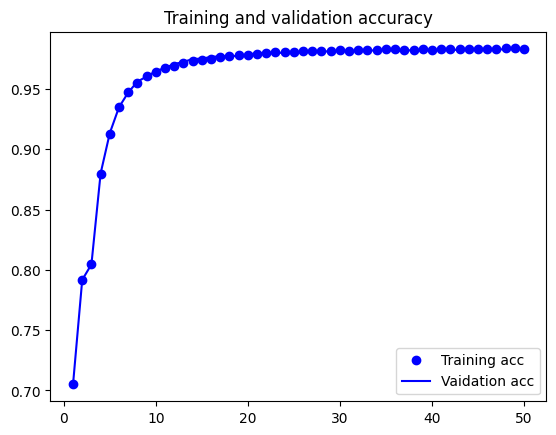

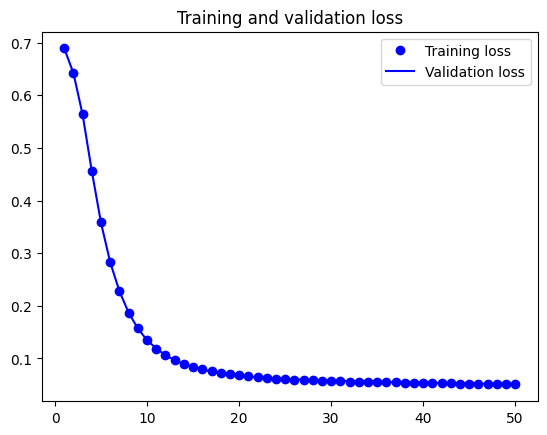

/tmp/ipykernel_423/2181039425.py:62: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_pred = model(torch.tensor(x_test).float())[0] > .5
/tmp/ipykernel_423/2181039425.py:101: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_pred = model(torch.tensor(x_test).float())[0] > .5
/tmp/ipykernel_423/2181039425.py:101: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_pred = model(torch.tensor(x_test).float())[0] > .5
/tmp/ipykernel_423/2181039425.py:101: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clo

f1-score :  0.8652513966480447
precision :  0.9267592149353758
recall :  0.8113998323554066
accuracy :  0.9622865720182625
              precision    recall  f1-score   support

           0       0.97      0.99      0.98     13603
           1       0.93      0.81      0.87      2386

    accuracy                           0.96     15989
   macro avg       0.95      0.90      0.92     15989
weighted avg       0.96      0.96      0.96     15989

[[13450   153]
 [  450  1936]]
final report [{'all_language_evaluate': True, 'train_evaluate_pair': False, 'language_pair': None, 'class': '0', 'precision': 0.97, 'recall': 0.99, 'f1_score': 0.98, 'support': 13603.0}, {'all_language_evaluate': True, 'train_evaluate_pair': False, 'language_pair': None, 'class': '1', 'precision': 0.93, 'recall': 0.81, 'f1_score': 0.87, 'support': 2386.0, 'acc': 0.96}]

Evaluating on Hindi-Persian
f1-score :  0.9152542372881356
precision :  0.9642857142857143
recall :  0.8709677419354839
accuracy :  0.951690821256

/tmp/ipykernel_423/2181039425.py:101: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_pred = model(torch.tensor(x_test).float())[0] > .5
/tmp/ipykernel_423/2181039425.py:101: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_pred = model(torch.tensor(x_test).float())[0] > .5
/tmp/ipykernel_423/2181039425.py:101: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_pred = model(torch.tensor(x_test).float())[0] > .5
/tmp/ipykernel_423/2181039425.py:101: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().cl

precision :  0.8681318681318682
recall :  0.7117117117117117
accuracy :  0.9406207827260459
              precision    recall  f1-score   support

           0       0.95      0.98      0.97       630
           1       0.87      0.71      0.78       111

    accuracy                           0.94       741
   macro avg       0.91      0.85      0.87       741
weighted avg       0.94      0.94      0.94       741

[[618  12]
 [ 32  79]]
final report [{'all_language_evaluate': False, 'train_evaluate_pair': False, 'language_pair': 'Azerbaijani-Arabic', 'class': '0', 'precision': 0.95, 'recall': 0.98, 'f1_score': 0.97, 'support': 630.0}, {'all_language_evaluate': False, 'train_evaluate_pair': False, 'language_pair': 'Azerbaijani-Arabic', 'class': '1', 'precision': 0.87, 'recall': 0.71, 'f1_score': 0.78, 'support': 111.0, 'acc': 0.94}]

Evaluating on Chinese-English
f1-score :  0.6871165644171779
precision :  0.8235294117647058
recall :  0.5894736842105263
accuracy :  0.946652719665272
  

/tmp/ipykernel_423/2181039425.py:101: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_pred = model(torch.tensor(x_test).float())[0] > .5


f1-score :  0.8787061994609164
precision :  0.9476744186046512
recall :  0.8190954773869347
accuracy :  0.9322289156626506
              precision    recall  f1-score   support

           0       0.93      0.98      0.95       465
           1       0.95      0.82      0.88       199

    accuracy                           0.93       664
   macro avg       0.94      0.90      0.92       664
weighted avg       0.93      0.93      0.93       664

[[456   9]
 [ 36 163]]
final report [{'all_language_evaluate': False, 'train_evaluate_pair': False, 'language_pair': 'Romanian-French', 'class': '0', 'precision': 0.93, 'recall': 0.98, 'f1_score': 0.95, 'support': 465.0}, {'all_language_evaluate': False, 'train_evaluate_pair': False, 'language_pair': 'Romanian-French', 'class': '1', 'precision': 0.95, 'recall': 0.82, 'f1_score': 0.88, 'support': 199.0, 'acc': 0.93}]

Training and evaluating on Hindi-Persian
epoch 0
                    Train set - loss: 0.692, accuracy: 0.528 
                  

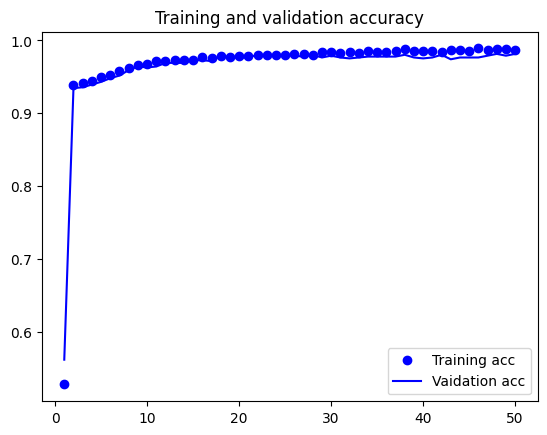

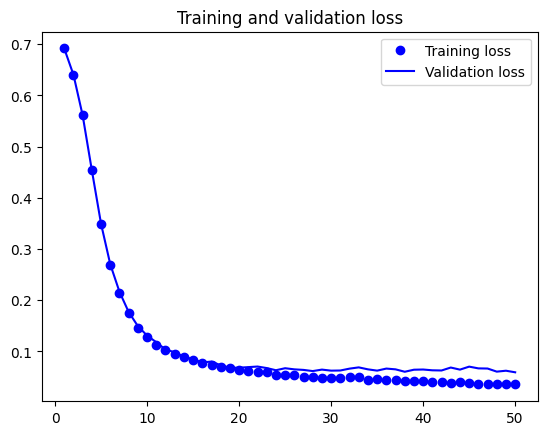

/tmp/ipykernel_423/2181039425.py:169: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_pred = model(torch.tensor(x_test).float())[0] > .5


f1-score :  0.9294605809128631
precision :  0.9572649572649573
recall :  0.9032258064516129
accuracy :  0.9589371980676329
              precision    recall  f1-score   support

           0       0.96      0.98      0.97       290
           1       0.96      0.90      0.93       124

    accuracy                           0.96       414
   macro avg       0.96      0.94      0.95       414
weighted avg       0.96      0.96      0.96       414

[[285   5]
 [ 12 112]]
final report [{'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'Hindi-Persian', 'class': '0', 'precision': 0.96, 'recall': 0.98, 'f1_score': 0.97, 'support': 290.0}, {'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'Hindi-Persian', 'class': '1', 'precision': 0.96, 'recall': 0.9, 'f1_score': 0.93, 'support': 124.0, 'acc': 0.96}]

Training and evaluating on English-French
epoch 0
                    Train set - loss: 0.687, accuracy: 0.663 
                    Val 

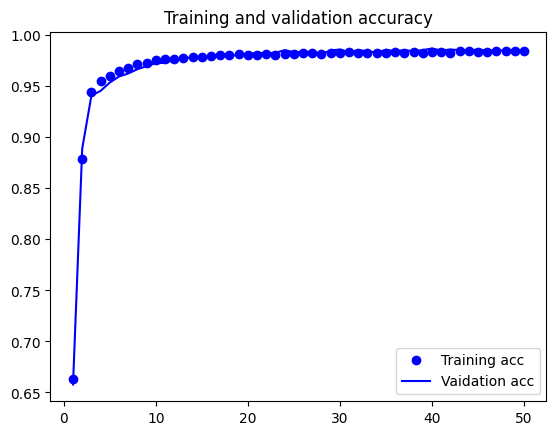

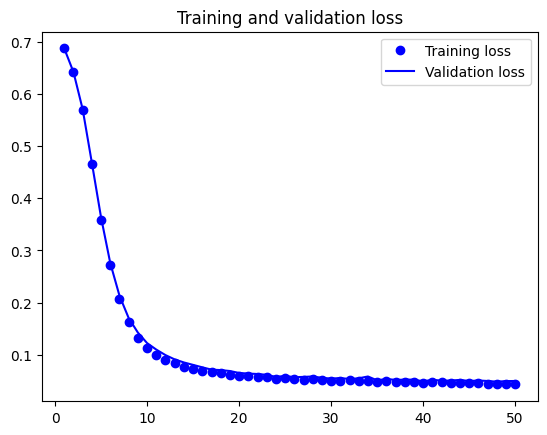

/tmp/ipykernel_423/2181039425.py:169: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_pred = model(torch.tensor(x_test).float())[0] > .5


f1-score :  0.9476861167002012
precision :  0.9671457905544147
recall :  0.9289940828402367
accuracy :  0.9692307692307692
              precision    recall  f1-score   support

           0       0.97      0.99      0.98      1183
           1       0.97      0.93      0.95       507

    accuracy                           0.97      1690
   macro avg       0.97      0.96      0.96      1690
weighted avg       0.97      0.97      0.97      1690

[[1167   16]
 [  36  471]]
final report [{'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'English-French', 'class': '0', 'precision': 0.97, 'recall': 0.99, 'f1_score': 0.98, 'support': 1183.0}, {'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'English-French', 'class': '1', 'precision': 0.97, 'recall': 0.93, 'f1_score': 0.95, 'support': 507.0, 'acc': 0.97}]

Training and evaluating on Finnish-Swedish
epoch 0
                    Train set - loss: 0.681, accuracy: 0.854 
               

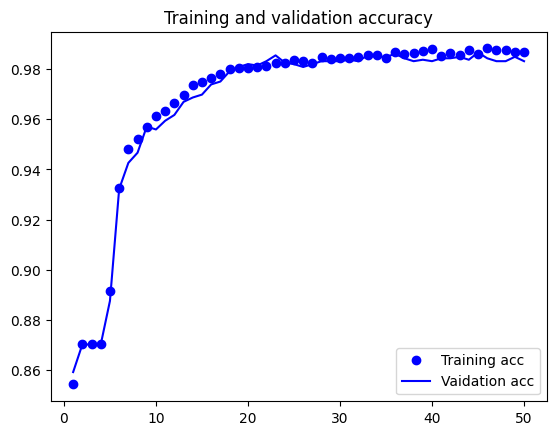

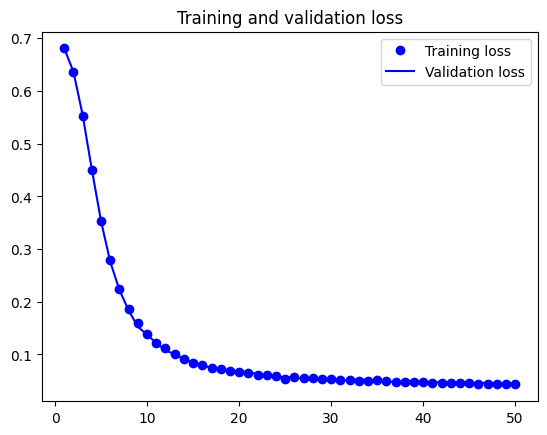

/tmp/ipykernel_423/2181039425.py:169: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_pred = model(torch.tensor(x_test).float())[0] > .5


f1-score :  0.7348837209302326
precision :  0.8681318681318682
recall :  0.6370967741935484
accuracy :  0.9540692989524577
              precision    recall  f1-score   support

           0       0.96      0.99      0.97      1117
           1       0.87      0.64      0.73       124

    accuracy                           0.95      1241
   macro avg       0.91      0.81      0.85      1241
weighted avg       0.95      0.95      0.95      1241

[[1105   12]
 [  45   79]]
final report [{'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'Finnish-Swedish', 'class': '0', 'precision': 0.96, 'recall': 0.99, 'f1_score': 0.97, 'support': 1117.0}, {'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'Finnish-Swedish', 'class': '1', 'precision': 0.87, 'recall': 0.64, 'f1_score': 0.73, 'support': 124.0, 'acc': 0.95}]

Training and evaluating on Kazakh-Russian
epoch 0
                    Train set - loss: 0.7, accuracy: 0.228 
                

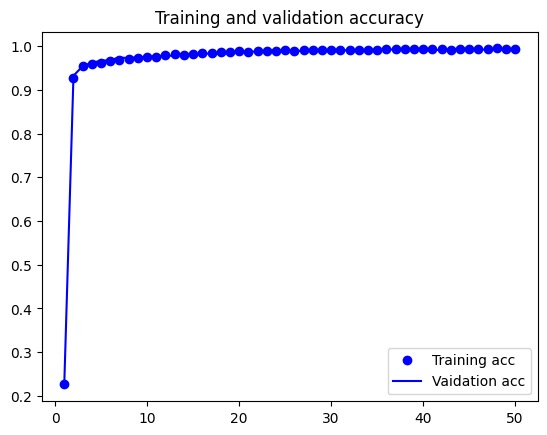

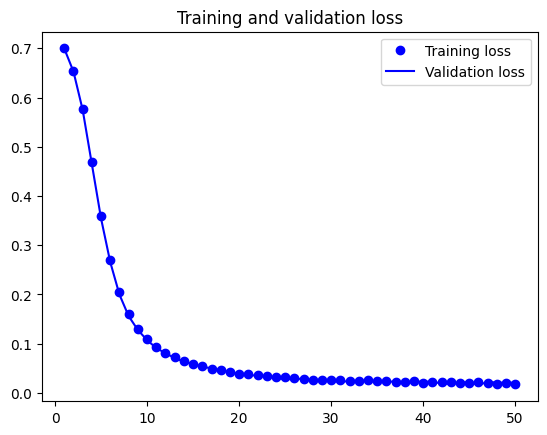

/tmp/ipykernel_423/2181039425.py:169: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_pred = model(torch.tensor(x_test).float())[0] > .5


f1-score :  0.9213483146067416
precision :  0.9318181818181818
recall :  0.9111111111111111
accuracy :  0.9844961240310077
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      1626
           1       0.93      0.91      0.92       180

    accuracy                           0.98      1806
   macro avg       0.96      0.95      0.96      1806
weighted avg       0.98      0.98      0.98      1806

[[1614   12]
 [  16  164]]
final report [{'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'Kazakh-Russian', 'class': '0', 'precision': 0.99, 'recall': 0.99, 'f1_score': 0.99, 'support': 1626.0}, {'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'Kazakh-Russian', 'class': '1', 'precision': 0.93, 'recall': 0.91, 'f1_score': 0.92, 'support': 180.0, 'acc': 0.98}]

Training and evaluating on Azerbaijani-Arabic
epoch 0
                    Train set - loss: 0.737, accuracy: 0.157 
            

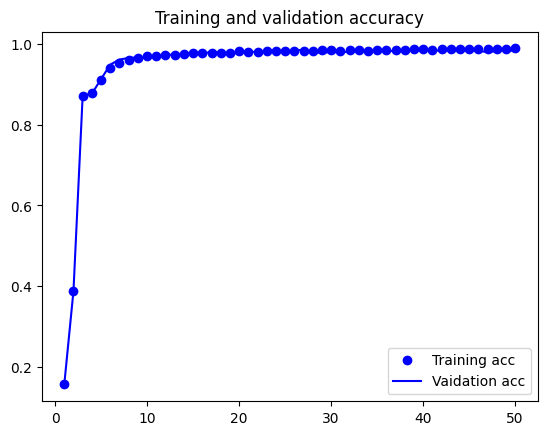

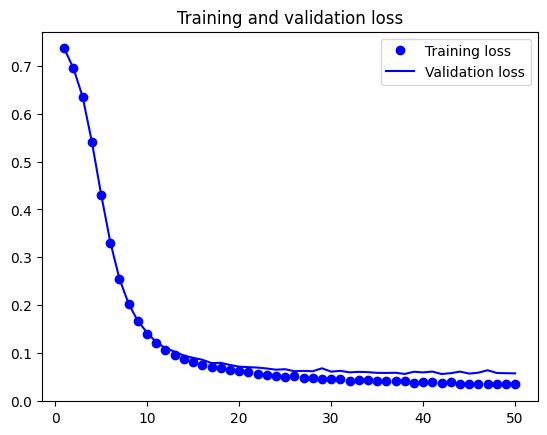

/tmp/ipykernel_423/2181039425.py:169: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_pred = model(torch.tensor(x_test).float())[0] > .5


f1-score :  0.8349514563106796
precision :  0.9052631578947369
recall :  0.7747747747747747
accuracy :  0.9541160593792173
              precision    recall  f1-score   support

           0       0.96      0.99      0.97       630
           1       0.91      0.77      0.83       111

    accuracy                           0.95       741
   macro avg       0.93      0.88      0.90       741
weighted avg       0.95      0.95      0.95       741

[[621   9]
 [ 25  86]]
final report [{'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'Azerbaijani-Arabic', 'class': '0', 'precision': 0.96, 'recall': 0.99, 'f1_score': 0.97, 'support': 630.0}, {'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'Azerbaijani-Arabic', 'class': '1', 'precision': 0.91, 'recall': 0.77, 'f1_score': 0.83, 'support': 111.0, 'acc': 0.95}]

Training and evaluating on Chinese-English
epoch 0
                    Train set - loss: 0.694, accuracy: 0.446 
            

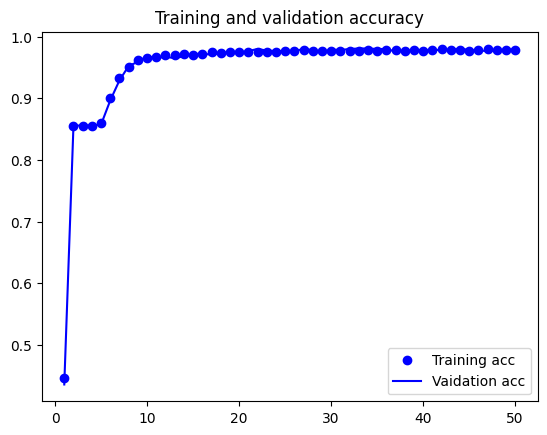

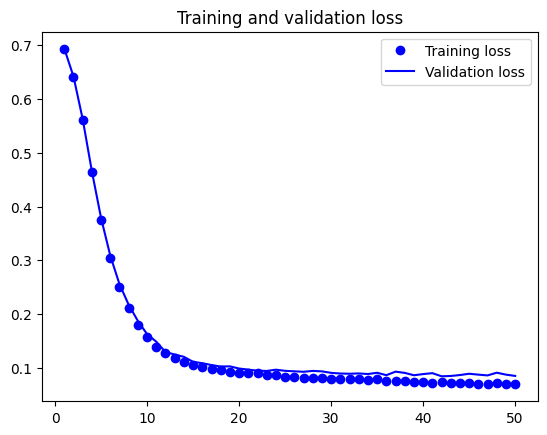

/tmp/ipykernel_423/2181039425.py:169: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_pred = model(torch.tensor(x_test).float())[0] > .5


f1-score :  0.6625766871165644
precision :  0.7941176470588235
recall :  0.5684210526315789
accuracy :  0.9424686192468619
              precision    recall  f1-score   support

           0       0.95      0.98      0.97       861
           1       0.79      0.57      0.66        95

    accuracy                           0.94       956
   macro avg       0.87      0.78      0.82       956
weighted avg       0.94      0.94      0.94       956

[[847  14]
 [ 41  54]]
final report [{'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'Chinese-English', 'class': '0', 'precision': 0.95, 'recall': 0.98, 'f1_score': 0.97, 'support': 861.0}, {'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'Chinese-English', 'class': '1', 'precision': 0.79, 'recall': 0.57, 'f1_score': 0.66, 'support': 95.0, 'acc': 0.94}]

Training and evaluating on German-French
epoch 0
                    Train set - loss: 0.695, accuracy: 0.362 
                    V

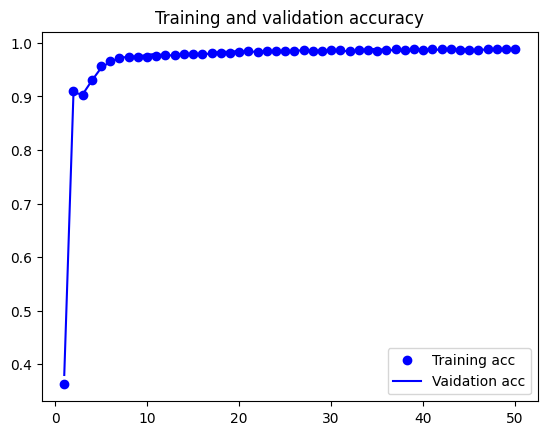

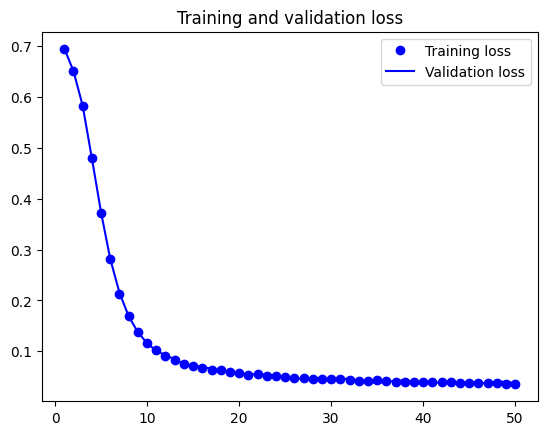

/tmp/ipykernel_423/2181039425.py:169: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_pred = model(torch.tensor(x_test).float())[0] > .5


f1-score :  0.9034749034749034
precision :  0.9512195121951219
recall :  0.8602941176470589
accuracy :  0.9816446402349486
              precision    recall  f1-score   support

           0       0.98      1.00      0.99      1226
           1       0.95      0.86      0.90       136

    accuracy                           0.98      1362
   macro avg       0.97      0.93      0.95      1362
weighted avg       0.98      0.98      0.98      1362

[[1220    6]
 [  19  117]]
final report [{'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'German-French', 'class': '0', 'precision': 0.98, 'recall': 1.0, 'f1_score': 0.99, 'support': 1226.0}, {'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'German-French', 'class': '1', 'precision': 0.95, 'recall': 0.86, 'f1_score': 0.9, 'support': 136.0, 'acc': 0.98}]

Training and evaluating on English-German
epoch 0
                    Train set - loss: 0.681, accuracy: 0.79 
                    V

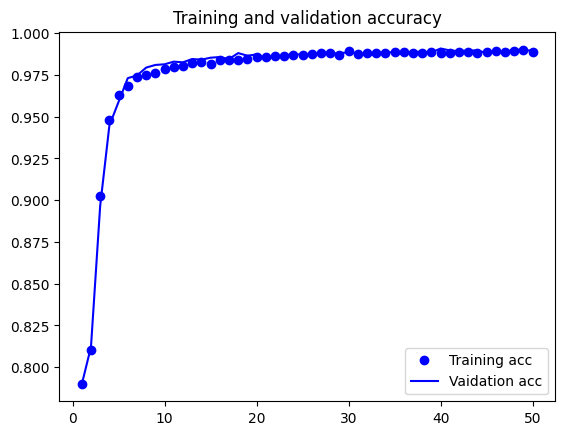

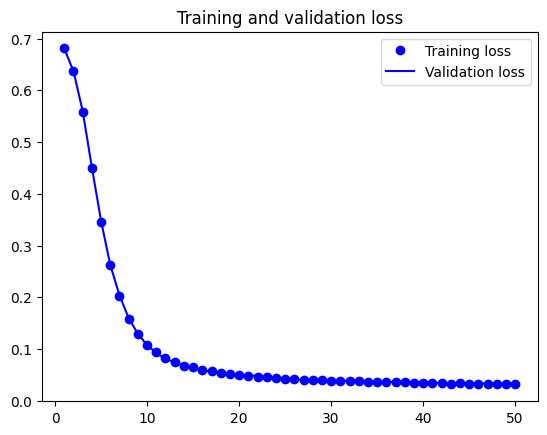

/tmp/ipykernel_423/2181039425.py:169: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_pred = model(torch.tensor(x_test).float())[0] > .5


f1-score :  0.9148936170212766
precision :  0.9555555555555556
recall :  0.8775510204081632
accuracy :  0.9836790207412445
              precision    recall  f1-score   support

           0       0.99      1.00      0.99      2647
           1       0.96      0.88      0.91       294

    accuracy                           0.98      2941
   macro avg       0.97      0.94      0.95      2941
weighted avg       0.98      0.98      0.98      2941

[[2635   12]
 [  36  258]]
final report [{'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'English-German', 'class': '0', 'precision': 0.99, 'recall': 1.0, 'f1_score': 0.99, 'support': 2647.0}, {'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'English-German', 'class': '1', 'precision': 0.96, 'recall': 0.88, 'f1_score': 0.91, 'support': 294.0, 'acc': 0.98}]

Training and evaluating on Romanian-Hungarian
epoch 0
                    Train set - loss: 0.671, accuracy: 0.853 
             

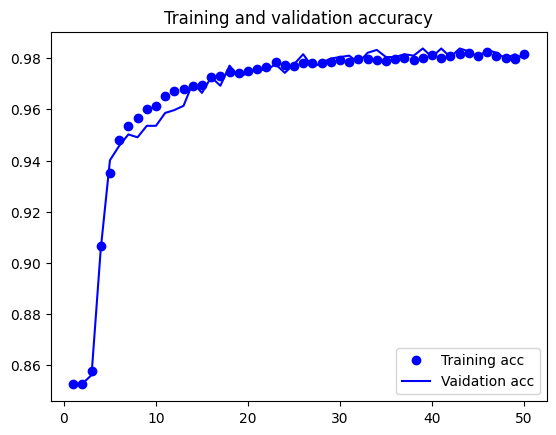

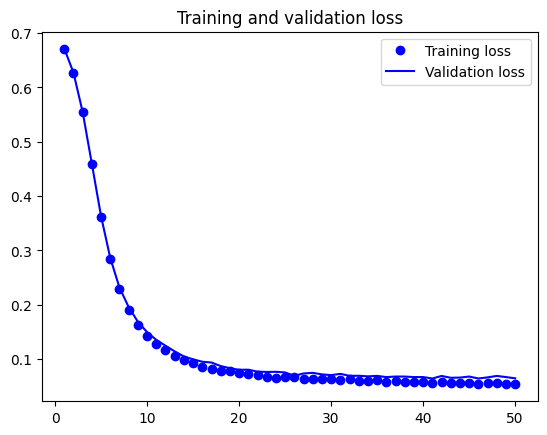

/tmp/ipykernel_423/2181039425.py:169: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_pred = model(torch.tensor(x_test).float())[0] > .5


f1-score :  0.7413127413127413
precision :  0.8421052631578947
recall :  0.6620689655172414
accuracy :  0.9540150995195608
              precision    recall  f1-score   support

           0       0.96      0.99      0.97      1312
           1       0.84      0.66      0.74       145

    accuracy                           0.95      1457
   macro avg       0.90      0.82      0.86      1457
weighted avg       0.95      0.95      0.95      1457

[[1294   18]
 [  49   96]]
final report [{'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'Romanian-Hungarian', 'class': '0', 'precision': 0.96, 'recall': 0.99, 'f1_score': 0.97, 'support': 1312.0}, {'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'Romanian-Hungarian', 'class': '1', 'precision': 0.84, 'recall': 0.66, 'f1_score': 0.74, 'support': 145.0, 'acc': 0.95}]

Training and evaluating on Polish-French
epoch 0
                    Train set - loss: 0.684, accuracy: 0.802 
         

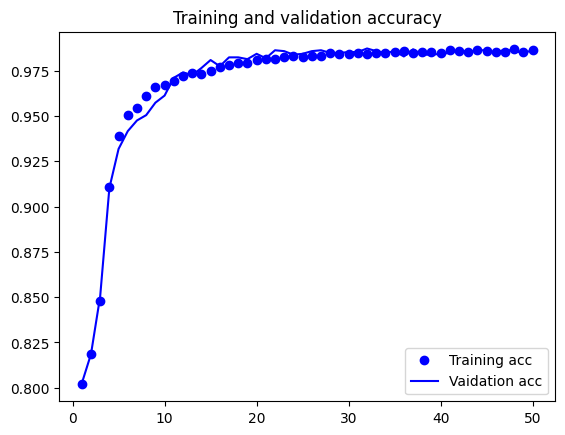

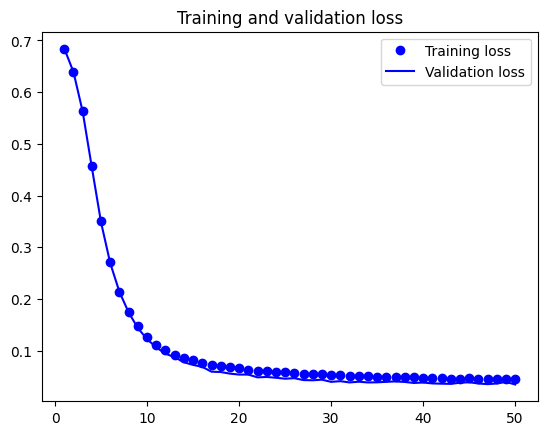

/tmp/ipykernel_423/2181039425.py:169: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_pred = model(torch.tensor(x_test).float())[0] > .5


f1-score :  0.835509138381201
precision :  0.898876404494382
recall :  0.7804878048780488
accuracy :  0.9692982456140351
              precision    recall  f1-score   support

           0       0.98      0.99      0.98      1847
           1       0.90      0.78      0.84       205

    accuracy                           0.97      2052
   macro avg       0.94      0.89      0.91      2052
weighted avg       0.97      0.97      0.97      2052

[[1829   18]
 [  45  160]]
final report [{'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'Polish-French', 'class': '0', 'precision': 0.98, 'recall': 0.99, 'f1_score': 0.98, 'support': 1847.0}, {'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'Polish-French', 'class': '1', 'precision': 0.9, 'recall': 0.78, 'f1_score': 0.84, 'support': 205.0, 'acc': 0.97}]

Training and evaluating on Indonesian-Dutch
epoch 0
                    Train set - loss: 0.687, accuracy: 0.612 
                   

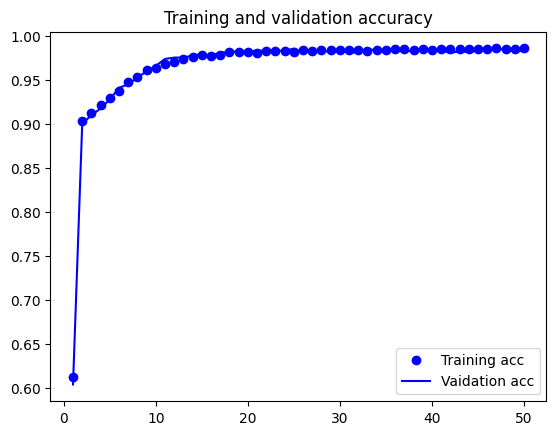

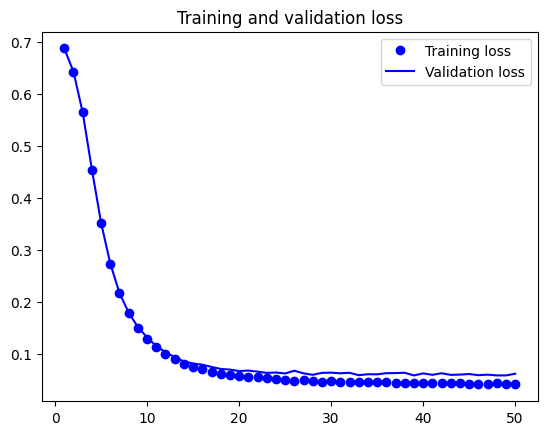

/tmp/ipykernel_423/2181039425.py:169: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_pred = model(torch.tensor(x_test).float())[0] > .5


f1-score :  0.9384615384615385
precision :  0.9606299212598425
recall :  0.9172932330827067
accuracy :  0.9518796992481203
              precision    recall  f1-score   support

           0       0.95      0.97      0.96       399
           1       0.96      0.92      0.94       266

    accuracy                           0.95       665
   macro avg       0.95      0.95      0.95       665
weighted avg       0.95      0.95      0.95       665

[[389  10]
 [ 22 244]]
final report [{'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'Indonesian-Dutch', 'class': '0', 'precision': 0.95, 'recall': 0.97, 'f1_score': 0.96, 'support': 399.0}, {'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'Indonesian-Dutch', 'class': '1', 'precision': 0.96, 'recall': 0.92, 'f1_score': 0.94, 'support': 266.0, 'acc': 0.95}]

Training and evaluating on Romanian-French
epoch 0
                    Train set - loss: 0.684, accuracy: 0.731 
                

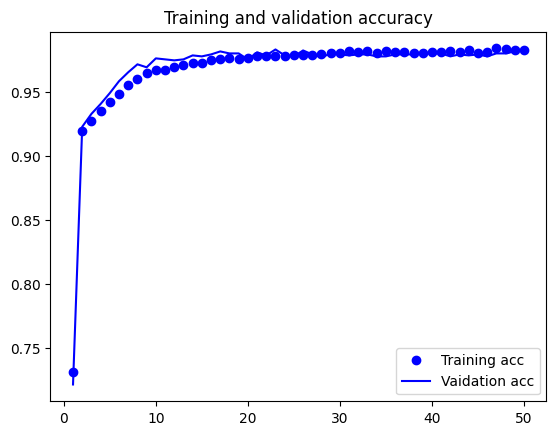

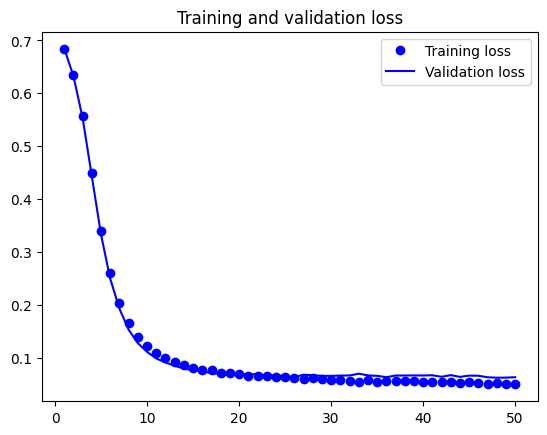

f1-score :  0.8853333333333333
precision :  0.9431818181818182
recall :  0.8341708542713567
accuracy :  0.9352409638554217
              precision    recall  f1-score   support

           0       0.93      0.98      0.95       465
           1       0.94      0.83      0.89       199

    accuracy                           0.94       664
   macro avg       0.94      0.91      0.92       664
weighted avg       0.94      0.94      0.93       664

[[455  10]
 [ 33 166]]
final report [{'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'Romanian-French', 'class': '0', 'precision': 0.93, 'recall': 0.98, 'f1_score': 0.95, 'support': 465.0}, {'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'Romanian-French', 'class': '1', 'precision': 0.94, 'recall': 0.83, 'f1_score': 0.89, 'support': 199.0, 'acc': 0.94}]


Zip ready: /content/result_zips/real_dist__NN_results.zip  (125 KB)
    Final_results/real_dist/NN_results/all_lang_falseneg.csv
 

/tmp/ipykernel_423/2181039425.py:169: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_pred = model(torch.tensor(x_test).float())[0] > .5


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

'/content/result_zips/real_dist__NN_results.zip'

In [16]:
print("Evaluating NN on real_dist splits\n")
results = nn_evaluate(train_realdist, test_realdist, pairs)
save_eval_results(result_dir("real_dist", "NN"), *results)

### NN - balanced

Evaluating NN on balanced splits

NeuralNetwork(
  (linear_relu_stack): Sequential(
    (0): Linear(in_features=34, out_features=512, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.1, inplace=False)
    (3): Linear(in_features=512, out_features=256, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.1, inplace=False)
    (6): Linear(in_features=256, out_features=128, bias=True)
    (7): ReLU()
    (8): Dropout(p=0.1, inplace=False)
    (9): Linear(in_features=128, out_features=1, bias=True)
  )
)
Training on all langs

epoch 0
                    Train set - loss: 0.698, accuracy: 0.456 
                    Val set - loss: 0.698, accuracy: 0.457
epoch 100
                    Train set - loss: 0.656, accuracy: 0.858 
                    Val set - loss: 0.656, accuracy: 0.867
epoch 200
                    Train set - loss: 0.581, accuracy: 0.898 
                    Val set - loss: 0.58, accuracy: 0.903
epoch 300
                    Train set - loss: 0.474, accuracy: 0.911 
               

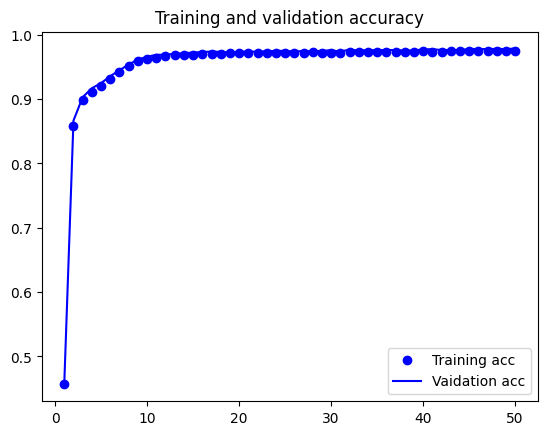

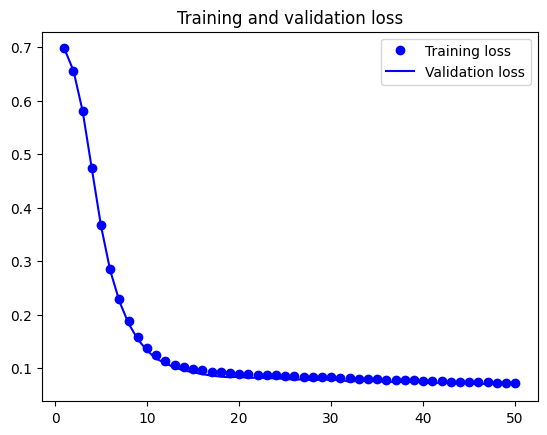

/tmp/ipykernel_423/2181039425.py:62: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_pred = model(torch.tensor(x_test).float())[0] > .5
/tmp/ipykernel_423/2181039425.py:101: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_pred = model(torch.tensor(x_test).float())[0] > .5
/tmp/ipykernel_423/2181039425.py:101: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_pred = model(torch.tensor(x_test).float())[0] > .5
/tmp/ipykernel_423/2181039425.py:101: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clo

f1-score :  0.977962577962578
precision :  0.9751243781094527
recall :  0.9808173477898249
accuracy :  0.9778566952162105
              precision    recall  f1-score   support

           0       0.98      0.97      0.98      2389
           1       0.98      0.98      0.98      2398

    accuracy                           0.98      4787
   macro avg       0.98      0.98      0.98      4787
weighted avg       0.98      0.98      0.98      4787

[[2329   60]
 [  46 2352]]
final report [{'all_language_evaluate': True, 'train_evaluate_pair': False, 'language_pair': None, 'class': '0', 'precision': 0.98, 'recall': 0.97, 'f1_score': 0.98, 'support': 2389.0}, {'all_language_evaluate': True, 'train_evaluate_pair': False, 'language_pair': None, 'class': '1', 'precision': 0.98, 'recall': 0.98, 'f1_score': 0.98, 'support': 2398.0, 'acc': 0.98}]

Evaluating on Hindi-Persian
f1-score :  0.984251968503937
precision :  0.9689922480620154
recall :  1.0
accuracy :  0.9839357429718876
              pre

/tmp/ipykernel_423/2181039425.py:101: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_pred = model(torch.tensor(x_test).float())[0] > .5
/tmp/ipykernel_423/2181039425.py:101: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_pred = model(torch.tensor(x_test).float())[0] > .5
/tmp/ipykernel_423/2181039425.py:101: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_pred = model(torch.tensor(x_test).float())[0] > .5
/tmp/ipykernel_423/2181039425.py:101: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().cl

precision :  0.9926470588235294
recall :  0.9854014598540146
accuracy :  0.9889705882352942
              precision    recall  f1-score   support

           0       0.99      0.99      0.99       135
           1       0.99      0.99      0.99       137

    accuracy                           0.99       272
   macro avg       0.99      0.99      0.99       272
weighted avg       0.99      0.99      0.99       272

[[134   1]
 [  2 135]]
final report [{'all_language_evaluate': False, 'train_evaluate_pair': False, 'language_pair': 'German-French', 'class': '0', 'precision': 0.99, 'recall': 0.99, 'f1_score': 0.99, 'support': 135.0}, {'all_language_evaluate': False, 'train_evaluate_pair': False, 'language_pair': 'German-French', 'class': '1', 'precision': 0.99, 'recall': 0.99, 'f1_score': 0.99, 'support': 137.0, 'acc': 0.99}]

Evaluating on English-German
f1-score :  0.9814502529510961
precision :  0.9765100671140939
recall :  0.9864406779661017
accuracy :  0.9812925170068028
            

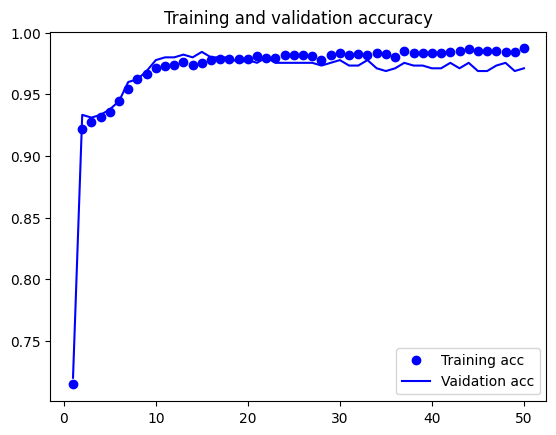

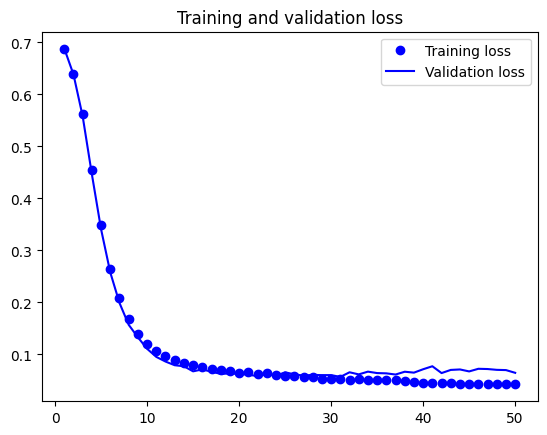

/tmp/ipykernel_423/2181039425.py:169: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_pred = model(torch.tensor(x_test).float())[0] > .5


f1-score :  0.9802371541501976
precision :  0.96875
recall :  0.992
accuracy :  0.9799196787148594
              precision    recall  f1-score   support

           0       0.99      0.97      0.98       124
           1       0.97      0.99      0.98       125

    accuracy                           0.98       249
   macro avg       0.98      0.98      0.98       249
weighted avg       0.98      0.98      0.98       249

[[120   4]
 [  1 124]]
final report [{'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'Hindi-Persian', 'class': '0', 'precision': 0.99, 'recall': 0.97, 'f1_score': 0.98, 'support': 124.0}, {'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'Hindi-Persian', 'class': '1', 'precision': 0.97, 'recall': 0.99, 'f1_score': 0.98, 'support': 125.0, 'acc': 0.98}]

Training and evaluating on English-French
epoch 0
                    Train set - loss: 0.696, accuracy: 0.457 
                    Val set - loss: 0.696, accu

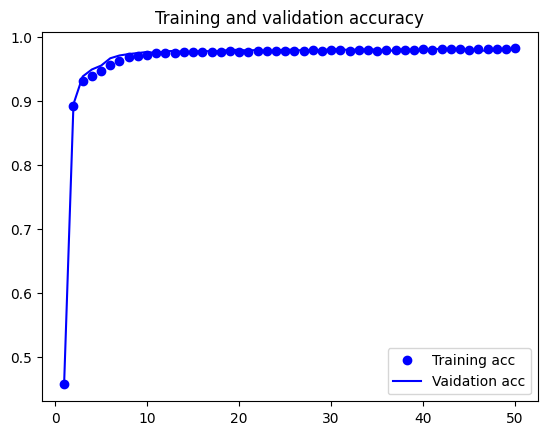

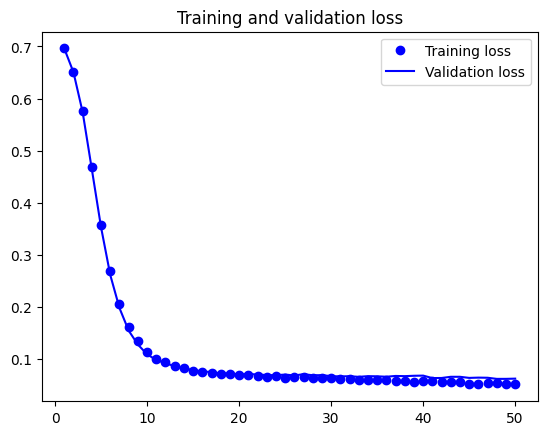

/tmp/ipykernel_423/2181039425.py:169: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_pred = model(torch.tensor(x_test).float())[0] > .5


f1-score :  0.9823529411764705
precision :  0.978515625
recall :  0.9862204724409449
accuracy :  0.9822660098522168
              precision    recall  f1-score   support

           0       0.99      0.98      0.98       507
           1       0.98      0.99      0.98       508

    accuracy                           0.98      1015
   macro avg       0.98      0.98      0.98      1015
weighted avg       0.98      0.98      0.98      1015

[[496  11]
 [  7 501]]
final report [{'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'English-French', 'class': '0', 'precision': 0.99, 'recall': 0.98, 'f1_score': 0.98, 'support': 507.0}, {'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'English-French', 'class': '1', 'precision': 0.98, 'recall': 0.99, 'f1_score': 0.98, 'support': 508.0, 'acc': 0.98}]

Training and evaluating on Finnish-Swedish
epoch 0
                    Train set - loss: 0.695, accuracy: 0.487 
                    Val set

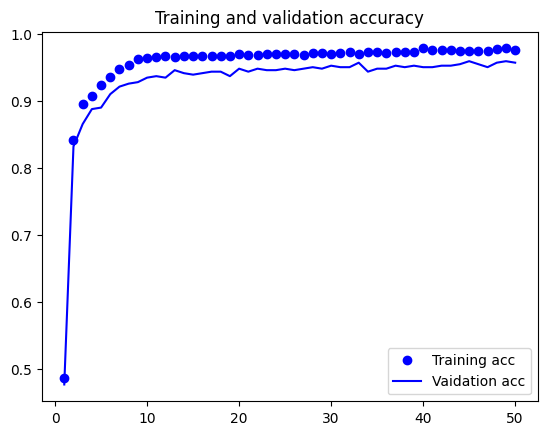

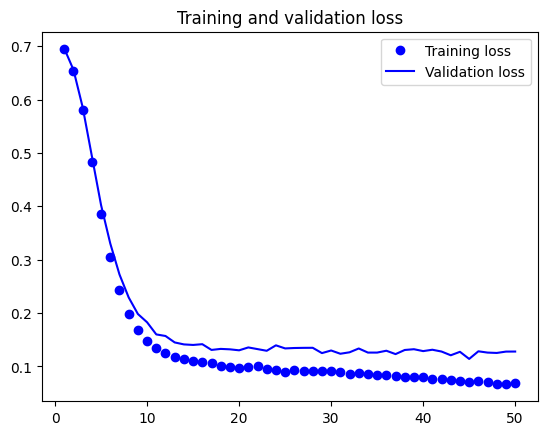

/tmp/ipykernel_423/2181039425.py:169: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_pred = model(torch.tensor(x_test).float())[0] > .5


f1-score :  0.9644268774703557
precision :  0.953125
recall :  0.976
accuracy :  0.964
              precision    recall  f1-score   support

           0       0.98      0.95      0.96       125
           1       0.95      0.98      0.96       125

    accuracy                           0.96       250
   macro avg       0.96      0.96      0.96       250
weighted avg       0.96      0.96      0.96       250

[[119   6]
 [  3 122]]
final report [{'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'Finnish-Swedish', 'class': '0', 'precision': 0.98, 'recall': 0.95, 'f1_score': 0.96, 'support': 125.0}, {'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'Finnish-Swedish', 'class': '1', 'precision': 0.95, 'recall': 0.98, 'f1_score': 0.96, 'support': 125.0, 'acc': 0.96}]

Training and evaluating on Kazakh-Russian
epoch 0
                    Train set - loss: 0.689, accuracy: 0.569 
                    Val set - loss: 0.69, accuracy: 0.5

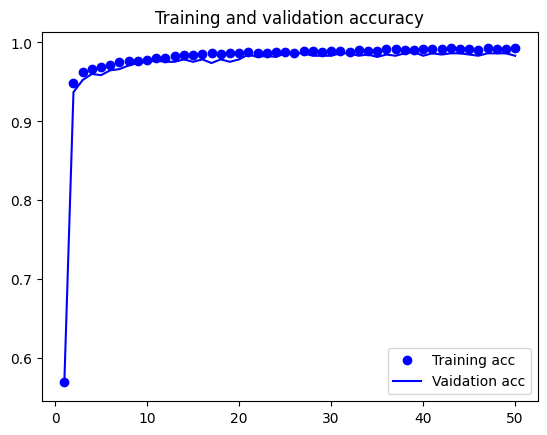

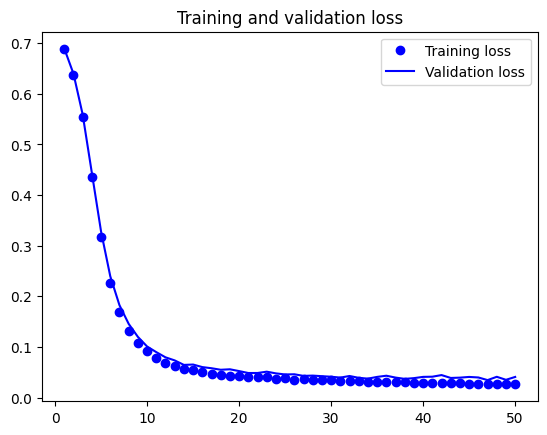

/tmp/ipykernel_423/2181039425.py:169: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_pred = model(torch.tensor(x_test).float())[0] > .5


f1-score :  0.9945054945054945
precision :  0.9890710382513661
recall :  1.0
accuracy :  0.9945054945054945
              precision    recall  f1-score   support

           0       1.00      0.99      0.99       183
           1       0.99      1.00      0.99       181

    accuracy                           0.99       364
   macro avg       0.99      0.99      0.99       364
weighted avg       0.99      0.99      0.99       364

[[181   2]
 [  0 181]]
final report [{'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'Kazakh-Russian', 'class': '0', 'precision': 1.0, 'recall': 0.99, 'f1_score': 0.99, 'support': 183.0}, {'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'Kazakh-Russian', 'class': '1', 'precision': 0.99, 'recall': 1.0, 'f1_score': 0.99, 'support': 181.0, 'acc': 0.99}]

Training and evaluating on Azerbaijani-Arabic
epoch 0
                    Train set - loss: 0.696, accuracy: 0.5 
                    Val set - loss: 

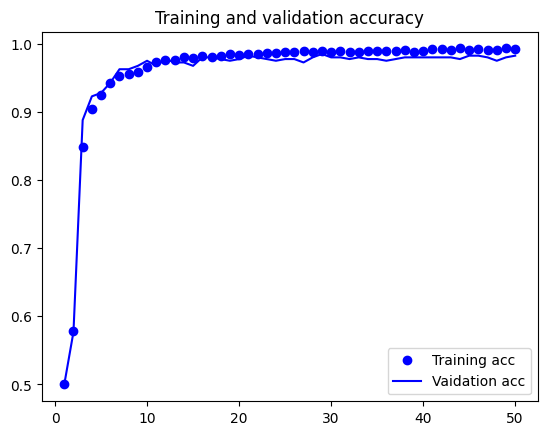

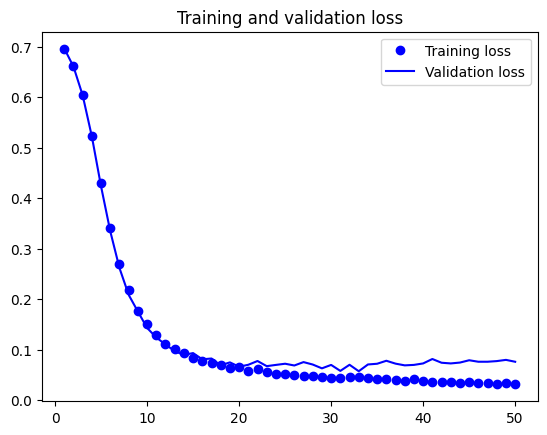

/tmp/ipykernel_423/2181039425.py:169: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_pred = model(torch.tensor(x_test).float())[0] > .5


f1-score :  0.9821428571428571
precision :  0.9821428571428571
recall :  0.9821428571428571
accuracy :  0.9821428571428571
              precision    recall  f1-score   support

           0       0.98      0.98      0.98       112
           1       0.98      0.98      0.98       112

    accuracy                           0.98       224
   macro avg       0.98      0.98      0.98       224
weighted avg       0.98      0.98      0.98       224

[[110   2]
 [  2 110]]
final report [{'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'Azerbaijani-Arabic', 'class': '0', 'precision': 0.98, 'recall': 0.98, 'f1_score': 0.98, 'support': 112.0}, {'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'Azerbaijani-Arabic', 'class': '1', 'precision': 0.98, 'recall': 0.98, 'f1_score': 0.98, 'support': 112.0, 'acc': 0.98}]

Training and evaluating on Chinese-English
epoch 0
                    Train set - loss: 0.694, accuracy: 0.469 
            

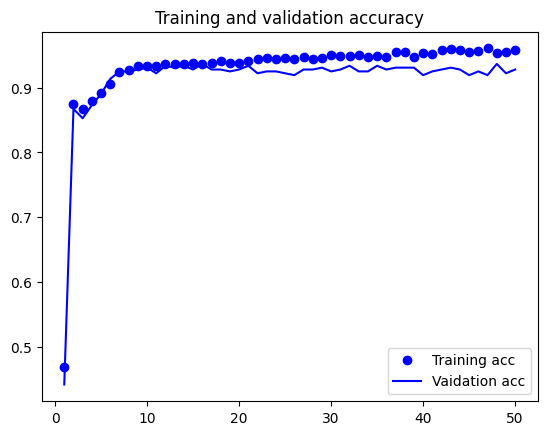

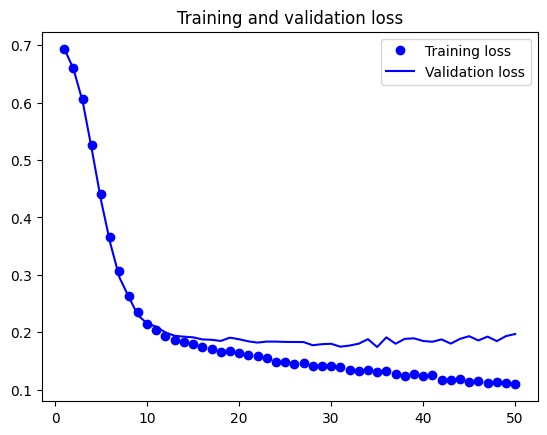

/tmp/ipykernel_423/2181039425.py:169: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_pred = model(torch.tensor(x_test).float())[0] > .5


f1-score :  0.9629629629629629
precision :  0.978494623655914
recall :  0.9479166666666666
accuracy :  0.9631578947368421
              precision    recall  f1-score   support

           0       0.95      0.98      0.96        94
           1       0.98      0.95      0.96        96

    accuracy                           0.96       190
   macro avg       0.96      0.96      0.96       190
weighted avg       0.96      0.96      0.96       190

[[92  2]
 [ 5 91]]
final report [{'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'Chinese-English', 'class': '0', 'precision': 0.95, 'recall': 0.98, 'f1_score': 0.96, 'support': 94.0}, {'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'Chinese-English', 'class': '1', 'precision': 0.98, 'recall': 0.95, 'f1_score': 0.96, 'support': 96.0, 'acc': 0.96}]

Training and evaluating on German-French
epoch 0
                    Train set - loss: 0.691, accuracy: 0.608 
                    Val set

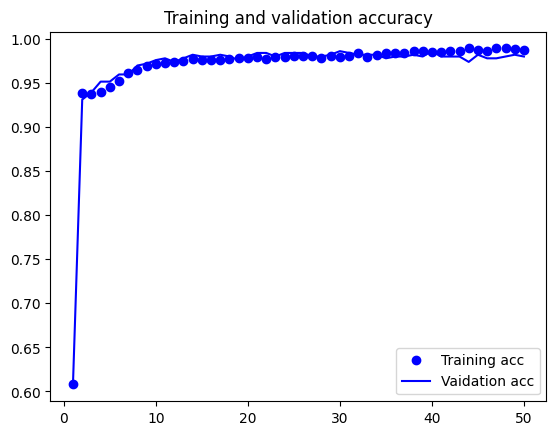

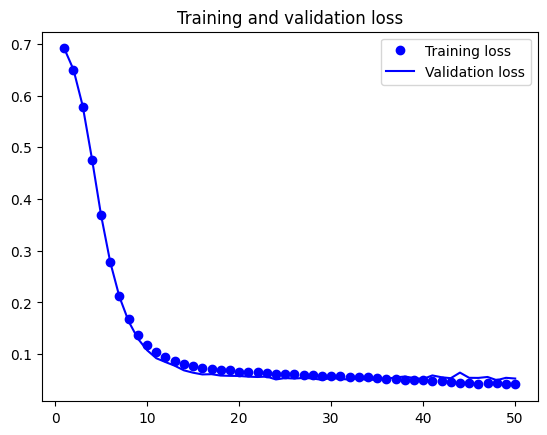

/tmp/ipykernel_423/2181039425.py:169: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_pred = model(torch.tensor(x_test).float())[0] > .5


f1-score :  0.989010989010989
precision :  0.9926470588235294
recall :  0.9854014598540146
accuracy :  0.9889705882352942
              precision    recall  f1-score   support

           0       0.99      0.99      0.99       135
           1       0.99      0.99      0.99       137

    accuracy                           0.99       272
   macro avg       0.99      0.99      0.99       272
weighted avg       0.99      0.99      0.99       272

[[134   1]
 [  2 135]]
final report [{'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'German-French', 'class': '0', 'precision': 0.99, 'recall': 0.99, 'f1_score': 0.99, 'support': 135.0}, {'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'German-French', 'class': '1', 'precision': 0.99, 'recall': 0.99, 'f1_score': 0.99, 'support': 137.0, 'acc': 0.99}]

Training and evaluating on English-German
epoch 0
                    Train set - loss: 0.697, accuracy: 0.5 
                    Val se

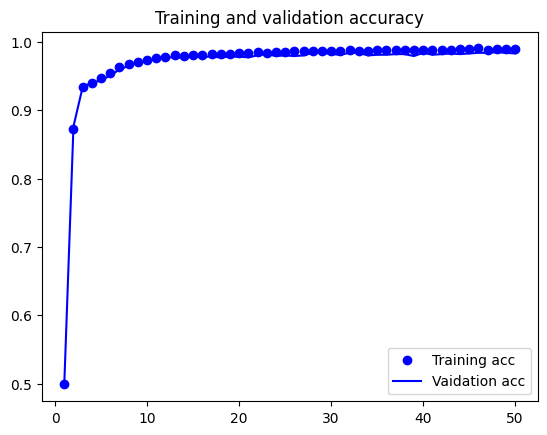

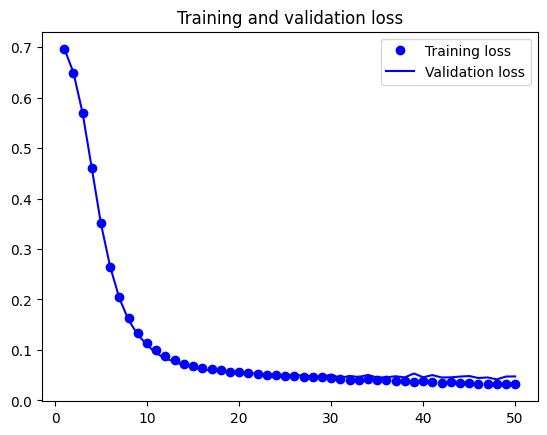

/tmp/ipykernel_423/2181039425.py:169: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_pred = model(torch.tensor(x_test).float())[0] > .5


f1-score :  0.9830508474576272
precision :  0.9830508474576272
recall :  0.9830508474576272
accuracy :  0.9829931972789115
              precision    recall  f1-score   support

           0       0.98      0.98      0.98       293
           1       0.98      0.98      0.98       295

    accuracy                           0.98       588
   macro avg       0.98      0.98      0.98       588
weighted avg       0.98      0.98      0.98       588

[[288   5]
 [  5 290]]
final report [{'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'English-German', 'class': '0', 'precision': 0.98, 'recall': 0.98, 'f1_score': 0.98, 'support': 293.0}, {'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'English-German', 'class': '1', 'precision': 0.98, 'recall': 0.98, 'f1_score': 0.98, 'support': 295.0, 'acc': 0.98}]

Training and evaluating on Romanian-Hungarian
epoch 0
                    Train set - loss: 0.698, accuracy: 0.499 
                 

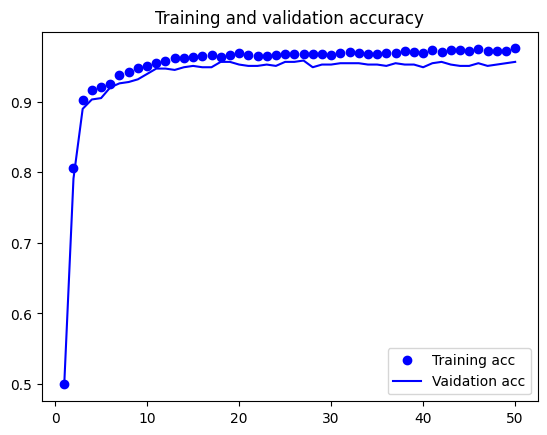

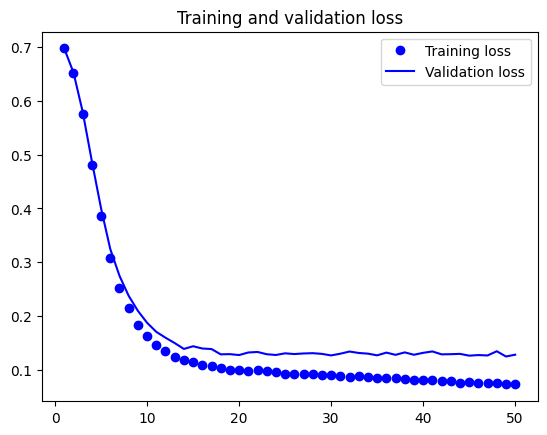

/tmp/ipykernel_423/2181039425.py:169: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_pred = model(torch.tensor(x_test).float())[0] > .5


f1-score :  0.9652777777777778
precision :  0.9788732394366197
recall :  0.952054794520548
accuracy :  0.9657534246575342
              precision    recall  f1-score   support

           0       0.95      0.98      0.97       146
           1       0.98      0.95      0.97       146

    accuracy                           0.97       292
   macro avg       0.97      0.97      0.97       292
weighted avg       0.97      0.97      0.97       292

[[143   3]
 [  7 139]]
final report [{'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'Romanian-Hungarian', 'class': '0', 'precision': 0.95, 'recall': 0.98, 'f1_score': 0.97, 'support': 146.0}, {'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'Romanian-Hungarian', 'class': '1', 'precision': 0.98, 'recall': 0.95, 'f1_score': 0.97, 'support': 146.0, 'acc': 0.97}]

Training and evaluating on Polish-French
epoch 0
                    Train set - loss: 0.702, accuracy: 0.475 
               

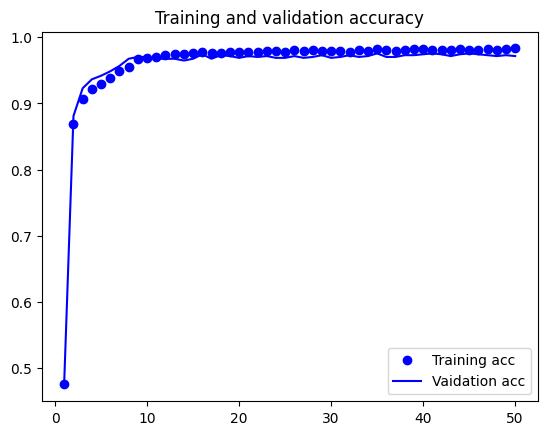

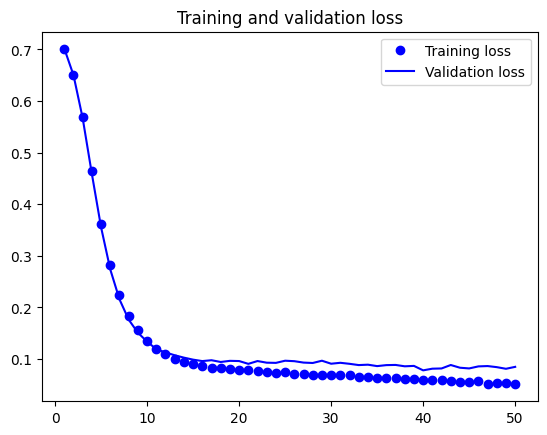

/tmp/ipykernel_423/2181039425.py:169: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_pred = model(torch.tensor(x_test).float())[0] > .5


f1-score :  0.9710144927536232
precision :  0.9663461538461539
recall :  0.9757281553398058
accuracy :  0.9707317073170731
              precision    recall  f1-score   support

           0       0.98      0.97      0.97       204
           1       0.97      0.98      0.97       206

    accuracy                           0.97       410
   macro avg       0.97      0.97      0.97       410
weighted avg       0.97      0.97      0.97       410

[[197   7]
 [  5 201]]
final report [{'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'Polish-French', 'class': '0', 'precision': 0.98, 'recall': 0.97, 'f1_score': 0.97, 'support': 204.0}, {'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'Polish-French', 'class': '1', 'precision': 0.97, 'recall': 0.98, 'f1_score': 0.97, 'support': 206.0, 'acc': 0.97}]

Training and evaluating on Indonesian-Dutch
epoch 0
                    Train set - loss: 0.686, accuracy: 0.687 
                    V

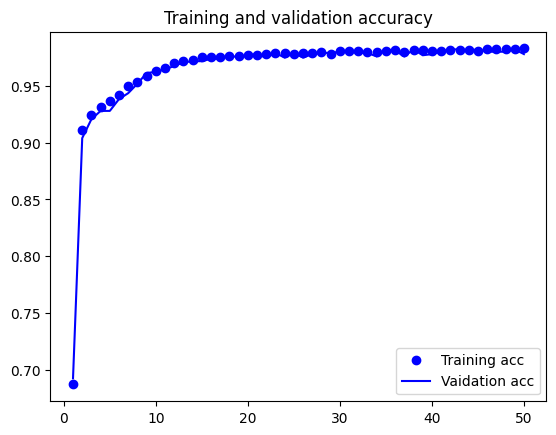

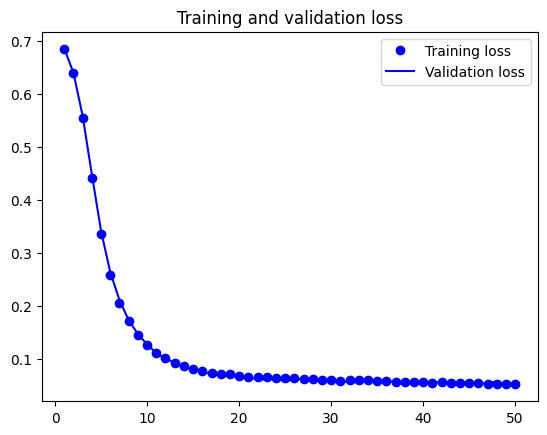

/tmp/ipykernel_423/2181039425.py:169: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_pred = model(torch.tensor(x_test).float())[0] > .5


f1-score :  0.9886792452830189
precision :  0.9961977186311787
recall :  0.9812734082397003
accuracy :  0.9887640449438202
              precision    recall  f1-score   support

           0       0.98      1.00      0.99       267
           1       1.00      0.98      0.99       267

    accuracy                           0.99       534
   macro avg       0.99      0.99      0.99       534
weighted avg       0.99      0.99      0.99       534

[[266   1]
 [  5 262]]
final report [{'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'Indonesian-Dutch', 'class': '0', 'precision': 0.98, 'recall': 1.0, 'f1_score': 0.99, 'support': 267.0}, {'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'Indonesian-Dutch', 'class': '1', 'precision': 1.0, 'recall': 0.98, 'f1_score': 0.99, 'support': 267.0, 'acc': 0.99}]

Training and evaluating on Romanian-French
epoch 0
                    Train set - loss: 0.691, accuracy: 0.522 
                  

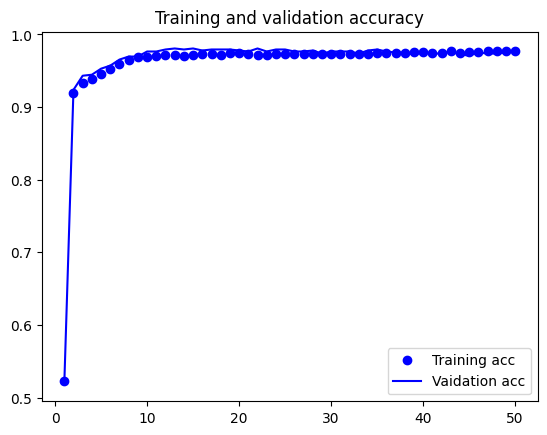

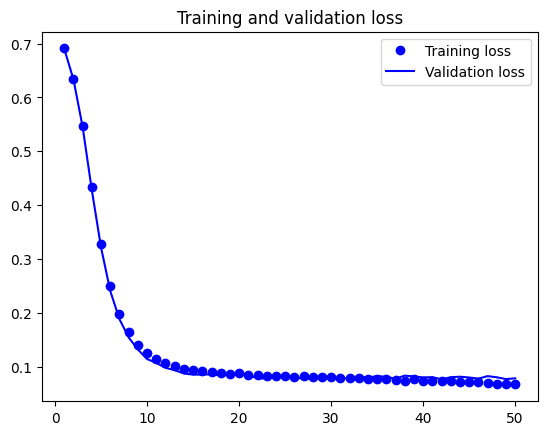

f1-score :  0.9727047146401985
precision :  0.9655172413793104
recall :  0.98
accuracy :  0.9724310776942355
              precision    recall  f1-score   support

           0       0.98      0.96      0.97       199
           1       0.97      0.98      0.97       200

    accuracy                           0.97       399
   macro avg       0.97      0.97      0.97       399
weighted avg       0.97      0.97      0.97       399

[[192   7]
 [  4 196]]
final report [{'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'Romanian-French', 'class': '0', 'precision': 0.98, 'recall': 0.96, 'f1_score': 0.97, 'support': 199.0}, {'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'Romanian-French', 'class': '1', 'precision': 0.97, 'recall': 0.98, 'f1_score': 0.97, 'support': 200.0, 'acc': 0.97}]


Zip ready: /content/result_zips/balanced__NN_results.zip  (27 KB)
    Final_results/balanced/NN_results/all_lang_falseneg.csv
    Final_results/

/tmp/ipykernel_423/2181039425.py:169: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_pred = model(torch.tensor(x_test).float())[0] > .5


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

'/content/result_zips/balanced__NN_results.zip'

In [17]:
print("Evaluating NN on balanced splits\n")
results = nn_evaluate(train_balanced, test_balanced, pairs)
save_eval_results(result_dir("balanced", "NN"), *results)

### NN - pruned (train: realdist minus alldata-test pairs, test: alldata)

Evaluating NN on realdist (train, pruned) and alldata (test)

NeuralNetwork(
  (linear_relu_stack): Sequential(
    (0): Linear(in_features=34, out_features=512, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.1, inplace=False)
    (3): Linear(in_features=512, out_features=256, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.1, inplace=False)
    (6): Linear(in_features=256, out_features=128, bias=True)
    (7): ReLU()
    (8): Dropout(p=0.1, inplace=False)
    (9): Linear(in_features=128, out_features=1, bias=True)
  )
)
Training on all langs

epoch 0
                    Train set - loss: 0.69, accuracy: 0.688 
                    Val set - loss: 0.69, accuracy: 0.684
epoch 100
                    Train set - loss: 0.644, accuracy: 0.785 
                    Val set - loss: 0.644, accuracy: 0.784
epoch 200
                    Train set - loss: 0.565, accuracy: 0.87 
                    Val set - loss: 0.565, accuracy: 0.87
epoch 300
                    Train set - loss: 0.453, accurac

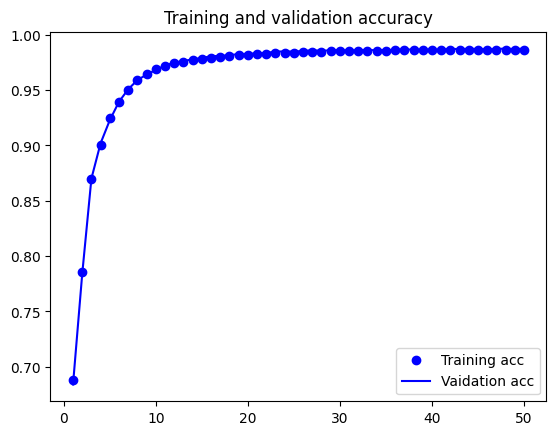

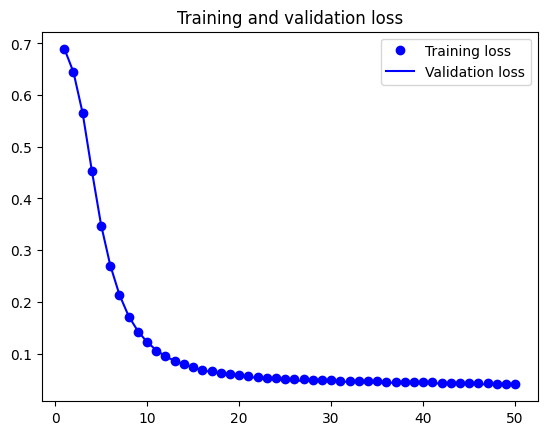

/tmp/ipykernel_423/2181039425.py:62: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_pred = model(torch.tensor(x_test).float())[0] > .5
/tmp/ipykernel_423/2181039425.py:101: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_pred = model(torch.tensor(x_test).float())[0] > .5
/tmp/ipykernel_423/2181039425.py:101: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_pred = model(torch.tensor(x_test).float())[0] > .5
/tmp/ipykernel_423/2181039425.py:101: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clo

f1-score :  0.779335509890532
precision :  0.7192484934420418
recall :  0.8503772003352892
accuracy :  0.9416366129933459
              precision    recall  f1-score   support

           0       0.98      0.95      0.97     17301
           1       0.72      0.85      0.78      2386

    accuracy                           0.94     19687
   macro avg       0.85      0.90      0.87     19687
weighted avg       0.95      0.94      0.94     19687

[[16509   792]
 [  357  2029]]
final report [{'all_language_evaluate': True, 'train_evaluate_pair': False, 'language_pair': None, 'class': '0', 'precision': 0.98, 'recall': 0.95, 'f1_score': 0.97, 'support': 17301.0}, {'all_language_evaluate': True, 'train_evaluate_pair': False, 'language_pair': None, 'class': '1', 'precision': 0.72, 'recall': 0.85, 'f1_score': 0.78, 'support': 2386.0, 'acc': 0.94}]

Evaluating on Hindi-Persian
f1-score :  0.6802325581395349
precision :  0.5318181818181819
recall :  0.9435483870967742
accuracy :  0.9106417546709

/tmp/ipykernel_423/2181039425.py:101: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_pred = model(torch.tensor(x_test).float())[0] > .5
/tmp/ipykernel_423/2181039425.py:101: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_pred = model(torch.tensor(x_test).float())[0] > .5
/tmp/ipykernel_423/2181039425.py:101: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_pred = model(torch.tensor(x_test).float())[0] > .5
/tmp/ipykernel_423/2181039425.py:101: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().cl

              precision    recall  f1-score   support

           0       0.97      0.97      0.97      1470
           1       0.77      0.80      0.78       205

    accuracy                           0.95      1675
   macro avg       0.87      0.88      0.88      1675
weighted avg       0.95      0.95      0.95      1675

[[1421   49]
 [  42  163]]
final report [{'all_language_evaluate': False, 'train_evaluate_pair': False, 'language_pair': 'Polish-French', 'class': '0', 'precision': 0.97, 'recall': 0.97, 'f1_score': 0.97, 'support': 1470.0}, {'all_language_evaluate': False, 'train_evaluate_pair': False, 'language_pair': 'Polish-French', 'class': '1', 'precision': 0.77, 'recall': 0.8, 'f1_score': 0.78, 'support': 205.0, 'acc': 0.95}]

Evaluating on Indonesian-Dutch
f1-score :  0.8257191201353637
precision :  0.7507692307692307
recall :  0.9172932330827067
accuracy :  0.9458464773922187
              precision    recall  f1-score   support

           0       0.99      0.95      0.97

/tmp/ipykernel_423/2181039425.py:101: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_pred = model(torch.tensor(x_test).float())[0] > .5
/tmp/ipykernel_423/2181039425.py:101: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_pred = model(torch.tensor(x_test).float())[0] > .5


epoch 100
                    Train set - loss: 0.636, accuracy: 0.97 
                    Val set - loss: 0.638, accuracy: 0.963
epoch 200
                    Train set - loss: 0.548, accuracy: 0.972 
                    Val set - loss: 0.556, accuracy: 0.961
epoch 300
                    Train set - loss: 0.43, accuracy: 0.973 
                    Val set - loss: 0.442, accuracy: 0.966
epoch 400
                    Train set - loss: 0.313, accuracy: 0.972 
                    Val set - loss: 0.329, accuracy: 0.969
epoch 500
                    Train set - loss: 0.224, accuracy: 0.976 
                    Val set - loss: 0.245, accuracy: 0.972
epoch 600
                    Train set - loss: 0.164, accuracy: 0.977 
                    Val set - loss: 0.186, accuracy: 0.972
epoch 700
                    Train set - loss: 0.126, accuracy: 0.979 
                    Val set - loss: 0.146, accuracy: 0.974
epoch 800
                    Train set - loss: 0.102, accuracy: 0.981 
             

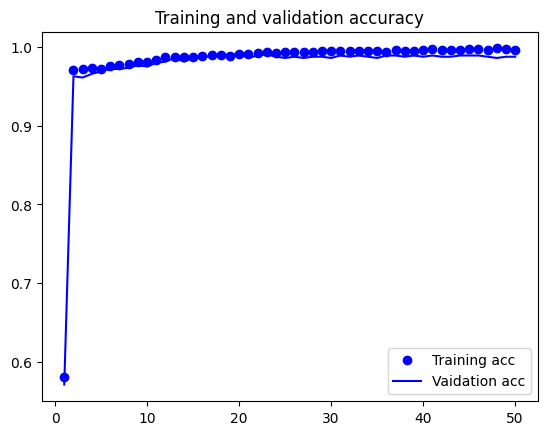

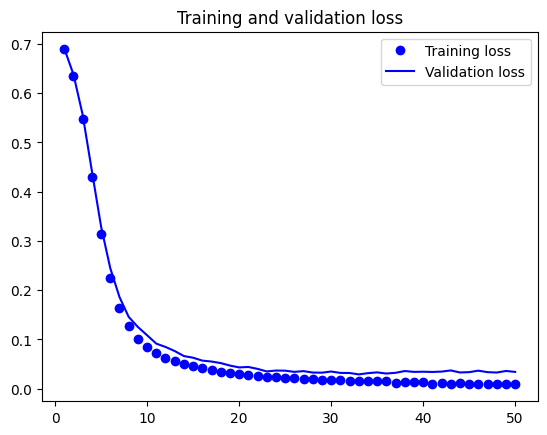

/tmp/ipykernel_423/2181039425.py:169: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_pred = model(torch.tensor(x_test).float())[0] > .5


f1-score :  0.6464088397790055
precision :  0.49159663865546216
recall :  0.9435483870967742
accuracy :  0.8960194963444355
              precision    recall  f1-score   support

           0       0.99      0.89      0.94      1107
           1       0.49      0.94      0.65       124

    accuracy                           0.90      1231
   macro avg       0.74      0.92      0.79      1231
weighted avg       0.94      0.90      0.91      1231

[[986 121]
 [  7 117]]
final report [{'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'Hindi-Persian', 'class': '0', 'precision': 0.99, 'recall': 0.89, 'f1_score': 0.94, 'support': 1107.0}, {'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'Hindi-Persian', 'class': '1', 'precision': 0.49, 'recall': 0.94, 'f1_score': 0.65, 'support': 124.0, 'acc': 0.9}]

Training and evaluating on English-French
epoch 0
                    Train set - loss: 0.688, accuracy: 0.624 
                    Va

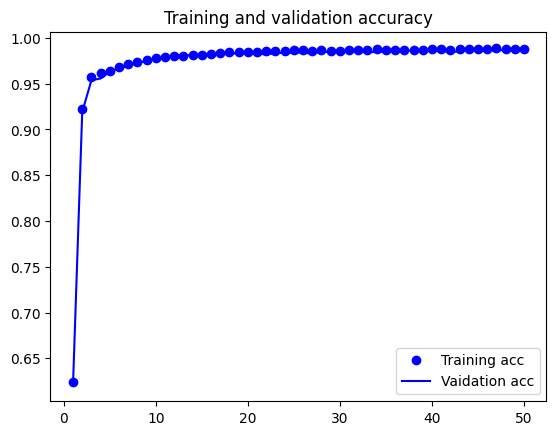

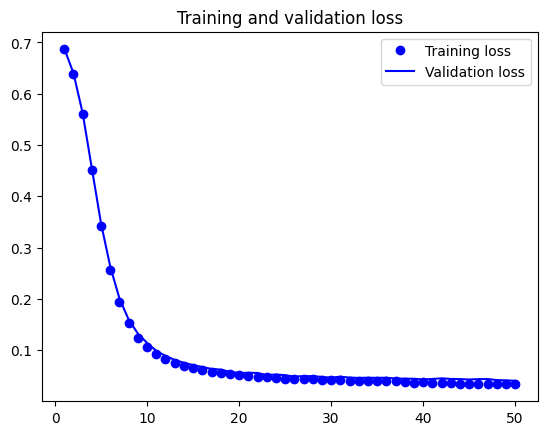

/tmp/ipykernel_423/2181039425.py:169: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_pred = model(torch.tensor(x_test).float())[0] > .5


f1-score :  0.8408091468777484
precision :  0.7587301587301587
recall :  0.9428007889546351
accuracy :  0.9470295580918935
              precision    recall  f1-score   support

           0       0.99      0.95      0.97      2910
           1       0.76      0.94      0.84       507

    accuracy                           0.95      3417
   macro avg       0.87      0.95      0.90      3417
weighted avg       0.96      0.95      0.95      3417

[[2758  152]
 [  29  478]]
final report [{'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'English-French', 'class': '0', 'precision': 0.99, 'recall': 0.95, 'f1_score': 0.97, 'support': 2910.0}, {'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'English-French', 'class': '1', 'precision': 0.76, 'recall': 0.94, 'f1_score': 0.84, 'support': 507.0, 'acc': 0.95}]

Training and evaluating on Finnish-Swedish
epoch 0
                    Train set - loss: 0.681, accuracy: 0.851 
               

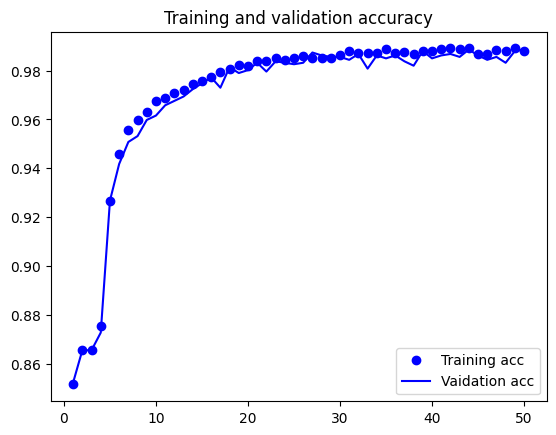

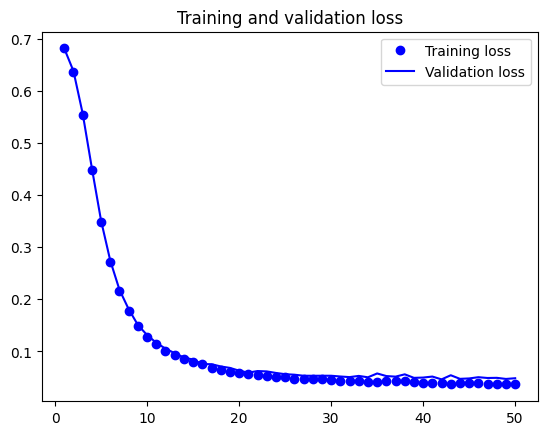

/tmp/ipykernel_423/2181039425.py:169: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_pred = model(torch.tensor(x_test).float())[0] > .5


f1-score :  0.6612903225806451
precision :  0.6612903225806451
recall :  0.6612903225806451
accuracy :  0.933910306845004
              precision    recall  f1-score   support

           0       0.96      0.96      0.96      1147
           1       0.66      0.66      0.66       124

    accuracy                           0.93      1271
   macro avg       0.81      0.81      0.81      1271
weighted avg       0.93      0.93      0.93      1271

[[1105   42]
 [  42   82]]
final report [{'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'Finnish-Swedish', 'class': '0', 'precision': 0.96, 'recall': 0.96, 'f1_score': 0.96, 'support': 1147.0}, {'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'Finnish-Swedish', 'class': '1', 'precision': 0.66, 'recall': 0.66, 'f1_score': 0.66, 'support': 124.0, 'acc': 0.93}]

Training and evaluating on Kazakh-Russian
epoch 0
                    Train set - loss: 0.699, accuracy: 0.234 
               

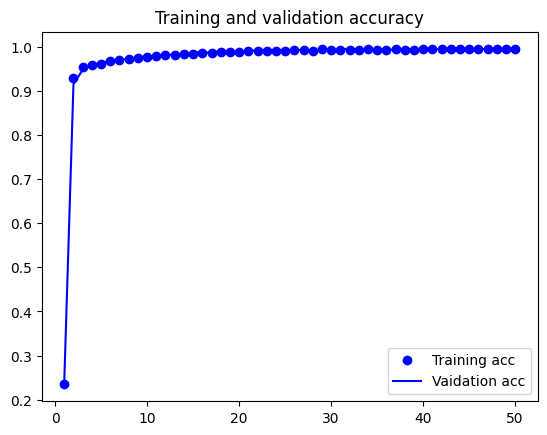

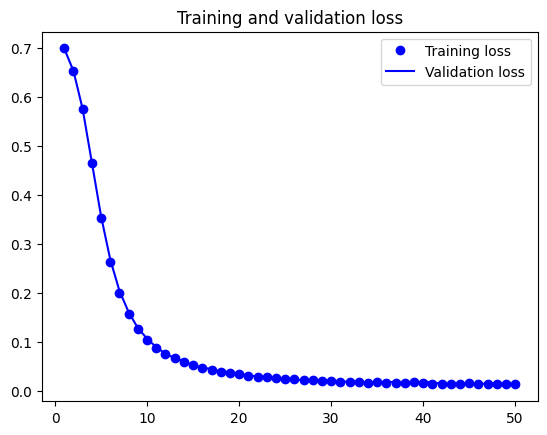

/tmp/ipykernel_423/2181039425.py:169: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_pred = model(torch.tensor(x_test).float())[0] > .5


f1-score :  0.8461538461538461
precision :  0.7857142857142857
recall :  0.9166666666666666
accuracy :  0.9607843137254902
              precision    recall  f1-score   support

           0       0.99      0.97      0.98      1350
           1       0.79      0.92      0.85       180

    accuracy                           0.96      1530
   macro avg       0.89      0.94      0.91      1530
weighted avg       0.96      0.96      0.96      1530

[[1305   45]
 [  15  165]]
final report [{'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'Kazakh-Russian', 'class': '0', 'precision': 0.99, 'recall': 0.97, 'f1_score': 0.98, 'support': 1350.0}, {'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'Kazakh-Russian', 'class': '1', 'precision': 0.79, 'recall': 0.92, 'f1_score': 0.85, 'support': 180.0, 'acc': 0.96}]

Training and evaluating on Azerbaijani-Arabic
epoch 0
                    Train set - loss: 0.735, accuracy: 0.171 
            

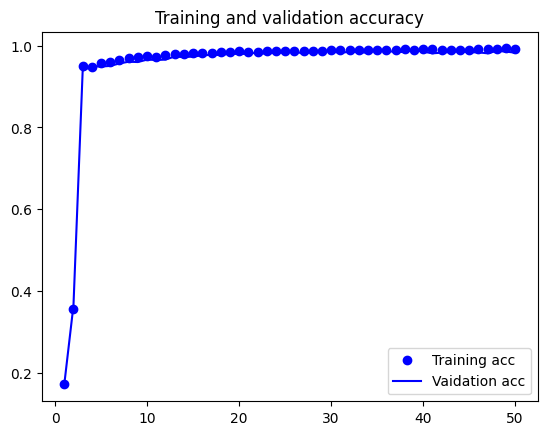

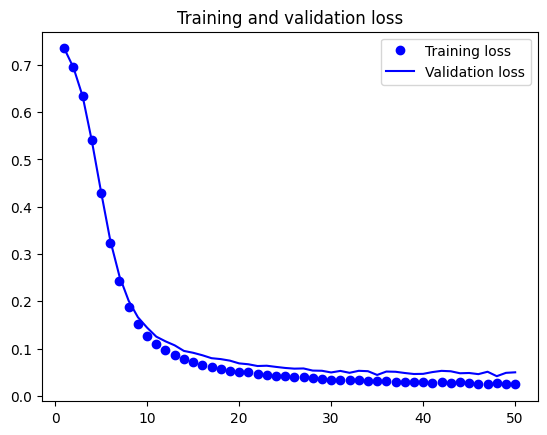

/tmp/ipykernel_423/2181039425.py:169: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_pred = model(torch.tensor(x_test).float())[0] > .5


f1-score :  0.7430830039525692
precision :  0.6619718309859155
recall :  0.8468468468468469
accuracy :  0.9455611390284757
              precision    recall  f1-score   support

           0       0.98      0.96      0.97      1083
           1       0.66      0.85      0.74       111

    accuracy                           0.95      1194
   macro avg       0.82      0.90      0.86      1194
weighted avg       0.95      0.95      0.95      1194

[[1035   48]
 [  17   94]]
final report [{'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'Azerbaijani-Arabic', 'class': '0', 'precision': 0.98, 'recall': 0.96, 'f1_score': 0.97, 'support': 1083.0}, {'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'Azerbaijani-Arabic', 'class': '1', 'precision': 0.66, 'recall': 0.85, 'f1_score': 0.74, 'support': 111.0, 'acc': 0.95}]

Training and evaluating on Chinese-English
epoch 0
                    Train set - loss: 0.694, accuracy: 0.43 
        

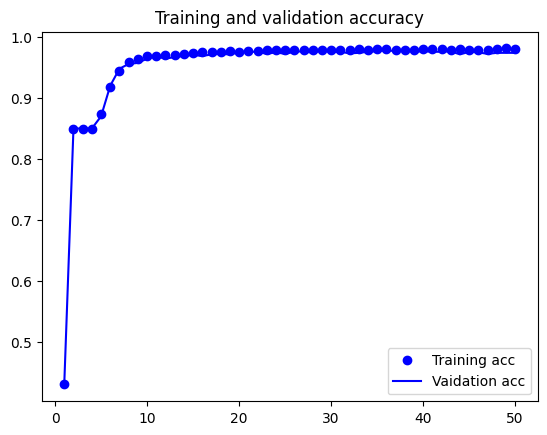

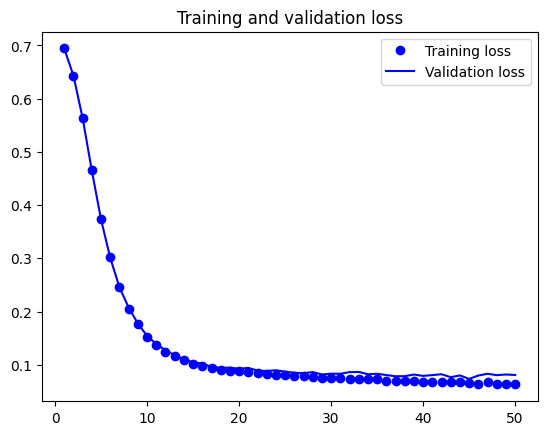

/tmp/ipykernel_423/2181039425.py:169: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_pred = model(torch.tensor(x_test).float())[0] > .5


f1-score :  0.6333333333333333
precision :  0.6705882352941176
recall :  0.6
accuracy :  0.9275521405049396
              precision    recall  f1-score   support

           0       0.95      0.97      0.96       816
           1       0.67      0.60      0.63        95

    accuracy                           0.93       911
   macro avg       0.81      0.78      0.80       911
weighted avg       0.92      0.93      0.93       911

[[788  28]
 [ 38  57]]
final report [{'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'Chinese-English', 'class': '0', 'precision': 0.95, 'recall': 0.97, 'f1_score': 0.96, 'support': 816.0}, {'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'Chinese-English', 'class': '1', 'precision': 0.67, 'recall': 0.6, 'f1_score': 0.63, 'support': 95.0, 'acc': 0.93}]

Training and evaluating on German-French
epoch 0
                    Train set - loss: 0.695, accuracy: 0.374 
                    Val set - loss: 0

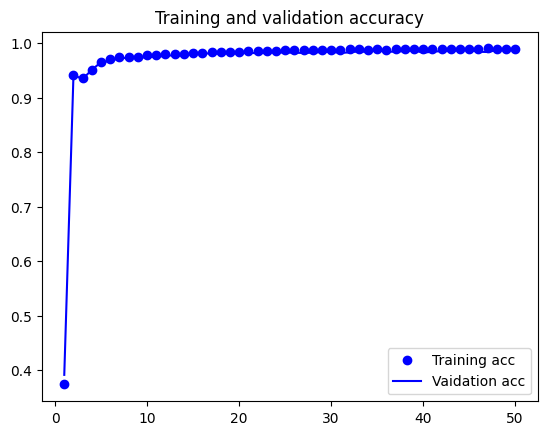

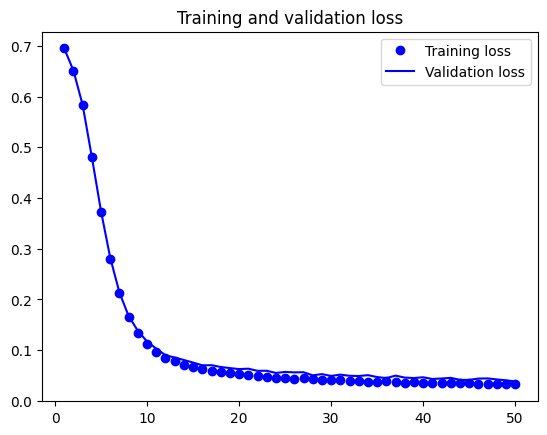

/tmp/ipykernel_423/2181039425.py:169: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_pred = model(torch.tensor(x_test).float())[0] > .5


f1-score :  0.8142857142857143
precision :  0.7916666666666666
recall :  0.8382352941176471
accuracy :  0.9610486891385768
              precision    recall  f1-score   support

           0       0.98      0.97      0.98      1199
           1       0.79      0.84      0.81       136

    accuracy                           0.96      1335
   macro avg       0.89      0.91      0.90      1335
weighted avg       0.96      0.96      0.96      1335

[[1169   30]
 [  22  114]]
final report [{'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'German-French', 'class': '0', 'precision': 0.98, 'recall': 0.97, 'f1_score': 0.98, 'support': 1199.0}, {'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'German-French', 'class': '1', 'precision': 0.79, 'recall': 0.84, 'f1_score': 0.81, 'support': 136.0, 'acc': 0.96}]

Training and evaluating on English-German
epoch 0
                    Train set - loss: 0.681, accuracy: 0.778 
                  

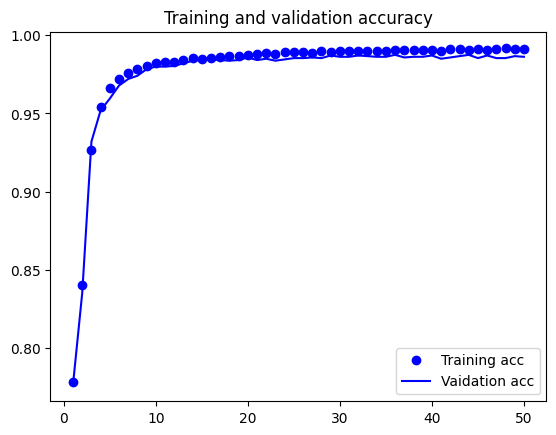

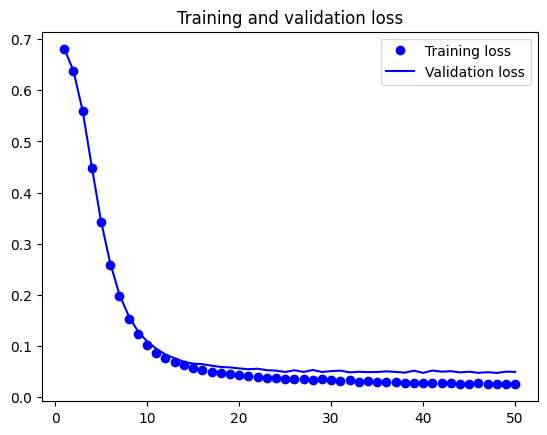

/tmp/ipykernel_423/2181039425.py:169: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_pred = model(torch.tensor(x_test).float())[0] > .5


f1-score :  0.8794567062818336
precision :  0.8779661016949153
recall :  0.8809523809523809
accuracy :  0.9678296329859538
              precision    recall  f1-score   support

           0       0.98      0.98      0.98      1913
           1       0.88      0.88      0.88       294

    accuracy                           0.97      2207
   macro avg       0.93      0.93      0.93      2207
weighted avg       0.97      0.97      0.97      2207

[[1877   36]
 [  35  259]]
final report [{'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'English-German', 'class': '0', 'precision': 0.98, 'recall': 0.98, 'f1_score': 0.98, 'support': 1913.0}, {'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'English-German', 'class': '1', 'precision': 0.88, 'recall': 0.88, 'f1_score': 0.88, 'support': 294.0, 'acc': 0.97}]

Training and evaluating on Romanian-Hungarian
epoch 0
                    Train set - loss: 0.672, accuracy: 0.847 
            

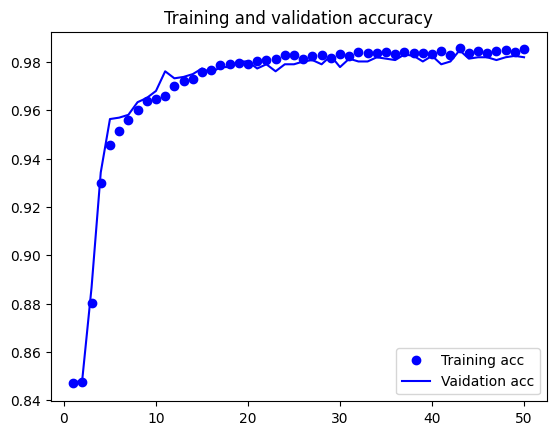

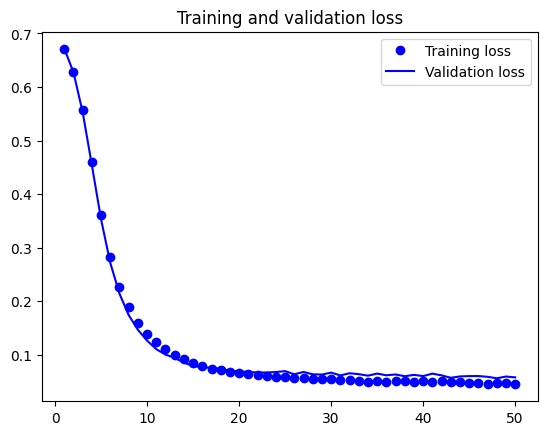

/tmp/ipykernel_423/2181039425.py:169: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_pred = model(torch.tensor(x_test).float())[0] > .5


f1-score :  0.6468646864686468
precision :  0.620253164556962
recall :  0.6758620689655173
accuracy :  0.9207407407407407
              precision    recall  f1-score   support

           0       0.96      0.95      0.96      1205
           1       0.62      0.68      0.65       145

    accuracy                           0.92      1350
   macro avg       0.79      0.81      0.80      1350
weighted avg       0.92      0.92      0.92      1350

[[1145   60]
 [  47   98]]
final report [{'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'Romanian-Hungarian', 'class': '0', 'precision': 0.96, 'recall': 0.95, 'f1_score': 0.96, 'support': 1205.0}, {'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'Romanian-Hungarian', 'class': '1', 'precision': 0.62, 'recall': 0.68, 'f1_score': 0.65, 'support': 145.0, 'acc': 0.92}]

Training and evaluating on Polish-French
epoch 0
                    Train set - loss: 0.685, accuracy: 0.793 
          

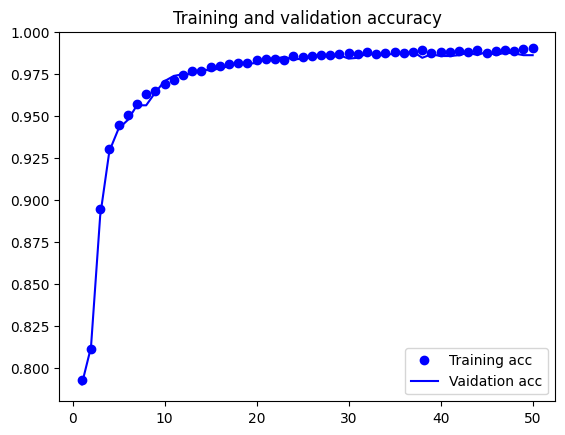

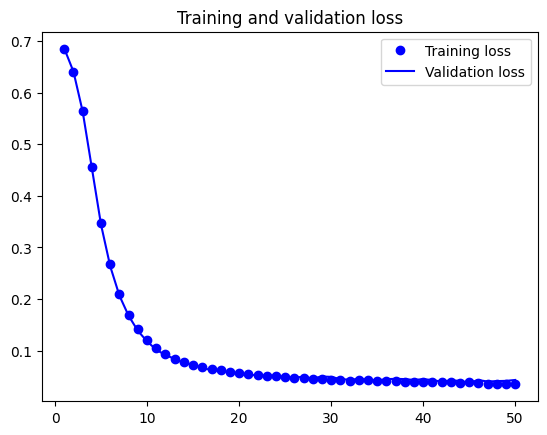

/tmp/ipykernel_423/2181039425.py:169: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_pred = model(torch.tensor(x_test).float())[0] > .5


f1-score :  0.7952941176470588
precision :  0.7681818181818182
recall :  0.824390243902439
accuracy :  0.9480597014925373
              precision    recall  f1-score   support

           0       0.98      0.97      0.97      1470
           1       0.77      0.82      0.80       205

    accuracy                           0.95      1675
   macro avg       0.87      0.89      0.88      1675
weighted avg       0.95      0.95      0.95      1675

[[1419   51]
 [  36  169]]
final report [{'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'Polish-French', 'class': '0', 'precision': 0.98, 'recall': 0.97, 'f1_score': 0.97, 'support': 1470.0}, {'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'Polish-French', 'class': '1', 'precision': 0.77, 'recall': 0.82, 'f1_score': 0.8, 'support': 205.0, 'acc': 0.95}]

Training and evaluating on Indonesian-Dutch
epoch 0
                    Train set - loss: 0.685, accuracy: 0.684 
                  

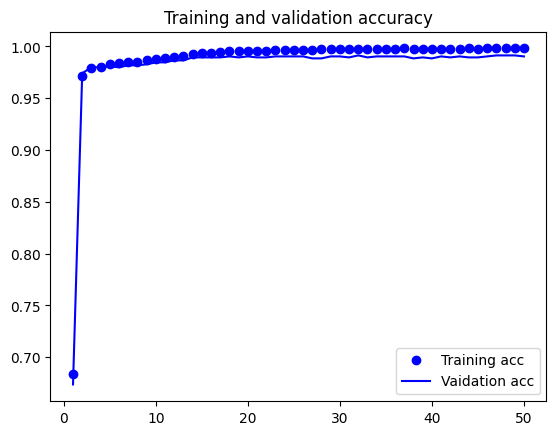

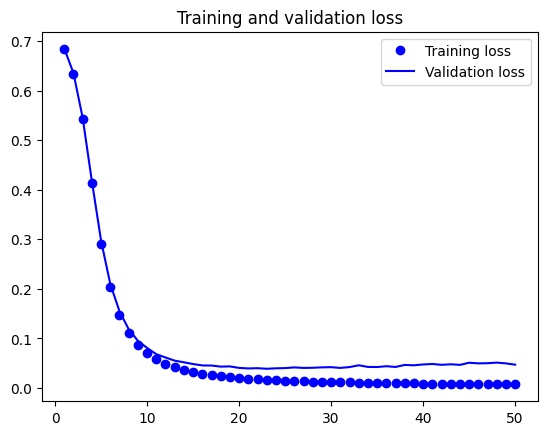

/tmp/ipykernel_423/2181039425.py:169: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_pred = model(torch.tensor(x_test).float())[0] > .5


f1-score :  0.6598726114649681
precision :  0.49903660886319845
recall :  0.9736842105263158
accuracy :  0.8596214511041009
              precision    recall  f1-score   support

           0       0.99      0.84      0.91      1636
           1       0.50      0.97      0.66       266

    accuracy                           0.86      1902
   macro avg       0.75      0.91      0.79      1902
weighted avg       0.93      0.86      0.88      1902

[[1376  260]
 [   7  259]]
final report [{'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'Indonesian-Dutch', 'class': '0', 'precision': 0.99, 'recall': 0.84, 'f1_score': 0.91, 'support': 1636.0}, {'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'Indonesian-Dutch', 'class': '1', 'precision': 0.5, 'recall': 0.97, 'f1_score': 0.66, 'support': 266.0, 'acc': 0.86}]

Training and evaluating on Romanian-French
epoch 0
                    Train set - loss: 0.686, accuracy: 0.688 
           

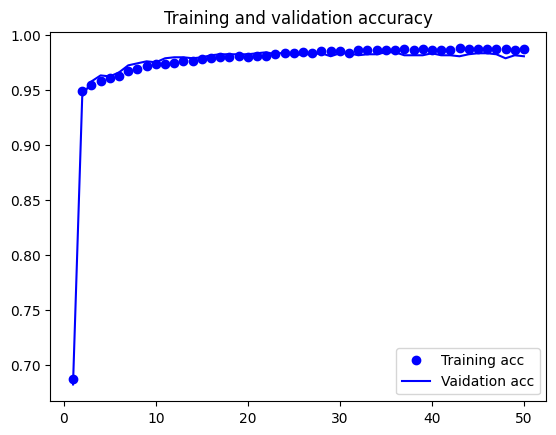

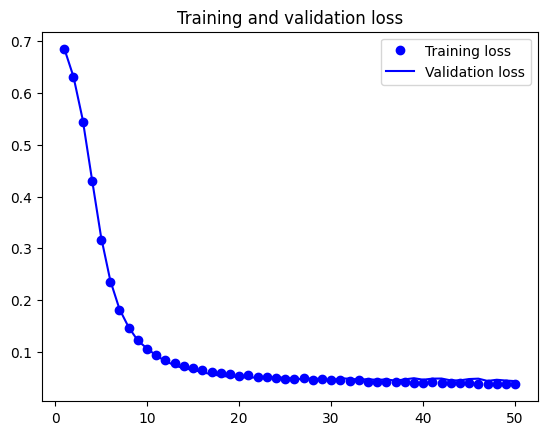

f1-score :  0.7633262260127932
precision :  0.662962962962963
recall :  0.8994974874371859
accuracy :  0.9332932692307693
              precision    recall  f1-score   support

           0       0.99      0.94      0.96      1465
           1       0.66      0.90      0.76       199

    accuracy                           0.93      1664
   macro avg       0.82      0.92      0.86      1664
weighted avg       0.95      0.93      0.94      1664

[[1374   91]
 [  20  179]]
final report [{'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'Romanian-French', 'class': '0', 'precision': 0.99, 'recall': 0.94, 'f1_score': 0.96, 'support': 1465.0}, {'all_language_evaluate': False, 'train_evaluate_pair': True, 'language_pair': 'Romanian-French', 'class': '1', 'precision': 0.66, 'recall': 0.9, 'f1_score': 0.76, 'support': 199.0, 'acc': 0.93}]


Zip ready: /content/result_zips/pruned_nn.zip  (240 KB)
    Final_results/pruned_nn/all_lang_falseneg.csv
    Final_results/pru

/tmp/ipykernel_423/2181039425.py:169: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_pred = model(torch.tensor(x_test).float())[0] > .5


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

'/content/result_zips/pruned_nn.zip'

In [18]:
train_realdist_pruned = {}

# remove any pairs in alldata testing set from realdist training set
for lang in train_realdist:
    train_realdist_pruned[lang] = train_realdist[lang][~train_realdist[lang].set_index(['loan_word','original_word']).index.\
                          isin(test_alldata[lang].set_index(['loan_word','original_word']).index)]

print("Evaluating NN on realdist (train, pruned) and alldata (test)\n")
results = nn_evaluate(train_realdist_pruned, test_alldata, pairs)
save_eval_results(pruned_dir(), *results)

### NN - holdout language pairs

In [19]:
def nn_evaluate_holdout(full_train_set, full_holdout_test_set, holdout_pairs_list):
    all_result_nn_holdout = []
    hold_out_fp=[]
    hold_out_fn =[]
    pair =None #pair None for all languages evaluation
    display_fields = ['loan_word',
              'original_word',
              'loan_word_epitran',
              'original_word_epitran',
              'loan_english',
              'original_english'] + features

    train_set = pd.concat([full_train_set[pair][display_fields + ["label"] + labels] for pair in pairs])
    x_train = train_set[features].values
    x_means = np.mean(x_train, axis=0)
    x_stds = np.std(x_train, axis=0)
    x_stds[x_stds == 0] = 1
    y_train = train_set[labels].values.ravel()

    # standardize input features
    x_train = (x_train - x_means)/x_stds

    torch.manual_seed(7)
    random.seed(7)
    np.random.seed(7)

    model = NeuralNetwork(x_train.shape[1]).to(device)
    print(model)

    criterion = nn.BCELoss().to(device)
    optimizer = optim.Adam(model.parameters(), lr=0.00001)
    #optimizer = optim.SGD(model.parameters(),lr=0.00001, momentum=0.0,  weight_decay=0.0, nesterov=False)

    x_train, x_val, y_train, y_val = train_test_split(x_train, y_train, test_size=0.2, random_state=1, stratify=y_train)

    x_train = torch.tensor(x_train).to(device)
    x_val = torch.tensor(x_val).to(device)
    y_train = torch.tensor(y_train).reshape(-1,1).to(device)
    y_val = torch.tensor(y_val).reshape(-1,1).to(device)

    print("Training on all langs\n")
    train_losses, val_losses, train_accur, val_accur = \
        model.fit(x_train, y_train, x_val, y_val, criterion, optimizer, n_epochs=5000)
    model.plot_losses(train_losses,val_losses,train_accur,val_accur)

    model.eval()

    with torch.no_grad():
        for pair in holdout_pairs_list:
            print(f'Evaluating on {pair}')

            test_set = full_holdout_test_set[pair][display_fields + ["label"] + labels]
            x_test = test_set[features].values
            y_test = test_set[labels].values.ravel()

            x_test = (x_test - x_means)/x_stds
            x_test = torch.tensor(x_test).to(device)
            y_pred = model(torch.tensor(x_test).float())[0] > .5
            y_pred = y_pred.detach().cpu().numpy()

            print("f1-score : ", f1_score(y_test, y_pred ))
            print("precision : ",precision_score(y_test, y_pred))
            print("recall : ",recall_score(y_test, y_pred ))
            print("accuracy : ",accuracy_score(y_test, y_pred))
            print(classification_report(y_test, y_pred))
            print(confusion_matrix(y_test, y_pred))
            class_report = classification_report(y_test, y_pred)
            a = classification_report_csv(class_report,pair,all_lang=False, train_evaluate_pair =False)
            all_result_nn_holdout.append(a)
            print()

            # display false positives and false negatives
            unq = np.array([x + 2*y for x, y in zip(y_pred, y_test)])
            tp = np.array(np.where(unq == 3)).tolist()[0]
            fp = np.array(np.where(unq == 1)).tolist()[0]
            tn = np.array(np.where(unq == 0)).tolist()[0]
            fn = np.array(np.where(unq == 2)).tolist()[0]

            display(test_set.reset_index(drop=True).iloc[fp,:][display_fields + ["label"]].style.set_caption('False positives'))
            display(test_set.reset_index(drop=True).iloc[fn,:][display_fields + ["label"]].style.set_caption('False negatives'))
            holdout_evaluate_lang_fp = test_set.reset_index(drop=True).iloc[fp,:][display_fields + ["label"]]
            holdout_evaluate_lang_fn = test_set.reset_index(drop=True).iloc[fn,:][display_fields + ["label"]]
            #holdout_evaluate_lang_fp['language_pair'] = pair
            #holdout_evaluate_lang_fn['language_pair'] = pair
            holdout_evaluate_lang_fp.insert(0, 'language_pair', pair)
            holdout_evaluate_lang_fn.insert(0, 'language_pair', pair)
            hold_out_fp.append(holdout_evaluate_lang_fp)
            hold_out_fn.append(holdout_evaluate_lang_fn)
    holdout_evaluate_lang_fp = pd.concat(hold_out_fp, ignore_index=True)
    holdout_evaluate_lang_fn = pd.concat(hold_out_fn, ignore_index=True)
    final_result = pd.concat(all_result_nn_holdout, ignore_index=True)
    return final_result, holdout_evaluate_lang_fp,holdout_evaluate_lang_fn


In [27]:
uploaded = files.upload()
del uploaded
PAIRS_JSON = "language-pairs.json"
HOLDOUT_JSON = "language-pairs-holdout.json"
assert os.path.exists(PAIRS_JSON), "language-pairs.json was not uploaded"

Saving language-pairs-holdout.json to language-pairs-holdout.json


In [28]:
assert os.path.exists(HOLDOUT_JSON), "Upload language-pairs-holdout.json first (re-run the json upload cell)"
with open(HOLDOUT_JSON, "r") as f:
    pairs_holdout = json.load(f)
print(list(pairs_holdout))

test_holdout_alldata, test_holdout_realdist, test_holdout_balanced = {}, {}, {}

for pair in pairs_holdout:
    print(pair)
    L1 = pairs_holdout[pair]["target"]["name"]
    L2 = pairs_holdout[pair]["source"]["name"]
    prefix = f"{DATA_DIR}/{L1}-{L2}"

    test_holdout_alldata[f"{L1}-{L2}"] = pd.read_csv(f"{prefix}/alldata/{L1}-{L2}-test_production_alldata.csv")
    test_holdout_realdist[f"{L1}-{L2}"] = pd.read_csv(f"{prefix}/realdist/{L1}-{L2}-test_production_realdist.csv")
    test_holdout_balanced[f"{L1}-{L2}"] = pd.read_csv(f"{prefix}/balanced/{L1}-{L2}-test_production_balanced.csv")

for split_dict in (test_holdout_alldata, test_holdout_realdist, test_holdout_balanced):
    for k in split_dict:
        split_dict[k] = add_unicode_onehots(split_dict[k])

['Persian-Arabic', 'Hungarian-German', 'German-Italian', 'Catalan-Arabic']
Persian-Arabic


FileNotFoundError: [Errno 2] No such file or directory: '/content/loanword_data/production_train_test/Persian-Arabic/alldata/Persian-Arabic-test_production_alldata.csv'

#### NN holdout - all_data

In [ ]:
print("Evaluating NN holdout on all_data splits\n")
output_holdout, holdout_fp, holdout_fn = nn_evaluate_holdout(train_alldata, test_holdout_alldata, pairs_holdout)
save_holdout_results(holdout_dir("all_data"), output_holdout, holdout_fp, holdout_fn)

#### NN holdout - real_dist

In [ ]:
print("Evaluating NN holdout on real_dist splits\n")
output_holdout, holdout_fp, holdout_fn = nn_evaluate_holdout(train_realdist, test_holdout_realdist, pairs_holdout)
save_holdout_results(holdout_dir("real_dist"), output_holdout, holdout_fp, holdout_fn)

#### NN holdout - balanced

In [ ]:
print("Evaluating NN holdout on balanced splits\n")
output_holdout, holdout_fp, holdout_fn = nn_evaluate_holdout(train_balanced, test_holdout_balanced, pairs_holdout)
save_holdout_results(holdout_dir("balanced"), output_holdout, holdout_fp, holdout_fn)

# SVM classifier

In [29]:
def svm_evaluate(full_train_set, full_test_set, pairs_list):
    pair ='All_languages'

    all_result = []
    all_lang_fp_list= []
    all_lang_fn_list=[]
    evaluate_lang_fp_list = []
    evaluate_lang_fn_list = []
    train_evaluate_lang_fp_list = []
    train_evaluate_lang_fn_list = []
    weights_list = []
    display_fields = ['loan_word',
              'original_word',
              'loan_word_epitran',
              'original_word_epitran',
              'loan_english',
              'original_english'] + features

    train_set = pd.concat([full_train_set[pair][display_fields + ["label"] + labels] for pair in pairs])
    x_train = train_set[features].values
    x_means = np.mean(x_train, axis=0)
    x_stds = np.std(x_train, axis=0)
    x_stds[x_stds == 0] = 1
    y_train = train_set[labels].values.ravel()

    test_set = pd.concat([full_test_set[pair][display_fields + ["label"] + labels] for pair in pairs])
    x_test = test_set[features].values
    y_test = test_set[labels].values.ravel()

    # standardize input features
    x_train = (x_train - x_means)/x_stds

    print("Training on all langs\n")

    SVM = SVC(kernel='linear')
    SVM.fit(x_train, y_train)

    # display regressor weights
    df = pd.DataFrame(SVM.coef_, columns=features).style.set_caption('Weights')
    df_weights = pd.DataFrame(SVM.coef_, columns=features)

    df_weights.insert(0, 'language_pair', pair)

    weights_list.append(df_weights)
    display(df)
    print()

    print("Evaluating on all langs")
    x_test = (x_test - x_means)/x_stds
    y_pred = SVM.predict(x_test)

    print("f1-score : ", f1_score(y_test, y_pred ))
    print("precision : ",precision_score(y_test, y_pred))
    print("recall : ",recall_score(y_test, y_pred ))
    print("accuracy : ",accuracy_score(y_test, y_pred))
    print(classification_report(y_test, y_pred))
    print(confusion_matrix(y_test, y_pred))
    class_report = classification_report(y_test, y_pred)
    a = classification_report_csv(class_report,pair,all_lang=True, train_evaluate_pair =False)
    all_result.append(a)
    print()

    # display false positives and false negatives
    unq = np.array([x + 2*y for x, y in zip(y_pred, y_test)])
    tp = np.array(np.where(unq == 3)).tolist()[0]
    fp = np.array(np.where(unq == 1)).tolist()[0]
    tn = np.array(np.where(unq == 0)).tolist()[0]
    fn = np.array(np.where(unq == 2)).tolist()[0]

    #display(test_set.reset_index(drop=True).iloc[fp,:][display_fields + ["label"]].style.set_caption('False positives'))
    #display(test_set.reset_index(drop=True).iloc[fn,:][display_fields + ["label"]].style.set_caption('False negatives'))
    all_lang_fp = test_set.reset_index(drop=True).iloc[fp,:][display_fields + ["label"]]
    all_lang_fn = test_set.reset_index(drop=True).iloc[fn,:][display_fields + ["label"]]

    all_lang_fp.insert(0, 'language_pair', pair)
    all_lang_fn.insert(0, 'language_pair', pair)
    all_lang_fp_list.append(all_lang_fp)
    all_lang_fn_list.append(all_lang_fn)

    for pair in pairs_list:
        print(f'Evaluating on {pair}')

        test_set = full_test_set[pair][display_fields + ["label"] + labels]
        x_test = test_set[features].values
        y_test = test_set[labels].values.ravel()

        x_test = (x_test - x_means)/x_stds
        y_pred = SVM.predict(x_test)

        print("f1-score : ", f1_score(y_test, y_pred ))
        print("precision : ",precision_score(y_test, y_pred))
        print("recall : ",recall_score(y_test, y_pred ))
        print("accuracy : ",accuracy_score(y_test, y_pred))
        print(classification_report(y_test, y_pred))
        print(confusion_matrix(y_test, y_pred))
        class_report = classification_report(y_test, y_pred)
        a = classification_report_csv(class_report,pair,all_lang=False, train_evaluate_pair =False)
        all_result.append(a)
        print()

        # display false positives and false negatives
        unq = np.array([x + 2*y for x, y in zip(y_pred, y_test)])
        tp = np.array(np.where(unq == 3)).tolist()[0]
        fp = np.array(np.where(unq == 1)).tolist()[0]
        tn = np.array(np.where(unq == 0)).tolist()[0]
        fn = np.array(np.where(unq == 2)).tolist()[0]

        #display(test_set.reset_index(drop=True).iloc[fp,:][display_fields + ["label"]].style.set_caption('False positives'))
        #display(test_set.reset_index(drop=True).iloc[fn,:][display_fields + ["label"]] .style.set_caption('False negatives'))
        evaluate_lang_fp = test_set.reset_index(drop=True).iloc[fp,:][display_fields + ["label"]]
        evaluate_lang_fn = test_set.reset_index(drop=True).iloc[fn,:][display_fields + ["label"]]

        evaluate_lang_fp.insert(0, 'language_pair', pair)
        evaluate_lang_fn.insert(0, 'language_pair', pair)
        evaluate_lang_fp_list.append(evaluate_lang_fp)
        evaluate_lang_fn_list.append(evaluate_lang_fn)
    for pair in pairs_list:
        print(f'Training and evaluating on {pair}')

        train_set = full_train_set[pair][display_fields + ["label"] + labels]
        x_train = train_set[features].values
        x_means = np.mean(x_train, axis=0)
        x_stds = np.std(x_train, axis=0)
        x_stds[x_stds == 0] = 1
        y_train = train_set[labels].values.ravel()

        test_set = full_test_set[pair][display_fields + ["label"] + labels]
        x_test = test_set[features].values
        y_test = test_set[labels].values.ravel()

        x_train = (x_train - x_means)/x_stds

        SVM = SVC(kernel='linear')
        SVM.fit(x_train, y_train)

        # display regressor weights
        df = pd.DataFrame(SVM.coef_, columns=features).style.set_caption('Weights')
        df_weights = pd.DataFrame(SVM.coef_, columns=features)

        df_weights.insert(0, 'language_pair', pair)

        weights_list.append(df_weights)
        display(df)

        x_test = (x_test - x_means)/x_stds
        y_pred = SVM.predict(x_test)

        print("f1-score : ", f1_score(y_test, y_pred ))
        print("precision : ",precision_score(y_test, y_pred))
        print("recall : ",recall_score(y_test, y_pred ))
        print("accuracy : ",accuracy_score(y_test, y_pred))
        print(classification_report(y_test, y_pred))
        print(confusion_matrix(y_test, y_pred))
        class_report = classification_report(y_test, y_pred)
        a = classification_report_csv(class_report,pair,all_lang=False,train_evaluate_pair =True)
        all_result.append(a)
        print()

        # display false positives and false negatives
        unq = np.array([x + 2*y for x, y in zip(y_pred, y_test)])
        tp = np.array(np.where(unq == 3)).tolist()[0]
        fp = np.array(np.where(unq == 1)).tolist()[0]
        tn = np.array(np.where(unq == 0)).tolist()[0]
        fn = np.array(np.where(unq == 2)).tolist()[0]

        #display(test_set.reset_index(drop=True).iloc[fp,:][display_fields + ["label"]].style.set_caption('False positives'))
        #display(test_set.reset_index(drop=True).iloc[fn,:][display_fields + ["label"]].style.set_caption('False negatives'))
        train_evaluate_lang_fp = test_set.reset_index(drop=True).iloc[fp,:][display_fields + ["label"]]
        train_evaluate_lang_fn = test_set.reset_index(drop=True).iloc[fn,:][display_fields + ["label"]]

        train_evaluate_lang_fp.insert(0, 'language_pair', pair)
        train_evaluate_lang_fn.insert(0, 'language_pair', pair)
        train_evaluate_lang_fp_list.append(train_evaluate_lang_fp)
        train_evaluate_lang_fn_list.append(train_evaluate_lang_fn)

    final_result = pd.concat(all_result, ignore_index=True)
    all_lang_fp_list = pd.concat(all_lang_fp_list, ignore_index=True)
    all_lang_fn_list = pd.concat(all_lang_fn_list, ignore_index=True)
    evaluate_lang_fp_list = pd.concat(evaluate_lang_fp_list, ignore_index=True)
    evaluate_lang_fn_list = pd.concat(evaluate_lang_fn_list, ignore_index=True)
    train_evaluate_lang_fp_list = pd.concat(train_evaluate_lang_fp_list, ignore_index=True)
    train_evaluate_lang_fn_list = pd.concat(train_evaluate_lang_fn_list, ignore_index=True)
    weights = pd.concat(weights_list, ignore_index=True)

    return final_result, all_lang_fp_list, all_lang_fn_list, evaluate_lang_fp_list, evaluate_lang_fn_list, train_evaluate_lang_fp_list, train_evaluate_lang_fn_list, weights



### SVM - all_data

In [ ]:
print("Evaluating SVM on all_data splits\n")
results = svm_evaluate(train_alldata, test_alldata, pairs)
save_eval_results(result_dir("all_data", "SVM"), *results, weights_name="SVM_weights.csv")

Evaluating SVM on all_data splits

Training on all langs



### SVM - real_dist

In [ ]:
print("Evaluating SVM on real_dist splits\n")
results = svm_evaluate(train_realdist, test_realdist, pairs)
save_eval_results(result_dir("real_dist", "SVM"), *results, weights_name="SVM_weights.csv")

### SVM - balanced

In [ ]:
print("Evaluating SVM on balanced splits\n")
results = svm_evaluate(train_balanced, test_balanced, pairs)
save_eval_results(result_dir("balanced", "SVM"), *results, weights_name="SVM_weights.csv")

# Random Forest classifier

In [ ]:
def rf_evaluate(full_train_set, full_test_set, pairs_list):
    all_result = []
    all_lang_fp_list= []
    all_lang_fn_list=[]
    evaluate_lang_fp_list = []
    evaluate_lang_fn_list = []
    train_evaluate_lang_fp_list = []
    train_evaluate_lang_fn_list = []
    pair =None #pair None for all languages evaluation
    display_fields = ['loan_word',
              'original_word',
              'loan_word_epitran',
              'original_word_epitran',
              'loan_english',
              'original_english'] + features

    train_set = pd.concat([full_train_set[pair][display_fields + ["label"] + labels] for pair in pairs])
    x_train = train_set[features].values
    x_means = np.mean(x_train, axis=0)
    x_stds = np.std(x_train, axis=0)
    x_stds[x_stds == 0] = 1
    y_train = train_set[labels].values.ravel()

    test_set = pd.concat([full_test_set[pair][display_fields + ["label"] + labels] for pair in pairs])
    x_test = test_set[features].values
    y_test = test_set[labels].values.ravel()

    # standardize input features
    x_train = (x_train - x_means)/x_stds

    print("Training on all langs\n")

    RF = RandomForestClassifier(n_estimators=1000, max_depth=5, random_state=0)
    RF.fit(x_train, y_train)
#     num_leafs = [1, 5, 10, 20, 50, 100]
#     parameters3 = [{'n_estimators' : range(100,800,20),
#              'max_depth': range(1,20,5),
#              'min_samples_leaf':num_leafs
#              }]

#     gs3 = GridSearchCV(estimator=RF,
#                   param_grid=parameters3,
#                   cv = 10,
#                   n_jobs = -1)

#     gs3.fit(x_train, y_train)

    # display regressor weights
    #df = pd.DataFrame(RF.best_params_, columns=features).style.set_caption('Weights')
    #display(df)
    print()

    print("Evaluating on all langs")
    x_test = (x_test - x_means)/x_stds
    y_pred = RF.predict(x_test)

    print("f1-score : ", f1_score(y_test, y_pred ))
    print("precision : ",precision_score(y_test, y_pred))
    print("recall : ",recall_score(y_test, y_pred ))
    print("accuracy : ",accuracy_score(y_test, y_pred))
    print(classification_report(y_test, y_pred))
    print(confusion_matrix(y_test, y_pred))
    class_report = classification_report(y_test, y_pred)
    a = classification_report_csv(class_report,pair,all_lang=True, train_evaluate_pair =False)
    all_result.append(a)
    print()

    # display false positives and false negatives
    unq = np.array([x + 2*y for x, y in zip(y_pred, y_test)])
    tp = np.array(np.where(unq == 3)).tolist()[0]
    fp = np.array(np.where(unq == 1)).tolist()[0]
    tn = np.array(np.where(unq == 0)).tolist()[0]
    fn = np.array(np.where(unq == 2)).tolist()[0]

    display(test_set.reset_index(drop=True).iloc[fp,:][display_fields + ["label"]].style.set_caption('False positives'))
    display(test_set.reset_index(drop=True).iloc[fn,:][display_fields + ["label"]].style.set_caption('False negatives'))
    all_lang_fp = test_set.reset_index(drop=True).iloc[fp,:][display_fields + ["label"]]
    all_lang_fn = test_set.reset_index(drop=True).iloc[fn,:][display_fields + ["label"]]
    all_lang_fp.insert(0, 'language_pair', pair)
    all_lang_fn.insert(0, 'language_pair', pair)
    all_lang_fp_list.append(all_lang_fp)
    all_lang_fn_list.append(all_lang_fn)

    for pair in pairs_list:
        print(f'Evaluating on {pair}')

        test_set = full_test_set[pair][display_fields + ["label"] + labels]
        x_test = test_set[features].values
        y_test = test_set[labels].values.ravel()

        x_test = (x_test - x_means)/x_stds
        y_pred = RF.predict(x_test)

        print("f1-score : ", f1_score(y_test, y_pred ))
        print("precision : ",precision_score(y_test, y_pred))
        print("recall : ",recall_score(y_test, y_pred ))
        print("accuracy : ",accuracy_score(y_test, y_pred))
        print(classification_report(y_test, y_pred))
        print(confusion_matrix(y_test, y_pred))
        class_report = classification_report(y_test, y_pred)
        a = classification_report_csv(class_report,pair,all_lang=False, train_evaluate_pair =False)
        all_result.append(a)
        print()

        # display false positives and false negatives
        unq = np.array([x + 2*y for x, y in zip(y_pred, y_test)])
        tp = np.array(np.where(unq == 3)).tolist()[0]
        fp = np.array(np.where(unq == 1)).tolist()[0]
        tn = np.array(np.where(unq == 0)).tolist()[0]
        fn = np.array(np.where(unq == 2)).tolist()[0]

        display(test_set.reset_index(drop=True).iloc[fp,:][display_fields + ["label"]].style.set_caption('False positives'))
        display(test_set.reset_index(drop=True).iloc[fn,:][display_fields + ["label"]].style.set_caption('False negatives'))

        evaluate_lang_fp = test_set.reset_index(drop=True).iloc[fp,:][display_fields + ["label"]]
        evaluate_lang_fn = test_set.reset_index(drop=True).iloc[fn,:][display_fields + ["label"]]
        evaluate_lang_fp.insert(0, 'language_pair', pair)
        evaluate_lang_fn.insert(0, 'language_pair', pair)
        evaluate_lang_fp_list.append(evaluate_lang_fp)
        evaluate_lang_fn_list.append(evaluate_lang_fn)

    for pair in pairs_list:
        print(f'Training and evaluating on {pair}')

        train_set = full_train_set[pair][display_fields + ["label"] + labels]
        x_train = train_set[features].values
        x_means = np.mean(x_train, axis=0)
        x_stds = np.std(x_train, axis=0)
        x_stds[x_stds == 0] = 1
        y_train = train_set[labels].values.ravel()

        test_set = full_test_set[pair][display_fields + ["label"] + labels]
        x_test = test_set[features].values
        y_test = test_set[labels].values.ravel()

        x_train = (x_train - x_means)/x_stds

        RF = RandomForestClassifier(n_estimators=1000, max_depth=5, random_state=0)
        RF.fit(x_train, y_train)
#         num_leafs = [1, 5, 10, 20, 50, 100]
#         parameters3 = [{'n_estimators' : range(100,800,20),
#              'max_depth': range(1,20,5),
#              'min_samples_leaf':num_leafs
#              }]

#         gs3 = GridSearchCV(estimator=RF,
#                   param_grid=parameters3,
#                   cv = 10,
#                   n_jobs = -1)

#         gs3.fit(x_train, y_train)

        # display regressor weights
        #df = pd.DataFrame(RF.best_params_, columns=features).style.set_caption('Weights')
        #display(df)

        x_test = (x_test - x_means)/x_stds
        y_pred = RF.predict(x_test)

        print("f1-score : ", f1_score(y_test, y_pred ))
        print("precision : ",precision_score(y_test, y_pred))
        print("recall : ",recall_score(y_test, y_pred ))
        print("accuracy : ",accuracy_score(y_test, y_pred))
        print(classification_report(y_test, y_pred))
        print(confusion_matrix(y_test, y_pred))
        class_report = classification_report(y_test, y_pred)
        a = classification_report_csv(class_report,pair,all_lang=False,train_evaluate_pair =True)
        all_result.append(a)
        print()

        # display false positives and false negatives
        unq = np.array([x + 2*y for x, y in zip(y_pred, y_test)])
        tp = np.array(np.where(unq == 3)).tolist()[0]
        fp = np.array(np.where(unq == 1)).tolist()[0]
        tn = np.array(np.where(unq == 0)).tolist()[0]
        fn = np.array(np.where(unq == 2)).tolist()[0]

        display(test_set.reset_index(drop=True).iloc[fp,:][display_fields + ["label"]].style.set_caption('False positives'))
        display(test_set.reset_index(drop=True).iloc[fn,:][display_fields + ["label"]].style.set_caption('False negatives'))
        train_evaluate_lang_fp = test_set.reset_index(drop=True).iloc[fp,:][display_fields + ["label"]]
        train_evaluate_lang_fn = test_set.reset_index(drop=True).iloc[fn,:][display_fields + ["label"]]
        train_evaluate_lang_fp.insert(0, 'language_pair', pair)
        train_evaluate_lang_fn.insert(0, 'language_pair', pair)
        train_evaluate_lang_fp_list.append(train_evaluate_lang_fp)
        train_evaluate_lang_fn_list.append(train_evaluate_lang_fn)
    final_result = pd.concat(all_result, ignore_index=True)
    all_lang_fp_list = pd.concat(all_lang_fp_list, ignore_index=True)
    all_lang_fn_list = pd.concat(all_lang_fn_list, ignore_index=True)
    evaluate_lang_fp_list = pd.concat(evaluate_lang_fp_list, ignore_index=True)
    evaluate_lang_fn_list = pd.concat(evaluate_lang_fn_list, ignore_index=True)
    train_evaluate_lang_fp_list = pd.concat(train_evaluate_lang_fp_list, ignore_index=True)
    train_evaluate_lang_fn_list = pd.concat(train_evaluate_lang_fn_list, ignore_index=True)

    return final_result, all_lang_fp_list, all_lang_fn_list, evaluate_lang_fp_list, evaluate_lang_fn_list, train_evaluate_lang_fp_list, train_evaluate_lang_fn_list

### RF - all_data

In [ ]:
print("Evaluating RF on all_data splits\n")
results = rf_evaluate(train_alldata, test_alldata, pairs)
save_eval_results(result_dir("all_data", "RF"), *results)

### RF - real_dist

In [ ]:
print("Evaluating RF on real_dist splits\n")
results = rf_evaluate(train_realdist, test_realdist, pairs)
save_eval_results(result_dir("real_dist", "RF"), *results)

### RF - balanced

In [ ]:
print("Evaluating RF on balanced splits\n")
results = rf_evaluate(train_balanced, test_balanced, pairs)
save_eval_results(result_dir("balanced", "RF"), *results)

# Optional: download everything produced in this session
Only run this if you really want the full results tree in one zip (it is **not** run automatically).

In [ ]:
full_zip = shutil.make_archive(os.path.join(ZIP_DIR, f"{RESULTS_DIRNAME}_full_session"),
                               "zip", root_dir=OUT_BASE, base_dir=RESULTS_DIRNAME)
print(full_zip, f"{os.path.getsize(full_zip)/1e6:.1f} MB")
if IN_COLAB:
    files.download(full_zip)